# NB02 GPU — Corrida experimental / Optuna / provisional

**Estatus:** experimental  
**Objetivo:** explorar una corrida GPU con Optuna sobre el mismo problema temporal de NB02 CPU, sin sustituir el benchmark canónico.  
**Inputs mínimos:** `data/processed/wti_volatilidad_MODEL_BASE.csv`, `config/config_estudio_FINAL.json` y, si existen, artefactos complementarios de NB03A y NB03B.  
**Outputs principales:** predicciones GPU, figuras, artefactos de Optuna y actualización de `nb02_experiments`.  
**Config / gobernanza:** este notebook escribe solo la capa experimental `nb02_experiments`; preserva `nb02_results`.  
**No inferir de este notebook:** sus resultados no reemplazan ni responden por sí solos el benchmark canónico H0-H3 del paper.

> **Nota de alcance:** su propósito es exploración GPU/Optuna y sensibilidad de hiperparámetros. La referencia oficial del benchmark sigue siendo NB02 CPU.

**Contrato de config (runtime Colab):** NB02 GPU usa `BASE_PATH/config_estudio_FINAL.json` como ruta real de runtime. El archivo del repo `config/config_estudio_FINAL.json` es un espejo sincronizado después de la corrida.  
**Orden oficial:** `NB01 -> NB03A (si aprobado) -> NB03B (si aprobado) -> NB02 CPU -> NB02 GPU opcional`. NB02 GPU nunca forma parte del flujo canónico obligatorio.  
**Guardia de escritura:** este notebook solo actualiza `nb02_experiments` y hace `skip` si no existe una capa canónica válida en `nb02_results`.


## 0.1 IMPORTAR LIBRERÍAS Y VERIFICAR ENTORNO

In [ ]:
import os
os.environ['TF_DETERMINISTIC_OPS'] = '1'

# ── Modo de ejecución — editar aquí antes de cada corrida
# 'canonical_cpu' : corrida oficial (TF_DETERMINISTIC_OPS=1, WRITE_CONFIG=True)
# 'gpu_optuna'    : exploración GPU/Optuna (WRITE_CONFIG=False, resultados PROVISIONAL)
RUN_MODE = 'gpu_optuna'      # default seguro: corrida experimental GPU

# Propagar al entorno para herramientas externas y para WRITE_CONFIG de celda 85
os.environ['NB02B_RUN_MODE'] = RUN_MODE
print(f"[CONFIG] NB02B_RUN_MODE = {RUN_MODE}  (GPU provisional, no canónico)")

[CONFIG] NB02B_RUN_MODE = gpu_optuna  (GPU provisional, no canónico)


In [ ]:
# ── Instalación arch con recompilación forzada ─────
# Evita el error "numpy.dtype size changed" de wheels precompiladas.
# Guard autosuficiente: detecta Colab sin depender de IN_COLAB (aún no definido).
import subprocess
try:
    import google.colab as _gc
    _IN_COLAB_INSTALL = True
except ImportError:
    _IN_COLAB_INSTALL = False

if _IN_COLAB_INSTALL:
    subprocess.run(
        ['pip', 'install', 'arch', '--no-binary', 'arch', '-q'],
        check=True
    )
else:
    try:
        import arch as _arch_test
        print(f"arch ya instalado: {_arch_test.__version__}")
    except ImportError:
        print("WARN: arch no instalado. Ejecutar manualmente: pip install arch --no-binary arch")

# Limpiar módulo cacheado si ya estaba importado en esta sesión
import sys
for mod in list(sys.modules.keys()):
    if 'arch' in mod:
        del sys.modules[mod]

# Importar y verificar
import arch
import numpy as np

print(f"arch version  : {arch.__version__}")
print(f"numpy version : {np.__version__}")
assert int(arch.__version__.split('.')[0]) >= 5, \
    f"Versión insuficiente: {arch.__version__}. Se requiere >= 5.x"
print("arch OK ✓")

arch version  : 8.0.0
numpy version : 2.0.2
arch OK ✓


In [ ]:
# ── Backend inline: garantiza figuras embebidas en cell outputs (Colab + Jupyter) ──
# Debe ejecutarse ANTES de cualquier import de matplotlib.
# En Colab está activo por defecto; aquí lo forzamos para garantizar
# que figuras sean visibles al abrir el notebook sin re-ejecutar.
%matplotlib inline
import matplotlib
matplotlib.rcParams["figure.max_open_warning"] = 40  # silencia warning de figuras abiertas


In [ ]:
# ─── 0.2 Imports y patrón Colab ─
import json, random, warnings, pickle
#import sys
from datetime import datetime
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
import matplotlib.dates as mdates
import seaborn as sns
import scipy
import scipy.stats as stats
from scipy.stats import norm
# Sklearn
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    f1_score, roc_auc_score, precision_score, recall_score,
    confusion_matrix, roc_curve, precision_recall_curve,
    average_precision_score
)
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import TimeSeriesSplit

# Imbalanced-learn
# from imblearn.over_sampling import SMOTE
# SMOTE prohibido: rompe estructura temporal. Usar class_weight.

# GARCH (arch package)
from arch import arch_model
from statsmodels.stats.diagnostic import het_arch, acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf
import statsmodels.api as sm

# TensorFlow / Keras —
# Modo de ejecución:
# - canonical_cpu: benchmark canónico, reproducible, CPU-only (por defecto)
# - gpu_optuna:    runtime GPU dedicado para acelerar PARTE VIII
import os
RUN_MODE      = os.environ.get('NB02B_RUN_MODE', 'gpu_optuna')  # fallback: este notebook es siempre GPU/experimental
PART_VIII_GPU = (RUN_MODE == 'gpu_optuna')
if PART_VIII_GPU:
    os.environ.pop('CUDA_VISIBLE_DEVICES', None)
    os.environ['TF_DETERMINISTIC_OPS'] = '0'
else:
    os.environ['CUDA_VISIBLE_DEVICES'] = ''
    os.environ['TF_DETERMINISTIC_OPS'] = '1'
import tensorflow as tf
from tensorflow import keras
print(f"TF version     : {tf.__version__}")
print(f"Fecha ejecución: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")

TF version     : 2.19.0
Fecha ejecución: 2026-03-29 13:02:46


In [ ]:
# ─── 0.3 Seeds de reproducibilidad (TODAS las fuentes)
import sys as _sys
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)
os.environ['PYTHONHASHSEED'] = str(RANDOM_SEED)
_gpus = tf.config.list_physical_devices("GPU")
_det = "N/A"
if PART_VIII_GPU:
    for gpu in _gpus:
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except Exception:
            pass
    print(f'[ACELERACIÓN] GPUs visibles: {len(_gpus)} (esperado: >=1 en runtime GPU)')
    assert len(_gpus) >= 1, (
        'RUN_MODE=gpu_optuna, pero TensorFlow no detecta GPU. '
        'Reinicia el runtime con T4 antes de ejecutar el notebook.'
    )
else:
    print(f'[REPRODUCIBILIDAD] GPUs visibles: {len(_gpus)} (esperado: 0 — CPU-only)')
    assert len(_gpus) == 0, (
        'GPU detectada. Reiniciar runtime con CUDA_VISIBLE_DEVICES= antes de '
        'importar TF para garantizar reproducibilidad bit-a-bit.'
    )
    try:
        tf.config.experimental.enable_op_determinism()
        _det = "ON"
    except Exception:
        _det = "OFF (TF < 2.9)"
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option('display.float_format', '{:.6f}'.format)
print(f"RANDOM_SEED={RANDOM_SEED} | TF={tf.__version__} | "
      f"Python={_sys.version.split()[0]} | GPUs={len(_gpus)} | "
      f"determinism={_det} | RUN_MODE={RUN_MODE}")


[ACELERACIÓN] GPUs visibles: 1 (esperado: >=1 en runtime GPU)
RANDOM_SEED=42 | TF=2.19.0 | Python=3.12.13 | GPUs=1 | determinism=N/A | RUN_MODE=gpu_optuna


In [ ]:
# ─── 0.4 Versiones del entorno (reproducibilidad) ─
print("  ENTORNO DE EJECUCIÓN — NB02B WTI Benchmark Optimización Bayesiana GPU.")
print(f" \nPython          : {sys.version.split()[0]}")
print(f"  numpy           : {np.__version__}")
print(f"  pandas          : {pd.__version__}")
print(f"  tensorflow      : {tf.__version__}")
print(f"  arch            : {arch.__version__}")
print(f"  scikit-learn    : {sklearn.__version__}")
print(f"  statsmodels     : {sm.__version__}")
print(f"  scipy           : {scipy.__version__}")
print(f"  matplotlib      : {mpl.__version__}")
print(f"  seaborn         : {sns.__version__}")

  ENTORNO DE EJECUCIÓN — NB02B WTI Benchmark Optimización Bayesiana GPU.
 
Python          : 3.12.13
  numpy           : 2.0.2
  pandas          : 2.2.2
  tensorflow      : 2.19.0
  arch            : 8.0.0
  scikit-learn    : 1.6.1
  statsmodels     : 0.14.6
  scipy           : 1.16.3
  matplotlib      : 3.10.0
  seaborn         : 0.13.2


In [ ]:
# ─── 0.5 Rutas, detección de entorno y guards de integridad ───

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

print(f"IN_COLAB : {IN_COLAB}")

if IN_COLAB:
    try:
        drive.mount('/content/drive', force_remount=False)
    except Exception as e:
        print(f"Drive ya montado o error: {e}")
    BASE_PATH   = "/content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos"
    NB02B_PATH  = "/content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/Optimización_Bayesiana_GPU"
    OUTPUT_PATH = NB02B_PATH
    FIG_PATH    = f"{NB02B_PATH}/Fig_NB02B"
    PRED_DIR    = f"{NB02B_PATH}/predicciones_nb02b_gpu"
    OPTUNA_DIR  = f"{NB02B_PATH}/optuna_nb02b_gpu"
    MODEL_DIR   = f"{NB02B_PATH}/modelos_nb02b_gpu"
    METRICS_DIR = f"{NB02B_PATH}/metricas_nb02b_gpu"
else:
    BASE_PATH   = "."
    OUTPUT_PATH = "."
    NB02B_PATH  = "."
    FIG_PATH    = "./Fig_NB02B"
    PRED_DIR    = "./predicciones_nb02b_gpu"
    OPTUNA_DIR  = "./optuna_nb02b_gpu"
    MODEL_DIR   = "./modelos_nb02b_gpu"
    METRICS_DIR = "./metricas_nb02b_gpu"

CONFIG_RUNTIME_PATH = f"{BASE_PATH}/config_estudio_FINAL.json"
CONFIG_REPO_MIRROR = "config/config_estudio_FINAL.json"
CONFIG_PATH   = CONFIG_RUNTIME_PATH
CSV_PATH      = f"{BASE_PATH}/NB01_EDA/wti_volatilidad_MODEL_BASE.csv"
MARKET_SIGNALS_CSV = f"{BASE_PATH}/NB03B_MarketSignals/wti_market_signals.csv"
# FINBERT_CSV y MARKET_SIGNALS_CSV son las rutas canónicas (definidas en celdas 5.2 y aqui)

# Crear directorios GPU dedicados (nunca reutilizar NB02_Benchmark canónico)
for _dir in [FIG_PATH, PRED_DIR, OPTUNA_DIR, MODEL_DIR, METRICS_DIR]:
    Path(_dir).mkdir(parents=True, exist_ok=True)
    print(f"  dir OK : {_dir}")

print(f"  config runtime : {CONFIG_RUNTIME_PATH}")
print(f"  espejo repo    : {CONFIG_REPO_MIRROR}")
print(f"  CSV            : {CSV_PATH}")
print("  flujo oficial  : NB01 -> NB03A (opt-in) -> NB03B (opt-in) -> NB02 CPU -> NB02 GPU opcional")
print("  flujo mínimo   : NB01 -> NB02 CPU")

IN_COLAB : True
Mounted at /content/drive
  dir OK : /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/Optimización_Bayesiana_GPU/Fig_NB02B
  dir OK : /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/Optimización_Bayesiana_GPU/predicciones_nb02b_gpu
  dir OK : /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/Optimización_Bayesiana_GPU/optuna_nb02b_gpu
  dir OK : /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/Optimización_Bayesiana_GPU/modelos_nb02b_gpu
  dir OK : /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/Optimización_Bayesiana_GPU/metricas_nb02b_gpu
  config runtime : /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/config_estudio_FINAL.json
  espejo repo    : config/config_estudio_FINAL.json
  CSV            : /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB01_EDA/wti_volatilidad_MODEL_BASE.csv
  flujo oficial  : NB01 -> NB03A (opt-in) -> NB03B (opt-in) -> NB02 CPU -> NB02 GPU opcional
  flujo mínimo   : NB01 ->

In [ ]:
# FIGURE_UTILS
# ── Rutas candidatas (Colab → local)
for _p in [
    '/content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/utils',
    os.path.abspath('./utils'),
    os.path.abspath('../utils'),
]:
    if os.path.isdir(_p) and _p not in sys.path:
        sys.path.insert(0, _p)

try:
    from figure_utils import (
        fig_size, save_fig, apply_thesis_style, add_top_legend,
        # Splits y clases
        SPLIT_COLORS, COLOR_NORMAL, COLOR_EXTREMO,
        # Series principales
        COLOR_PRECIO, COLOR_VOL, COLOR_CLEAN, COLOR_VAR, COLOR_DYN,
        # Percentiles y modelos
        COLORS_P, COLORES_MODELOS, COLORES_B,
        # NB03A y NB03B
        COLORS_SENT, COLORS_SIGNALS,
    )
    mpl.rcParams.update(mpl.rcParamsDefault)
    apply_thesis_style('A4')
    print("[OK] figure_utils v2.3 cargado desde utils/")

except Exception as e:
    warnings.warn(
        "[figure_utils] utils/ no disponible o falló import — activando fallback inline.\n"
        f"  Detalle: {type(e).__name__}: {e}",
        UserWarning, stacklevel=2
    )

    # ── Fallback inline (espejo exacto de v2.3) ────
    def fig_size(layout='full', fmt='A4', aspect=0.618):
        tw, th = (6.11, 9.73) if fmt == 'A4' else (6.34, 9.04)
        opts = {
            'full': (tw, tw*aspect), 'half': (tw/2, (tw/2)*aspect),
            'wide': (tw, tw*0.45),   '2x1':  (tw, tw*0.50),
            '2x2':  (tw, tw*0.75),   '3x1':  (tw, tw*0.38),
            'square': (tw, tw),      'tall': (tw, min(tw*1.40, th*0.85)),
            'page': (tw, th*0.90),
            'nb03_ts':   (tw, min(tw*1.45, th*0.92)),
            'nb03_dist': (tw, tw*0.62),
            'nb03_corr': (tw, tw*0.95),
        }
        result = opts.get(layout)
        if result is None:
            warnings.warn(f"Layout '{layout}' no reconocido. Usando 'full'.", UserWarning)
            result = opts['full']
        return tuple(round(x, 4) for x in result)

    def save_fig(fig_or_none=None, filename='', output_path='.', dpi=300,
                 fmt='png', fmt_page='A4', warn=True, **kwargs):
        if not filename or not filename.strip():
            raise ValueError("filename no puede estar vacío en save_fig().")
        fig = fig_or_none if fig_or_none is not None else plt.gcf()
        os.makedirs(output_path, exist_ok=True)
        path = os.path.join(output_path,
                            f"{filename.replace(' ','_').replace('/','_')}.{fmt}")
        fig.savefig(path, dpi=dpi, bbox_inches='tight', pad_inches=0.04,
                    facecolor='white', edgecolor='none', **kwargs)
        w, h = fig.get_size_inches()
        print(f"  [OK] {path}  [{w:.1f}\"×{h:.1f}\" @ {dpi}dpi]")
        return path

    def add_top_legend(handles, labels=None, ax=None, fig=None,
                       ncol=4, y=0.98, fontsize=8.5, frameon=True):
        if fig is None and ax is None:
            raise ValueError("Debes pasar ax o fig.")
        kw = dict(ncol=ncol, fontsize=fontsize, frameon=frameon,
                  columnspacing=1.2, handletextpad=0.6)
        if fig is not None:
            return fig.legend(handles=handles, labels=labels,
                              loc='upper center', bbox_to_anchor=(0.5, y), **kw)
        return ax.legend(handles=handles, labels=labels,
                         loc='lower center', bbox_to_anchor=(0.5, 1.02), **kw)

    # ── Paletas canónicas v2.3
    # Splits y clases
    SPLIT_COLORS  = {'train': '#2166ac', 'validation': '#f4a582',
                     'val': '#f4a582',   'test': '#d6604d'}
    COLOR_NORMAL  = '#2166ac'
    COLOR_EXTREMO = '#d73027'
    # Series principales
    COLOR_PRECIO  = '#253494'
    COLOR_VOL     = '#2c7bb6'
    COLOR_CLEAN   = '#4575b4'
    COLOR_VAR     = '#74add1'
    COLOR_DYN     = '#f4a582'
    # Percentiles
    COLORS_P      = {90: '#fdae61', 95: '#d73027', 99: '#7b2d8b'}
    # Modelos benchmark NB02  Optimización Bayesiana GPU.
    COLORES_MODELOS = {
        'GARCH':             '#7b2d8b',
        'LSTM-Simple-Uni':   '#74add1',
        'LSTM-Simple-Multi': '#4575b4',
        'BiDir-LSTM-Uni':    '#d73027',
        'BiDir-LSTM-Multi':  '#f46d43',
        'Hybrid-Sent':       '#fdae61',
        'Hybrid-MktSignals': '#fee090',
        'Baseline-B1':       '#aaaaaa',
        'Baseline-B5':       '#555555',
    }
    # Baselines NB01
    COLORES_B     = ['#aaaaaa', '#2166ac', '#f4a582',
                     '#4575b4', '#d6604d', '#7b2d8b']
    # Sentimiento NB03A
    COLORS_SENT   = {'positive': '#1a9641', 'negative': '#d7191c', 'neutral': '#b0b0b0'}
    # Señales mercado NB03B
    COLORS_SIGNALS = {'OVX': '#d73027', 'VIX': '#4575b4',
                      'DXY': '#1a9641',  'EIA': '#7b2d8b'}

    # ── Estilo IEEE fallback ──
    mpl.rcParams.update(mpl.rcParamsDefault)
    try:
        plt.style.use('seaborn-v0_8-whitegrid')
    except Exception:
        pass
    plt.rcParams.update({
        'font.family': 'serif',
        'font.serif': ['Times New Roman', 'Computer Modern', 'DejaVu Serif'],
        'font.size': 10,
        'axes.titlesize': 11, 'axes.titleweight': 'bold',
        'axes.titlelocation': 'center', 'axes.titlepad': 10,
        'axes.labelsize': 11, 'xtick.labelsize': 9, 'ytick.labelsize': 9,
        'xtick.major.pad': 3.5, 'ytick.major.pad': 3.5,
        'legend.fontsize': 9, 'legend.frameon': True,
        'legend.framealpha': 0.85, 'legend.edgecolor': 'gray',
        'figure.dpi': 150, 'savefig.dpi': 300,
        'figure.facecolor': 'white', 'axes.facecolor': 'white',
        'axes.grid': True, 'grid.alpha': 0.25, 'grid.linestyle': ':',
        'axes.edgecolor': 'black', 'axes.linewidth': 0.8,
        'lines.linewidth': 1.5, 'lines.markersize': 4,
    })
    print("[OK] figure_utils fallback inline activo (v2.3)")

# ── NOTA: NO definir colores adicionales después de este bloque ─
# Todas las variables canónicas ya están importadas o definidas en el fallback.
# Variables legacy eliminadas:
#   split_colors, COLORES_SPLIT, colores, COLOR_NORMAL_NB01, COLOR_EXTREMO_NB01
#   COLOR_CLEAN='#27ae60', COLOR_VAR='#8B2020', COLOR_DYN='darkorange'

[IEEE v2.3] Estilo aplicado — A4: 6.11"×9.73" (15.5×24.7 cm)
  Layouts (figsize):
    fig_size('full     ') -> (6.11, 3.78)"
    fig_size('half     ') -> (3.06, 1.89)"
    fig_size('wide     ') -> (6.11, 2.75)"
    fig_size('2x1      ') -> (6.11, 3.06)"
    fig_size('2x2      ') -> (6.11, 4.58)"
    fig_size('3x1      ') -> (6.11, 2.32)"
    fig_size('tall     ') -> (6.11, 8.27)"
    fig_size('page     ') -> (6.11, 8.76)"
    fig_size('nb03_ts  ') -> (6.11, 8.86)"
    fig_size('nb03_dist') -> (6.11, 3.79)"
    fig_size('nb03_corr') -> (6.11, 5.80)"
[OK] figure_utils v2.3 cargado desde utils/


In [ ]:
with open(CONFIG_PATH, 'r', encoding='utf-8') as f:
    config = json.load(f)

nb02_cfg = config['nb02']

#  Parámetros fijos (NO recalcular — fuente: config_estudio_FINAL.json)
UMBRAL_CLASIFICACION = nb02_cfg['umbral_clasificacion']
VENTANA_VOL          = nb02_cfg['ventana_vol']            # 21

# Estándar mínimo — baseline ingenuo (B1, regla de 1 variable)
F1_MINIMO  = nb02_cfg['baseline_ingenuo']['f1_minimo']
AUC_MINIMO = nb02_cfg['baseline_ingenuo']['auc_minimo']

# Referencia cuantitativa — B5 Christoffersen (1998), evaluado val + test
F1_CUANT      = nb02_cfg['baseline_cuantitativo']['f1_val']
AUC_CUANT     = nb02_cfg['baseline_cuantitativo']['auc_val']
F1_CUANT_TEST = nb02_cfg['baseline_cuantitativo']['f1_test']
AUC_CUANT_TEST= nb02_cfg['baseline_cuantitativo']['auc_test']

TRAIN_END  = config['fechas']['train_end']
VAL_START  = config['fechas']['val_start']
VAL_END    = config['fechas']['val_end']
TEST_START = config['fechas']['test_start']

# ── Guardia de integridad ──
_UMBRAL_ESPERADO = 0.04299581565948056
assert abs(UMBRAL_CLASIFICACION - _UMBRAL_ESPERADO) < 1e-10, (
    f"UMBRAL_CLASIFICACION={UMBRAL_CLASIFICACION:.14f} no coincide con "
    f"valor esperado={_UMBRAL_ESPERADO:.14f}\n"
    f"  → Regenerar config ejecutando NB01 completo"
)

print(f"\nUmbral clasificación : {UMBRAL_CLASIFICACION:.14f}")
print(f"Ventana vol          : {VENTANA_VOL}")
print(f"Estándar mínimo (B1) : F1>{F1_MINIMO:.4f} | AUC>{AUC_MINIMO:.4f}")
print(f"Ref. cuantitativa B5 : F1_val={F1_CUANT:.4f} | AUC_val={AUC_CUANT:.4f}")
print(f"                       F1_test={F1_CUANT_TEST:.4f} | AUC_test={AUC_CUANT_TEST:.4f}")
print(f"Splits               : train ≤ {TRAIN_END} | "
      f"val {VAL_START}–{VAL_END} | test ≥ {TEST_START}")
print(f"Base path            : {BASE_PATH}")
print("config cargado")



Umbral clasificación : 0.04299581565948
Ventana vol          : 21
Estándar mínimo (B1) : F1>0.4872 | AUC>0.8241
Ref. cuantitativa B5 : F1_val=0.7416 | AUC_val=0.9805
                       F1_test=0.5474 | AUC_test=0.9983
Splits               : train ≤ 2018-12-31 | val 2019-01-02–2020-12-31 | test ≥ 2021-01-02
Base path            : /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos
config cargado


In [ ]:
# 0.6 Carga de MODEL_BASE y verificacion de integridad
df = pd.read_csv(CSV_PATH, index_col='Date', parse_dates=True)
df = df.sort_index()

if 'calendar_pos' not in df.columns:
    raise ValueError("MODEL_BASE.csv debe incluir 'calendar_pos'. Regenera NB01 antes de continuar.")

df['calendar_pos'] = df['calendar_pos'].astype(int)
expected_calendar = np.arange(len(df), dtype=int)
if not np.array_equal(df['calendar_pos'].to_numpy(), expected_calendar):
    raise ValueError("calendar_pos debe ser consecutivo y preservar el orden canonico del calendario.")

print(f"Shape total: {df.shape}")
print(f"Rango fechas: {df.index.min().date()} -> {df.index.max().date()}")
print(f"MODEL_BASE detectado: bad_vol21 preservados = {int(df['bad_vol21'].sum())}")
print()

print("Shapes por split")
for s in ['train', 'validation', 'test']:
    sub = df[df['split'] == s]
    n_valid = sub['is_extreme_clean'].notna().sum()
    n_ext = int(sub['is_extreme_clean'].fillna(0).sum())
    n_bad = int(sub['bad_vol21'].sum())
    rate = n_ext / n_valid if n_valid > 0 else 0
    print(f"  {s:12s}: {len(sub):5,} filas | {n_valid:5,} validas | {n_ext:3d} extremos ({rate:.1%}) | {n_bad} bad_vol21")

print()
print("Distribucion is_extreme_clean")
print(df['is_extreme_clean'].value_counts(dropna=False))

key_cols = [
    'vol21', 'vol21_clean', 'returns', 'is_extreme_clean',
    'var_rolling_252', 'hl_spread', 'co_spread',
    'ma_cross', 'bad_vol21', 'calendar_pos'
]
print()
print("NaN por columna clave")
print(df[key_cols].isna().sum())

p95_train = df.loc[df['split'] == 'train', 'vol21_clean'].quantile(0.95)
print()
print("Verificacion umbral P95")
print(f"  P95 calculado en train  : {p95_train:.14f}")
print(f"  P95 desde config (NB01) : {UMBRAL_CLASIFICACION:.14f}")
print(f"  Diferencia              : {abs(p95_train - UMBRAL_CLASIFICACION):.2e}")

NUEVAS_COLS = [
    'returns_zscore_clean', 'outlier_zscore_clean',
    'p95_vol21_rolling_252', 'is_extreme_dynamic'
]
cols_presentes = [c for c in NUEVAS_COLS if c in df.columns]
cols_faltantes = [c for c in NUEVAS_COLS if c not in df.columns]
print(f"\nColumnas nuevas de NB01 actualizado: {len(cols_presentes)}/{len(NUEVAS_COLS)} presentes")
for c in cols_presentes:
    print(f"  OK {c}")
for c in cols_faltantes:
    print(f"  FALTA {c}  <- regenerar NB01 y re-exportar MODEL_BASE")
if cols_faltantes:
    print("  ADVERTENCIA: faltan columnas auxiliares. El contrato temporal usa MODEL_BASE como backbone canonico.")

Shape total: (6385, 32)
Rango fechas: 2000-09-22 -> 2026-02-27
MODEL_BASE detectado: bad_vol21 preservados = 22

Shapes por split
  train       : 4,584 filas | 4,584 validas | 230 extremos (5.0%) | 0 bad_vol21
  validation  :   505 filas |   483 validas |  39 extremos (8.1%) | 22 bad_vol21
  test        : 1,296 filas | 1,296 validas |  27 extremos (2.1%) | 0 bad_vol21

Distribucion is_extreme_clean
is_extreme_clean
0.000000    6067
1.000000     296
NaN           22
Name: count, dtype: int64

NaN por columna clave
vol21                 0
vol21_clean          22
returns               0
is_extreme_clean     22
var_rolling_252     125
hl_spread             2
co_spread             0
ma_cross             22
bad_vol21             0
calendar_pos          0
dtype: int64

Verificacion umbral P95
  P95 calculado en train  : 0.04299581565948
  P95 desde config (NB01) : 0.04299581565948
  Diferencia              : 5.55e-17

Columnas nuevas de NB01 actualizado: 4/4 presentes
  OK returns_zscore_clea

In [ ]:
# ─── 0.7 Funciones helper (portadas de NB01)

# ── evaluar_baseline (NB01 original) ──
def evaluar_baseline(nombre, y_true, y_pred, y_score=None, split='val'):
    """Evalúa métricas de clasificación binaria. Portada de NB01.
    NOTA: accuracy EXCLUIDA — desinformativa con ratio 1:47 test.
    Con 1,241 TN y 27 positivos, accuracy ≈ 97.9% para un modelo
    que no predice ningún extremo. Se reporta F1, AUC-ROC y AUC-PR.
    """
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)
    f1        = f1_score(y_true, y_pred, zero_division=0)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall    = recall_score(y_true, y_pred, zero_division=0)
    # accuracy — EXCLUIDA (igual que en NB01)
    try:
        auc = roc_auc_score(y_true, y_score) if y_score is not None else np.nan
    except ValueError:
        auc = np.nan
    try:
        auc_pr = average_precision_score(y_true, y_score) if y_score is not None else np.nan
    except ValueError:
        auc_pr = np.nan
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel() if cm.shape == (2,2) else (0,0,0,0)
    return {
        'nombre': nombre, 'split': split,
        'f1': f1, 'auc': auc, 'auc_pr': auc_pr,
        'precision': precision, 'recall': recall,
        'tp': int(tp), 'fp': int(fp), 'fn': int(fn), 'tn': int(tn)
    }

# ── safe_float (NB01 original) ──
def safe_float(x):
    return float(x) if x is not None and not (isinstance(x, float) and np.isnan(x)) else None

# ── Zonas de crisis (NB01 original) ──
CRISIS = [
    ("2008-09-01", "2009-06-30", "Crisis\n2008",   "#d4a574"),
    ("2014-06-01", "2016-03-31", "Petróleo\n2014", "#b8a038"),
    ("2020-02-01", "2020-06-30", "COVID-19",         "#e74c3c"),
]

def add_crisis_zones(ax, eventos=CRISIS, xlim=None):
    """Añade zonas sombreadas de crisis. Portada de NB01."""
    for ini, fin, label, col in eventos:
        t0, t1 = pd.Timestamp(ini), pd.Timestamp(fin)
        if xlim:
            t0 = max(t0, xlim[0])
            t1 = min(t1, xlim[1])
            if t0 >= t1:
                continue
        ax.axvspan(t0, t1, alpha=0.15, color=col, zorder=0)
        mid  = t0 + (t1 - t0) / 2
        ymax = ax.get_ylim()[1]
        ax.text(mid, ymax * 0.92, label, ha='center', va='top',
                fontsize=7, color='white',
                bbox=dict(facecolor=col, alpha=0.85, pad=1.5,
                          boxstyle='round,pad=0.3', edgecolor='none'))

print("Helper functions cargadas")
print("  • evaluar_baseline()  [accuracy excluida — igual que NB01]")
print("  • safe_float()")
print("  • add_crisis_zones()")


Helper functions cargadas
  • evaluar_baseline()  [accuracy excluida — igual que NB01]
  • safe_float()
  • add_crisis_zones()


In [ ]:
# Registros globales de resultados
RESULTS_REGISTRY = []
SIGMA_PREDS = {}
Y_SCORES = {}
OPTIMAL_THRESHOLDS = {}
MODEL_OUTPUTS = {}

print("Registros inicializados:")
print(f"  RESULTS_REGISTRY   : {type(RESULTS_REGISTRY)}")
print(f"  SIGMA_PREDS        : {type(SIGMA_PREDS)}")
print(f"  Y_SCORES           : {type(Y_SCORES)}")
print(f"  OPTIMAL_THRESHOLDS : {type(OPTIMAL_THRESHOLDS)}")
print(f"  MODEL_OUTPUTS      : {type(MODEL_OUTPUTS)}")

Registros inicializados:
  RESULTS_REGISTRY   : <class 'list'>
  SIGMA_PREDS        : <class 'dict'>
  Y_SCORES           : <class 'dict'>
  OPTIMAL_THRESHOLDS : <class 'dict'>
  MODEL_OUTPUTS      : <class 'dict'>


# Parámetros clave

- **Objetivo del notebook:** ejecutar una corrida GPU/Optuna provisional sin sobreescribir el benchmark canónico CPU para la predicción de `y_tp1`.
- **Fuente(s) principal(es):** `data/processed/wti_volatilidad_MODEL_BASE.csv`, `config/config_estudio_FINAL.json` y, cuando están disponibles, los artefactos exógenos de NB03A y NB03B.
- **Configuración metodológica fija:** `RANDOM_SEED = 42`, `LOOKBACK = 21`, target a horizonte `t+1`, y splits `train <= 2018-12-31`, `validation = 2019-01-02 -> 2020-12-31`, `test >= 2021-01-02`.
- **Supuestos/restricciones relevantes:** el benchmark usa normalización `fit` solo en train, selección de umbral solo en validation y `shuffle=False`; PARTE VIII y la ablación EarlyStopping son análisis complementarios, no reemplazo automático del benchmark canónico.
- **Artefactos de salida principales:** figuras y predicciones GPU, artefactos de Optuna, modelos/scalers experimentales y actualización de `nb02_experiments`.
- **Notas de reproducibilidad:** CPU y GPU pueden diferir levemente por no determinismo numérico; la fuente oficial H0-H3 sigue siendo `nb02_results` de la corrida CPU `canonical_cpu`.

In [ ]:
# 1.1 Contrato temporal explicito
# X(t) -> y(t+1) debe construirse sobre MODEL_BASE, nunca sobre CLEAN.
df['decision_date'] = df.index
df['target_date'] = df.index.to_series().shift(-1)
df['target_split'] = df['split'].shift(-1)
df['y_tp1'] = df['is_extreme_clean'].shift(-1)
df['pair_ok'] = (
    df['target_date'].notna()
    & df['target_split'].notna()
    & df['split'].eq(df['target_split'])
)

cross_split_mask = df['target_date'].notna() & (~df['split'].eq(df['target_split']))

print("Contrato temporal MODEL_BASE -> y_tp1")
print(f"  Total filas              : {len(df):,}")
print(f"  pair_ok estructural      : {int(df['pair_ok'].sum()):,}")
print(f"  y_tp1 no-NaN             : {int(df['y_tp1'].notna().sum()):,}")
print(f"  y_tp1 positivos (1)      : {int(df['y_tp1'].fillna(0).sum()):,}")
print(f"  Fronteras cross-split    : {int(cross_split_mask.sum()):,}")
if cross_split_mask.any():
    print("  Fechas purgadas por cambio de split:")
    for dt in df.index[cross_split_mask]:
        print(f"    {dt.date()} -> {df.loc[dt, 'target_date'].date()}")

Contrato temporal MODEL_BASE -> y_tp1
  Total filas              : 6,385
  pair_ok estructural      : 6,382
  y_tp1 no-NaN             : 6,362
  y_tp1 positivos (1)      : 296
  Fronteras cross-split    : 2
  Fechas purgadas por cambio de split:
    2018-12-31 -> 2019-01-02
    2020-12-31 -> 2021-01-04


In [ ]:
# ─── 1.2 Verificación de features del CSV ────
# Todas las features vienen precalculadas de NB01 via wti_volatilidad_MODEL_BASE.csv
# (MODEL_BASE: backbone canonico downstream; preserva filas bad_vol21 con flags)
# NB02 solo consume — NO recalcula features.

# ── Verificación: ma_cross coherente con bad_vol21 ──
# En NB01 (Feb 2026+), ma_cross tiene NaN en los 22 días bad_vol21.
n_nan_ma    = df['ma_cross'].isna().sum()
n_bad_vol21 = df['bad_vol21'].sum()
assert n_nan_ma == n_bad_vol21, (
    f"ma_cross tiene {n_nan_ma} NaN pero bad_vol21 tiene {n_bad_vol21} dias. "
    "Solución: regenerar wti_volatilidad_CLEAN.csv con NB01 >= Feb 2026."
)
print(f"ma_cross: {n_nan_ma} NaN = {n_bad_vol21} días bad_vol21")
print("Features pre-calculadas en NB01 — verificación completa en celda siguiente.")


ma_cross: 22 NaN = 22 días bad_vol21
Features pre-calculadas en NB01 — verificación completa en celda siguiente.


In [ ]:
# Features cargadas desde config (fuente única de verdad)
FEATURES_UNI   = config['nb02']['features']['FEATURES_UNI']
FEATURES_MULTI = config['nb02']['features']['FEATURES_MULTI']
LOOKBACK       = config['nb02']['features']['LOOKBACK']

# GARCH usa retornos crudos (sin escalar); se escalan a % para estabilidad numérica
GARCH_FEATURE = 'returns'

print(f"FEATURES_UNI   : {FEATURES_UNI}")
print(f"FEATURES_MULTI : {FEATURES_MULTI} ({len(FEATURES_MULTI)} features)")
print(f"LOOKBACK       : {LOOKBACK}")
print(f"GARCH_FEATURE  : {GARCH_FEATURE}")
print()

# Verificar que todas las features existen en el DataFrame
for f in FEATURES_UNI + FEATURES_MULTI:
    assert f in df.columns, f"Feature '{f}' no encontrada en el CSV"
print("Todas las features encontradas en el DataFrame")

FEATURES_UNI   : ['vol21_clean']
FEATURES_MULTI : ['vol21_clean', 'returns', 'ret_abs_lag1', 'hl_spread', 'co_spread', 'var_rolling_252_lag1', 'ma_cross', 'volumen_ratio_21'] (8 features)
LOOKBACK       : 21
GARCH_FEATURE  : returns

Todas las features encontradas en el DataFrame


In [ ]:
# 1.4 Splits y universos por familia
clean_obs = df['pair_ok'] & df['y_tp1'].notna() & (~df['bad_vol21'])

train_mask = df['split'].eq('train') & clean_obs
val_mask = df['split'].eq('validation') & clean_obs
test_mask = df['split'].eq('test') & clean_obs

def build_family_mask(dataframe, required_cols):
    required_cols = list(dict.fromkeys(required_cols))
    mask = dataframe['pair_ok'] & dataframe['y_tp1'].notna() & (~dataframe['bad_vol21'])
    if required_cols:
        mask &= dataframe[required_cols].notna().all(axis=1)
    return mask

def build_family_frame(dataframe, required_cols, family_name):
    family_mask = build_family_mask(dataframe, required_cols)
    family_df = dataframe.loc[family_mask].copy()
    gap = family_df['calendar_pos'].diff().ne(1).fillna(True)
    split_change = family_df['split'].ne(family_df['split'].shift()).fillna(True)
    family_df['segment_break'] = gap | split_change
    family_df['segment_id'] = family_df['segment_break'].cumsum().astype(int)
    family_df['family'] = family_name
    return family_df, family_mask

def split_family_frame(family_df):
    df_train_local = family_df[family_df['split'].eq('train')].copy()
    df_val_local = family_df[family_df['split'].eq('validation')].copy()
    df_test_local = family_df[family_df['split'].eq('test')].copy()
    if (not df_train_local.empty) and (not df_val_local.empty):
        assert df_train_local['calendar_pos'].max() < df_val_local['calendar_pos'].min(), "LEAKAGE DETECTADO: train y val se solapan"
    if (not df_val_local.empty) and (not df_test_local.empty):
        assert df_val_local['calendar_pos'].max() < df_test_local['calendar_pos'].min(), "LEAKAGE DETECTADO: val y test se solapan"
    return df_train_local, df_val_local, df_test_local

df_garch_family, mask_garch = build_family_frame(df, [GARCH_FEATURE], 'garch')
df_uni_family, mask_uni = build_family_frame(df, FEATURES_UNI, 'uni')
df_multi_family, mask_multi = build_family_frame(df, FEATURES_MULTI, 'multi')

mask_xgb = pd.Series(False, index=df.index, dtype=bool)
mask_hybrid_sent = pd.Series(False, index=df.index, dtype=bool)
mask_hybrid_mkt = pd.Series(False, index=df.index, dtype=bool)

df_garch_train, df_garch_val, df_garch_test = split_family_frame(df_garch_family)
df_uni_train, df_uni_val, df_uni_test = split_family_frame(df_uni_family)
df_multi_train, df_multi_val, df_multi_test = split_family_frame(df_multi_family)

# Alias de compatibilidad: el universo canonico por defecto en el flujo legacy es el multivariado.
df_train = df_multi_train.copy()
df_val = df_multi_val.copy()
df_test = df_multi_test.copy()

print("Splits limpios y purgados")
print(f"  clean_obs estructural : {int(clean_obs.sum()):,}")
print(f"  cross-split purgados  : {int(cross_split_mask.sum()):,}")
for family_name, family_df in [('garch', df_garch_family), ('uni', df_uni_family), ('multi', df_multi_family)]:
    counts = family_df['split'].value_counts().to_dict()
    print(f"  {family_name:6s}: train={counts.get('train', 0):5,} | val={counts.get('validation', 0):5,} | test={counts.get('test', 0):5,} | segmentos={family_df['segment_id'].nunique():,}")

Splits limpios y purgados
  clean_obs estructural : 6,359
  cross-split purgados  : 2
  garch : train=4,583 | val=  481 | test=1,295 | segmentos=4
  uni   : train=4,583 | val=  481 | test=1,295 | segmentos=4
  multi : train=4,455 | val=  481 | test=1,289 | segmentos=10


In [ ]:
print("Universos efectivos por familia")
for family_name, family_df in [('garch', df_garch_family), ('uni', df_uni_family), ('multi', df_multi_family)]:
    print(f"  {family_name:6s}: filas={len(family_df):5,} | segmentos={family_df['segment_id'].nunique():,} | y_tp1 positivos={int(family_df['y_tp1'].sum()):,}")

Universos efectivos por familia
  garch : filas=6,359 | segmentos=4 | y_tp1 positivos=295
  uni   : filas=6,359 | segmentos=4 | y_tp1 positivos=295
  multi : filas=6,225 | segmentos=10 | y_tp1 positivos=295


In [ ]:
print("NaN por feature requerida (train)")
for family_name, family_df, features in [
    ('garch', df_garch_train, [GARCH_FEATURE]),
    ('uni', df_uni_train, FEATURES_UNI),
    ('multi', df_multi_train, FEATURES_MULTI),
]:
    nan_total = int(family_df[features].isna().sum().sum())
    print(f"  {family_name:6s}: {nan_total} NaN")
print("Dropna global desactivado: las mascaras por familia ya filtran features requeridas.")

NaN por feature requerida (train)
  garch : 0 NaN
  uni   : 0 NaN
  multi : 0 NaN
Dropna global desactivado: las mascaras por familia ya filtran features requeridas.


In [ ]:
print("Validacion temporal por familia")
for family_name, family_df in [('garch', df_garch_family), ('uni', df_uni_family), ('multi', df_multi_family)]:
    contiguous = bool((family_df.groupby('segment_id')['calendar_pos'].diff().dropna() == 1).all()) if family_df['segment_id'].nunique() else True
    print(f"  {family_name:6s}: contiguedad interna = {contiguous}")

Validacion temporal por familia
  garch : contiguedad interna = True
  uni   : contiguedad interna = True
  multi : contiguedad interna = True


In [ ]:
# 1.5 StandardScaler - fit SOLO en train por familia
scaler_multi = StandardScaler()
scaler_multi.fit(df_multi_train[FEATURES_MULTI])

X_train_multi = scaler_multi.transform(df_multi_train[FEATURES_MULTI]).astype(np.float32)
X_val_multi = scaler_multi.transform(df_multi_val[FEATURES_MULTI]).astype(np.float32)
X_test_multi = scaler_multi.transform(df_multi_test[FEATURES_MULTI]).astype(np.float32)

scaler_uni = StandardScaler()
scaler_uni.fit(df_uni_train[FEATURES_UNI])

X_train_uni = scaler_uni.transform(df_uni_train[FEATURES_UNI]).astype(np.float32)
X_val_uni = scaler_uni.transform(df_uni_val[FEATURES_UNI]).astype(np.float32)
X_test_uni = scaler_uni.transform(df_uni_test[FEATURES_UNI]).astype(np.float32)

y_train_multi = df_multi_train['y_tp1'].values.astype(np.int32)
y_val_multi = df_multi_val['y_tp1'].values.astype(np.int32)
y_test_multi = df_multi_test['y_tp1'].values.astype(np.int32)

y_train_uni = df_uni_train['y_tp1'].values.astype(np.int32)
y_val_uni = df_uni_val['y_tp1'].values.astype(np.int32)
y_test_uni = df_uni_test['y_tp1'].values.astype(np.int32)

meta_train_uni = df_uni_train[['decision_date', 'target_date', 'segment_id', 'split']].copy()
meta_val_uni = df_uni_val[['decision_date', 'target_date', 'segment_id', 'split']].copy()
meta_test_uni = df_uni_test[['decision_date', 'target_date', 'segment_id', 'split']].copy()

meta_train_multi = df_multi_train[['decision_date', 'target_date', 'segment_id', 'split']].copy()
meta_val_multi = df_multi_val[['decision_date', 'target_date', 'segment_id', 'split']].copy()
meta_test_multi = df_multi_test[['decision_date', 'target_date', 'segment_id', 'split']].copy()

# Alias legacy: class_weight y Optuna base siguen leyendo el universo multivariado.
y_train = y_train_multi
y_val = y_val_multi
y_test = y_test_multi
meta_train = meta_train_multi.copy()
meta_val = meta_val_multi.copy()
meta_test = meta_test_multi.copy()

print("StandardScaler aplicado")
print(f"  X_train_multi : {X_train_multi.shape}")
print(f"  X_val_multi   : {X_val_multi.shape}")
print(f"  X_test_multi  : {X_test_multi.shape}")
print(f"  X_train_uni   : {X_train_uni.shape}")
print(f"  y_train_multi : {Counter(y_train_multi)}")
print(f"  y_train_uni   : {Counter(y_train_uni)}")
print(f"  Scaler multi mean[:3]  : {scaler_multi.mean_[:3].round(4)}")
print(f"  Scaler multi scale[:3] : {scaler_multi.scale_[:3].round(4)}")

StandardScaler aplicado
  X_train_multi : (4455, 8)
  X_val_multi   : (481, 8)
  X_test_multi  : (1289, 8)
  X_train_uni   : (4583, 1)
  y_train_multi : Counter({np.int32(0): 4225, np.int32(1): 230})
  y_train_uni   : Counter({np.int32(0): 4353, np.int32(1): 230})
  Scaler multi mean[:3]  : [0.0213 0.0001 0.017 ]
  Scaler multi scale[:3] : [0.01   0.0236 0.0164]


In [ ]:
# También verifica Inf que el scaler no detecta
for name, arr in [("X_train", X_train_multi), ("X_val", X_val_multi), ("X_test", X_test_multi)]:
    print(f"  {name} → NaN: {np.isnan(arr).sum()}, Inf: {np.isinf(arr).sum()}")

  X_train → NaN: 0, Inf: 0
  X_val → NaN: 0, Inf: 0
  X_test → NaN: 0, Inf: 0


In [ ]:
# 1.6 Helpers temporales y de outputs
OUTPUT_COLUMNS = [
    'decision_date', 'target_date', 'y_true', 'y_score',
    'y_pred', 'threshold', 'model_name', 'split'
]

def windowed_dataset(X, y, index, lookback=21, target_index=None, segment_id=None):
    index = pd.DatetimeIndex(index)
    y = np.asarray(y)
    if target_index is None:
        target_index = pd.DatetimeIndex(pd.Series(index, index=np.arange(len(index))).shift(-1))
    else:
        target_index = pd.DatetimeIndex(target_index)
    if segment_id is None:
        segment_id = np.zeros(len(index), dtype=int)
    else:
        segment_id = np.asarray(segment_id)

    assert len(X) == len(y) == len(index) == len(target_index) == len(segment_id), "X, y, index, target_index y segment_id deben tener la misma longitud"
    assert X.ndim == 2, f"X debe ser 2D, recibido ndim={X.ndim}"

    X_blocks = []
    y_blocks = []
    decision_dates = []
    target_dates = []

    for seg in pd.unique(segment_id):
        seg_mask = segment_id == seg
        X_seg = X[seg_mask]
        y_seg = y[seg_mask]
        idx_seg = index[seg_mask]
        tgt_seg = target_index[seg_mask]
        n_seg = len(y_seg)
        if n_seg < lookback:  # n_seg < lookback: 0 ventanas; n_seg == lookback: 1 ventana valida
            continue
        for i in range(n_seg - lookback + 1):  # ventanas = n_seg - lookback + 1; horizonte t+1 no cambia
            end = i + lookback - 1
            X_blocks.append(X_seg[i:i + lookback])
            y_blocks.append(y_seg[end])
            decision_dates.append(idx_seg[end])
            target_dates.append(tgt_seg[end])

    if not X_blocks:
        raise ValueError(f"No hay ventanas validas para lookback={lookback}")

    X_win = np.stack(X_blocks).astype(np.float32)
    y_win = np.asarray(y_blocks, dtype=np.float32)
    decision_idx = pd.DatetimeIndex(decision_dates, name='decision_date')
    target_idx = pd.DatetimeIndex(target_dates, name='target_date')
    assert not target_idx.isna().any(), "target_date no puede contener NaT en ventanas validas"
    return X_win, y_win, decision_idx, target_idx

def build_long_output_frame(model_name, split, decision_date, target_date, y_true, y_score, threshold, rule='>='):
    decision_date = pd.DatetimeIndex(decision_date)
    target_date = pd.DatetimeIndex(target_date)
    y_true = np.asarray(y_true).astype(int)
    y_score = np.asarray(y_score, dtype=float)
    if rule == '>':
        y_pred = (y_score > float(threshold)).astype(int)
    else:
        y_pred = (y_score >= float(threshold)).astype(int)
    if not (len(decision_date) == len(target_date) == len(y_true) == len(y_score)):
        raise ValueError(f"Longitudes incompatibles para {model_name}/{split}")
    frame = pd.DataFrame({
        'decision_date': decision_date,
        'target_date': target_date,
        'y_true': y_true,
        'y_score': y_score,
        'y_pred': y_pred,
        'threshold': float(threshold),
        'model_name': model_name,
        'split': split,
    })
    return frame.sort_values(['target_date', 'decision_date']).reset_index(drop=True)

def register_model_output(store, model_name, split, decision_date, target_date, y_true, y_score, threshold, rule='>='):
    frame = build_long_output_frame(
        model_name=model_name,
        split=split,
        decision_date=decision_date,
        target_date=target_date,
        y_true=y_true,
        y_score=y_score,
        threshold=threshold,
        rule=rule,
    )
    store[f"{model_name}__{split}"] = frame
    return frame

def get_model_output(model_name, split='test', stores=None):
    if stores is None:
        stores = [globals().get('MODEL_OUTPUTS', {}), globals().get('MODEL_OUTPUTS_COMPL', {})]
    key = f"{model_name}__{split}"
    for store in stores:
        if key in store:
            return store[key].copy()
    return pd.DataFrame(columns=OUTPUT_COLUMNS)

def collect_model_outputs(stores=None):
    if stores is None:
        stores = [globals().get('MODEL_OUTPUTS', {}), globals().get('MODEL_OUTPUTS_COMPL', {})]
    frames = []
    for store in stores:
        if isinstance(store, dict) and store:
            frames.extend([frame.copy() for frame in store.values()])
    if not frames:
        return pd.DataFrame(columns=OUTPUT_COLUMNS)
    return pd.concat(frames, ignore_index=True).sort_values(['target_date', 'model_name', 'split']).reset_index(drop=True)

def build_output_counts(stores=None):
    long_df = collect_model_outputs(stores=stores)
    if long_df.empty:
        return pd.DataFrame(columns=['model_name', 'split', 'n_eval'])
    return (
        long_df.groupby(['model_name', 'split'])
        .size()
        .reset_index(name='n_eval')
    )

def align_model_outputs(model_name_left, model_name_right, split='test', stores=None):
    left = get_model_output(model_name_left, split=split, stores=stores)
    right = get_model_output(model_name_right, split=split, stores=stores)
    if left.empty or right.empty:
        return pd.DataFrame()
    merged = left.merge(right, on='target_date', suffixes=('_left', '_right'))
    if merged.empty:
        return merged
    if not np.array_equal(merged['y_true_left'].astype(int).values, merged['y_true_right'].astype(int).values):
        raise ValueError(f"y_true desalineado entre {model_name_left} y {model_name_right}")
    merged['y_true'] = merged['y_true_left'].astype(int)
    return merged.sort_values('target_date').reset_index(drop=True)

def normalize_scores_minmax(y_score):
    y_score = np.asarray(y_score, dtype=float)
    mn, mx = np.nanmin(y_score), np.nanmax(y_score)
    if mx - mn < 1e-12:
        return np.full_like(y_score, 0.5, dtype=float)
    return (y_score - mn) / (mx - mn)

print("Helpers temporales definidos")
print(f"  OUTPUT_COLUMNS : {OUTPUT_COLUMNS}")
print(f"  Lookback       : {LOOKBACK}")

Helpers temporales definidos
  OUTPUT_COLUMNS : ['decision_date', 'target_date', 'y_true', 'y_score', 'y_pred', 'threshold', 'model_name', 'split']
  Lookback       : 21


In [ ]:
# 1.7 Construir secuencias por contiguedad temporal
Xw_train_uni, yw_train_uni, idx_train_uni, target_idx_train_uni = windowed_dataset(
    X_train_uni, y_train_uni, df_uni_train.index,
    lookback=LOOKBACK,
    target_index=df_uni_train['target_date'],
    segment_id=df_uni_train['segment_id'],
)
Xw_val_uni, yw_val_uni, idx_val_uni, target_idx_val_uni = windowed_dataset(
    X_val_uni, y_val_uni, df_uni_val.index,
    lookback=LOOKBACK,
    target_index=df_uni_val['target_date'],
    segment_id=df_uni_val['segment_id'],
)
Xw_test_uni, yw_test_uni, idx_test_uni, target_idx_test_uni = windowed_dataset(
    X_test_uni, y_test_uni, df_uni_test.index,
    lookback=LOOKBACK,
    target_index=df_uni_test['target_date'],
    segment_id=df_uni_test['segment_id'],
)

Xw_train_multi, yw_train_multi, idx_train_multi, target_idx_train_multi = windowed_dataset(
    X_train_multi, y_train_multi, df_multi_train.index,
    lookback=LOOKBACK,
    target_index=df_multi_train['target_date'],
    segment_id=df_multi_train['segment_id'],
)
Xw_val_multi, yw_val_multi, idx_val_multi, target_idx_val_multi = windowed_dataset(
    X_val_multi, y_val_multi, df_multi_val.index,
    lookback=LOOKBACK,
    target_index=df_multi_val['target_date'],
    segment_id=df_multi_val['segment_id'],
)
Xw_test_multi, yw_test_multi, idx_test_multi, target_idx_test_multi = windowed_dataset(
    X_test_multi, y_test_multi, df_multi_test.index,
    lookback=LOOKBACK,
    target_index=df_multi_test['target_date'],
    segment_id=df_multi_test['segment_id'],
)

print("Shapes de secuencias")
print(f"  Univariado   - train: {Xw_train_uni.shape} | val: {Xw_val_uni.shape} | test: {Xw_test_uni.shape}")
print(f"  Multivariado - train: {Xw_train_multi.shape} | val: {Xw_val_multi.shape} | test: {Xw_test_multi.shape}")
print(f"  Labels train (uni) : {Counter(yw_train_uni.astype(int))}")
print(f"  Labels val   (uni) : {Counter(yw_val_uni.astype(int))}")
print(f"  Labels train (multi): {Counter(yw_train_multi.astype(int))}")
assert (target_idx_val_uni > idx_val_uni).all(), "target_date uni debe ser posterior a decision_date"
assert (target_idx_val_multi > idx_val_multi).all(), "target_date multi debe ser posterior a decision_date"

Shapes de secuencias
  Univariado   - train: (4563, 21, 1) | val: (441, 21, 1) | test: (1275, 21, 1)
  Multivariado - train: (4415, 21, 8) | val: (441, 21, 8) | test: (1180, 21, 8)
  Labels train (uni) : Counter({np.int64(0): 4333, np.int64(1): 230})
  Labels val   (uni) : Counter({np.int64(0): 412, np.int64(1): 29})
  Labels train (multi): Counter({np.int64(0): 4200, np.int64(1): 215})


In [ ]:
# ─── 1.8 CLASS_WEIGHTS (estrategia principal para desbalanceo) ─
# Preferido sobre SMOTE para datos temporales: no crea muestras sintéticas
# que podrían romper dependencias secuenciales.

cw = compute_class_weight('balanced', classes=np.array([0, 1]), y=y_train)
CLASS_WEIGHTS = {0: float(cw[0]), 1: float(cw[1])}

imbalance_ratio = Counter(y_train)[0] / Counter(y_train)[1]
print("─── Desbalanceo en train ─────")
print(f"  Clase 0 (normal)  : {Counter(y_train)[0]:,}")
print(f"  Clase 1 (extremo) : {Counter(y_train)[1]:,}")
print(f"  Ratio             : {imbalance_ratio:.1f}:1")
print()
print("─── class_weight para Keras ─")
print(f"  Peso clase 0: {CLASS_WEIGHTS[0]:.4f}")
print(f"  Peso clase 1: {CLASS_WEIGHTS[1]:.4f}")
print(f"  (Ratio pesos): {CLASS_WEIGHTS[1]/CLASS_WEIGHTS[0]:.1f}x más peso al evento extremo)")


─── Desbalanceo en train ─────
  Clase 0 (normal)  : 4,225
  Clase 1 (extremo) : 230
  Ratio             : 18.4:1

─── class_weight para Keras ─
  Peso clase 0: 0.5272
  Peso clase 1: 9.6848
  (Ratio pesos): 18.4x más peso al evento extremo)


### Nota metodológica: SMOTE vs class_weight para LSTM

Se eligió **`class_weight`** como estrategia principal por las siguientes razones:

| Criterio | `class_weight` ✅ | SMOTE ⚠️ |
|---|---|---|
| Preserva orden temporal | Sí | No (SMOTE mezcla) |
| Crea muestras sintéticas | No | Sí |
| Afecta función de pérdida | Sí (penalización) | No (aumenta N) |
| Complejidad | Mínima | Alta (reshape 3D→2D→3D) |
| Riesgo de leakage | Ninguno | Bajo si se aplica post-split |

**Si se desea usar SMOTE**: aplicar EXCLUSIVAMENTE sobre el train aplanado `(N, L×F)`, nunca antes de la división temporal:

```python
# SMOTE (alternativa — NO ejecutar por defecto)
# X_flat = Xw_train_multi.reshape(len(Xw_train_multi), LOOKBACK * len(FEATURES_MULTI))
# sm = SMOTE(random_state=RANDOM_SEED)
# X_flat_sm, y_sm = sm.fit_resample(X_flat, yw_train_multi)
# Xw_train_multi_sm = X_flat_sm.reshape(-1, LOOKBACK, len(FEATURES_MULTI))
```


---
## PARTE II — Modelo GARCH (Baseline Econométrico)

Los modelos GARCH capturan **heterocedasticidad condicional** (clustering de volatilidad),
fenómeno confirmado en NB01 (ARCH-LM stat=1253.8, p<0.001).

Se evalúan 4 especificaciones:
- **GARCH(1,1)-Normal**: baseline simétrico estándar
- **GARCH(1,1)-t**: colas pesadas (leptocurtosis documentada en WTI)
- **EGARCH(1,1)-t**: efecto leverage (caídas amplifican volatilidad más que subidas)
- **GJR-GARCH(1,1)-t**: asimetría mediante indicador de signo negativo

Selección: **AIC/BIC** sobre train. Forecast: **rolling expanding window** (metodología rigurosa).


In [ ]:
# ─── 2.1 Ajuste de 4 especificaciones GARCH sobre train ─
# Convención: returns * 100 para estabilidad numérica (arch recomienda escala ~1%)
returns_train_pct = df_garch_train[GARCH_FEATURE].dropna() * 100

print(f"Serie de entrenamiento: {len(returns_train_pct)} obs "
      f"({returns_train_pct.index.min().date()} → {returns_train_pct.index.max().date()})")
print(f"Media: {returns_train_pct.mean():.4f}%  |  Std: {returns_train_pct.std():.4f}%")
print()

# Especificaciones a comparar
garch_specs = {
    'GARCH(1,1)-Normal' : dict(vol='Garch',  p=1, q=1, o=0, dist='normal'),
    'GARCH(1,1)-t'      : dict(vol='Garch',  p=1, q=1, o=0, dist='t'),
    'EGARCH(1,1)-t'     : dict(vol='EGarch', p=1, q=1, o=0, dist='t'),
    'GJR-GARCH(1,1)-t'  : dict(vol='Garch',  p=1, q=1, o=1, dist='t'),
}

garch_results = {}
aic_bic_rows  = []

for name, spec in garch_specs.items():
    dist_name = spec.pop('dist')
    try:
        am = arch_model(
            returns_train_pct, mean='Constant', rescale=False, **spec)
        spec['dist'] = dist_name  # restaurar
        res = am.fit(disp='off', show_warning=False,
                     options={'maxiter': 500, 'ftol': 1e-9})
        garch_results[name] = res
        aic_bic_rows.append({
            'Modelo': name, 'AIC': res.aic, 'BIC': res.bic,
            'LogL': res.loglikelihood, 'Convergió': True
        })
        print(f"  {name:25s}  AIC={res.aic:10.2f}  BIC={res.bic:10.2f}  "
              f"LogL={res.loglikelihood:10.2f} ")
    except Exception as e:
        spec['dist'] = dist_name
        print(f"  {name:25s}  ERROR: {e}")
        aic_bic_rows.append({'Modelo': name, 'AIC': np.nan, 'BIC': np.nan,
                             'LogL': np.nan, 'Convergió': False})

aic_bic_df = (pd.DataFrame(aic_bic_rows)
              .sort_values('AIC')
              .reset_index(drop=True))

print()
print("─── Tabla AIC/BIC ─────")
print(aic_bic_df.to_string(index=False))

BEST_GARCH_NAME = aic_bic_df.loc[aic_bic_df['AIC'].idxmin(), 'Modelo']
print()
print(f"Mejor modelo (AIC mínimo): {BEST_GARCH_NAME}")


Serie de entrenamiento: 4583 obs (2000-09-22 → 2018-12-28)
Media: 0.0063%  |  Std: 2.3705%

  GARCH(1,1)-Normal          AIC=  19815.33  BIC=  19841.05  LogL=  -9903.67 
  GARCH(1,1)-t               AIC=  19815.33  BIC=  19841.05  LogL=  -9903.67 
  EGARCH(1,1)-t              AIC=  19814.55  BIC=  19840.27  LogL=  -9903.27 
  GJR-GARCH(1,1)-t           AIC=  19770.66  BIC=  19802.81  LogL=  -9880.33 

─── Tabla AIC/BIC ─────
           Modelo          AIC          BIC         LogL  Convergió
 GJR-GARCH(1,1)-t 19770.657217 19802.807762 -9880.328608       True
    EGARCH(1,1)-t 19814.545000 19840.265437 -9903.272500       True
     GARCH(1,1)-t 19815.332855 19841.053292 -9903.666428       True
GARCH(1,1)-Normal 19815.332855 19841.053292 -9903.666428       True

Mejor modelo (AIC mínimo): GJR-GARCH(1,1)-t


In [ ]:
# ─── 2.2 Diagnóstico del mejor modelo GARCH
best_res   = garch_results[BEST_GARCH_NAME]
std_resid  = best_res.std_resid.dropna()

print(f"Diagnóstico: {BEST_GARCH_NAME}")
print()

# ── Estadísticos de residuos estandarizados ──
from scipy.stats import skew, kurtosis, jarque_bera
print("─── Residuos estandarizados ─")
print(f"  Media     : {std_resid.mean():.4f}  (ideal ~ 0)")
print(f"  Std       : {std_resid.std():.4f}  (ideal ~ 1)")
print(f"  Skewness  : {skew(std_resid):.4f}")
print(f"  Kurtosis  : {kurtosis(std_resid):.4f}")

jb_stat, jb_p = jarque_bera(std_resid)
print(f"  Jarque-Bera: stat={jb_stat:.2f}, p={jb_p:.4e}")
print()

# ── Ljung-Box sobre residuos² ──
lb_sq = acorr_ljungbox(std_resid**2, lags=[5, 10, 20], return_df=True)
print("─── Ljung-Box sobre residuos² ────")
print("  H0: no autocorrelación en residuos² (sin efectos ARCH residuales)")
print(lb_sq.to_string())
print()

# ── ARCH-LM sobre residuos ──
lm_stat, lm_p, f_stat, f_p = het_arch(std_resid, nlags=10)
print("─── ARCH-LM (10 lags) ─")
print(f"  LM stat={lm_stat:.4f}, p={lm_p:.4e}")
if lm_p > 0.05:
    print("  → No efectos ARCH residuales (modelo adecuado)")
else:
    print(f"  → Efectos ARCH residuales detectados (p={lm_p:.4e}) — considerar orden mayor")


Diagnóstico: GJR-GARCH(1,1)-t

─── Residuos estandarizados ─
  Media     : -0.0043  (ideal ~ 0)
  Std       : 1.0003  (ideal ~ 1)
  Skewness  : -0.2639
  Kurtosis  : 1.4563
  Jarque-Bera: stat=458.17, p=3.2366e-100

─── Ljung-Box sobre residuos² ────
  H0: no autocorrelación en residuos² (sin efectos ARCH residuales)
     lb_stat  lb_pvalue
5   3.131051   0.679790
10 10.048828   0.436220
20 18.857717   0.531091

─── ARCH-LM (10 lags) ─
  LM stat=10.1652, p=4.2612e-01
  → No efectos ARCH residuales (modelo adecuado)


  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/Optimización_Bayesiana_GPU/Fig_NB02B/fig_garch_diagnosticos.png  [6.1"×2.3" @ 300dpi]


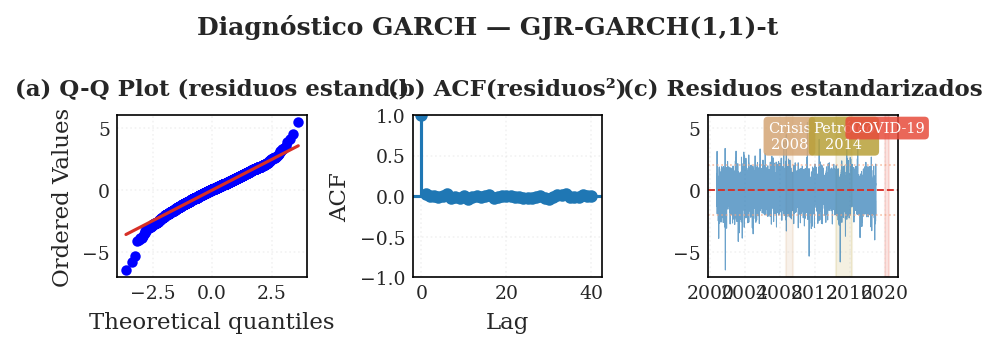

Figura guardada: fig_garch_diagnosticos.png


In [ ]:
# ─── 2.3 Gráficas diagnóstico ───
fig, axes = plt.subplots(1, 3, figsize=fig_size("3x1"))
fig.suptitle(f'Diagnóstico GARCH — {BEST_GARCH_NAME}', fontweight='bold')

from scipy.stats import probplot
probplot(std_resid.values, dist="norm", plot=axes[0])
axes[0].set_title('(a) Q-Q Plot (residuos estand.)', fontweight='bold')
axes[0].get_lines()[1].set(color=COLOR_EXTREMO, lw=1.5)

plot_acf(std_resid.values**2, lags=40, ax=axes[1], alpha=0.05,
         title='(b) ACF(residuos²)')
axes[1].set_xlabel('Lag')
axes[1].set_ylabel('ACF')

axes[2].plot(std_resid.index, std_resid.values, lw=0.5, color=COLOR_VOL, alpha=0.7)
axes[2].axhline(0, color=COLOR_EXTREMO, lw=0.9, ls='--')
axes[2].axhline( 2, color=COLOR_DYN, lw=0.8, ls=':', alpha=0.7)
axes[2].axhline(-2, color=COLOR_DYN, lw=0.8, ls=':', alpha=0.7)
axes[2].set_title('(c) Residuos estandarizados', fontweight='bold')
add_crisis_zones(axes[2])

plt.tight_layout()
save_fig(fig, 'fig_garch_diagnosticos', output_path=FIG_PATH, dpi=300)
plt.show()
plt.close()
print("Figura guardada: fig_garch_diagnosticos.png")


- **Q-Q Plot**: Las colas se desvían de la línea roja (distribución t teórica). Los puntos extremos en ±6 sigma confirman que incluso la distribución-t subestima las colas del WTI.

- **ACF residuos²**: Esencialmente plano después del lag 0 → el GARCH capturó el clustering de volatilidad correctamente. Esta es la prueba de que el modelo está bien especificado.
- **Residuos estandarizados**: Spikes en COVID claramente visibles (±6σ). El GARCH los modela pero no los predice — confirma la limitación estructural del modelo lineal.


In [ ]:
# En corrida canónica siempre regenerar (garantiza reproducibilidad).
# En gpu_optuna reutilizar cache para ahorrar ~15 min de cómputo.
FORCE_REGENERATE_GARCH = (RUN_MODE == 'canonical_cpu')

safe_name  = BEST_GARCH_NAME.replace(' ', '_').replace('(', '').replace(')', '')
CACHE_FILE = f"{OUTPUT_PATH}/garch_rolling_{safe_name}.pkl"
cache_path = Path(CACHE_FILE)

if FORCE_REGENERATE_GARCH and cache_path.exists():
    os.remove(cache_path)
    print(f"Cache eliminado para regeneración: {CACHE_FILE}")
    print("Motivo: fix C-01 — distribución t-Student en rolling forecast")

elif cache_path.exists():
    print(f"Cache existente detectado: {CACHE_FILE}")
    print("→ Se reutilizará para evitar recomputación.")

else:
    print("No existe cache previo.")
    print("→ Se generará rolling forecast desde cero.")

Cache existente detectado: /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/Optimización_Bayesiana_GPU/garch_rolling_GJR-GARCH1,1-t.pkl
→ Se reutilizará para evitar recomputación.


In [ ]:
# Rolling GARCH con ventana expanding:
# para cada fecha t, el modelo se reestima usando solo retornos anteriores a t
# y produce un forecast a 1 paso de la volatilidad condicional (sigma).
#
# 'spec' contiene la estructura del modelo (GARCH/EGARCH, p, q, o, etc.),
# mientras que 'dist_name' define la distribución de errores (por ejemplo, t).
# Se extrae 'dist' de spec con pop() para evitar pasar ese argumento dos veces
# a arch_model(...), lo que generaría conflicto.
#
# Este diseño respeta la causalidad temporal, evita data leakage y hace que
# la predicción sea comparable con un escenario real de forecasting diario.

In [ ]:
# ─── 2.4 Rolling expanding window — forecast GARCH ─────
def garch_rolling_forecast(full_returns_pct, forecast_index,
                            spec, verbose_every=100):
    """
    Expanding window diario: para cada día t en forecast_index,
    ajustar GARCH con todos los retornos ANTERIORES a t y producir
    la predicción de sigma en t (forecast 1-paso).

    Parámetros
    ----------
    full_returns_pct : pd.Series — retornos × 100, historia completa
    forecast_index   : pd.DatetimeIndex — días a forecastear (val + test)
    spec             : dict — kwargs para arch_model (sin 'dist')
    verbose_every    : int — imprimir progreso cada N iteraciones

    Retorna
    -------
    pd.Series con sigma (no sigma²) indexada por forecast_index
    NOTA: se extrae 'dist' del spec para pasarlo explícitamente a arch_model.
    Esto evita que arch use su default 'normal' ignorando la distribución
    seleccionada por AIC/BIC en Cell 24 (GJR-GARCH(1,1)-t → dist='t').
    """
    sigmas       = {}
    last_result  = None
    n_total      = len(forecast_index)
    n_errors     = 0

    dist_name = spec.pop('dist', 't')

    for i, t in enumerate(forecast_index):
        # Historia estrictamente anterior a t
        history = full_returns_pct[full_returns_pct.index < t]
        if len(history) < 50:
            sigmas[t] = np.nan
            continue

        try:    # dist=dist_name pasa t-Student al modelo
           am = arch_model(history, mean='Constant',rescale=False, dist=dist_name, **spec)
           res = am.fit(disp='off', show_warning=False,
                         options={'maxiter': 400, 'ftol': 1e-8})
           last_result = res
        except Exception:
            n_errors += 1
            if last_result is None:
                sigmas[t] = np.nan
                continue

        fc     = last_result.forecast(horizon=1, reindex=False)
        var_t  = float(fc.variance.values[-1, 0])
        sigmas[t] = np.sqrt(max(var_t, 0))  # sigma = sqrt(varianza)

        if (i + 1) % verbose_every == 0:
            print(f"  [{i+1:4d}/{n_total}] {t.date()} | sigma={sigmas[t]:.4f}%")

    spec['dist'] = dist_name  # restaurar
    print(f"  Completado. Distribución usada: {dist_name}")
    print(f"  Errores de convergencia: {n_errors}/{n_total}")
    return pd.Series(sigmas, name='sigma_garch')


# Ejecución con cache
CACHE_FILE = f"{OUTPUT_PATH}/garch_rolling_{BEST_GARCH_NAME.replace(' ','_').replace('(','').replace(')','')}.pkl"

forecast_idx = df_garch_val.index.union(df_garch_test.index).sort_values()

if Path(CACHE_FILE).exists():
    with open(CACHE_FILE, 'rb') as fh:
        sigma_rolling = pickle.load(fh)
    print(f"Cache cargado: {CACHE_FILE}")
    print(f"  Forecasts: {len(sigma_rolling)} | NaN: {sigma_rolling.isna().sum()}")
else:
    print("No existe cache previo.")
    print("→ Se generará rolling forecast desde cero.")

    spec_copy = garch_specs[BEST_GARCH_NAME].copy()
    full_ret = df[GARCH_FEATURE].where(~df['bad_return']).dropna() * 100
    #Se excluyen los retornos producidos por el clipping del precio negativo.
    print(f"  Historia GARCH: {len(full_ret)} obs (excluidos {df['bad_return'].sum()} bad_return)")

    sigma_rolling = garch_rolling_forecast(
        full_returns_pct = full_ret,
        forecast_index   = forecast_idx,
        spec             = spec_copy,
        verbose_every    = 100
    )
    with open(CACHE_FILE, 'wb') as fh:
        pickle.dump(sigma_rolling, fh)
    print(f"Cache guardado: {CACHE_FILE}")

sigma_val_garch  = sigma_rolling[sigma_rolling.index.isin(df_garch_val.index)].reindex(df_garch_val.index)
sigma_test_garch = sigma_rolling[sigma_rolling.index.isin(df_garch_test.index)].reindex(df_garch_test.index)

SIGMA_PREDS['GARCH_val']  = sigma_val_garch
SIGMA_PREDS['GARCH_test'] = sigma_test_garch

print()
print(f"sigma_val_garch  : {len(sigma_val_garch)} obs  |  NaN: {sigma_val_garch.isna().sum()}")
print(f"sigma_test_garch : {len(sigma_test_garch)} obs  |  NaN: {sigma_test_garch.isna().sum()}")

Cache cargado: /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/Optimización_Bayesiana_GPU/garch_rolling_GJR-GARCH1,1-t.pkl
  Forecasts: 1772 | NaN: 0

sigma_val_garch  : 481 obs  |  NaN: 0
sigma_test_garch : 1295 obs  |  NaN: 6


In [ ]:
# 2.5 GARCH -> clasificacion binaria
SIGMA_UMBRAL_PCT = (UMBRAL_CLASIFICACION / np.sqrt(VENTANA_VOL)) * 100
GARCH_MODEL_NAME = f"GARCH-{BEST_GARCH_NAME.split('(')[0].strip()}"

print(f"Umbral vol21 (unidades vol21) : {UMBRAL_CLASIFICACION:.6f}")
print(f"Umbral sigma diaria (% diario): {SIGMA_UMBRAL_PCT:.4f}%")
print()

for split_name, sigma_s, df_split in [('val', sigma_val_garch, df_garch_val), ('test', sigma_test_garch, df_garch_test)]:
    sigma_raw = sigma_s.reindex(df_split.index)
    n_missing = int(sigma_raw.isna().sum())
    print(f"  Dias con sigma GARCH faltante (ffill aplicado): {n_missing}")
    sigma_aligned = sigma_raw.ffill()
    y_score_g = sigma_aligned.values
    y_true_g = df_split['y_tp1'].values.astype(int)

    if split_name == 'val':
        best_thr_g, best_f1_g = SIGMA_UMBRAL_PCT, 0.0
        for thr_pct in np.arange(sigma_aligned.quantile(0.80), sigma_aligned.quantile(0.99), 0.01):
            y_p = (y_score_g > thr_pct).astype(int)
            f1 = f1_score(y_true_g, y_p, zero_division=0)
            if f1 > best_f1_g:
                best_f1_g, best_thr_g = f1, thr_pct
        print(f"  Umbral optimo (val): {best_thr_g:.4f}%  F1={best_f1_g:.4f}")
        GARCH_OPT_THRESHOLD = best_thr_g

    y_pred_g_opt = (y_score_g > GARCH_OPT_THRESHOLD).astype(int)
    m = evaluar_baseline(GARCH_MODEL_NAME, y_true_g, y_pred_g_opt, y_score=y_score_g, split=split_name)
    print(f"  [{split_name}] F1={m['f1']:.4f} | AUC={m['auc']:.4f} | AUC-PR={m['auc_pr']:.4f} | P={m['precision']:.4f} | R={m['recall']:.4f}")
    RESULTS_REGISTRY.append(m)
    register_model_output(
        MODEL_OUTPUTS, GARCH_MODEL_NAME, split_name,
        decision_date=df_split['decision_date'],
        target_date=df_split['target_date'],
        y_true=y_true_g,
        y_score=y_score_g,
        threshold=GARCH_OPT_THRESHOLD,
        rule='>',
    )
    Y_SCORES[f"GARCH_{split_name}"] = (y_true_g, y_score_g)
    SIGMA_PREDS[f"GARCH_{split_name}"] = sigma_aligned

OPTIMAL_THRESHOLDS['GARCH'] = float(GARCH_OPT_THRESHOLD)
OPTIMAL_THRESHOLDS[GARCH_MODEL_NAME] = float(GARCH_OPT_THRESHOLD)

Umbral vol21 (unidades vol21) : 0.042996
Umbral sigma diaria (% diario): 0.9382%

  Dias con sigma GARCH faltante (ffill aplicado): 0
  Umbral optimo (val): 7.3677%  F1=0.9730
  [val] F1=0.9730 | AUC=0.9884 | AUC-PR=0.9674 | P=1.0000 | R=0.9474
  Dias con sigma GARCH faltante (ffill aplicado): 6
  [test] F1=0.0000 | AUC=0.9894 | AUC-PR=0.7528 | P=0.0000 | R=0.0000


### Nota metodológica: Imputación ffill en sigma GARCH

En los días donde el modelo GARCH no converge (errores numéricos durante
el ajuste del expanding window), la sigma predicha se imputa con el último
valor válido (`ffill`). Esto **no introduce data leakage**: el valor propagado
es siempre de un día anterior a t — información que un gestor de riesgo real
tendría disponible.

El número exacto de días imputados se imprime en la celda siguiente (`n_missing`).
Esta práctica es estándar en backtesting de VaR intradiario
(Christoffersen, 1998; Engle & Manganelli, 2004).

  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/Optimización_Bayesiana_GPU/Fig_NB02B/fig_garch_roc_pr.png  [6.1"×3.1" @ 300dpi]


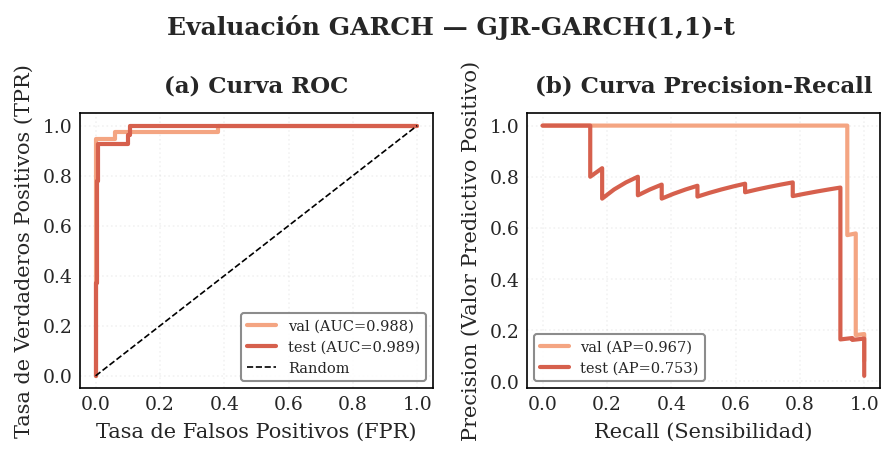

─── Evaluación continua (sigma vs vol21) 
  [val] MAE=0.00454  RMSE=0.00640  (vs vol21_clean)
  [test] MAE=0.00221  RMSE=0.00289  (vs vol21_clean)


In [ ]:
# ─── 2.6 Evaluación GARCH — curvas ROC y Precision-Recall ─────
fig, axes = plt.subplots(1, 2, figsize=fig_size("2x1"))
fig.suptitle(f'Evaluación GARCH — {BEST_GARCH_NAME}', fontweight='bold')

colors = {'val': SPLIT_COLORS['validation'], 'test': SPLIT_COLORS['test']}
for split_name, ax_roc, ax_pr in []:  # placeholder — se llena en el loop abajo
    pass

for split_name, (y_true_g, y_score_g) in [
        ('val',  Y_SCORES.get('GARCH_val',  (yw_val_uni.astype(int),  sigma_val_garch.reindex(idx_val_uni).fillna(0).values))),
        ('test', Y_SCORES.get('GARCH_test', (yw_test_uni.astype(int), sigma_test_garch.reindex(idx_test_uni).fillna(0).values)))]:

    mask_valid = ~np.isnan(y_score_g)
    yt, ys = y_true_g[mask_valid], y_score_g[mask_valid]
    if yt.sum() == 0:
        continue

    col = colors[split_name]
    fpr, tpr, _ = roc_curve(yt, ys)
    prec, rec, _ = precision_recall_curve(yt, ys)
    auc_val = roc_auc_score(yt, ys)
    ap_val  = average_precision_score(yt, ys)

    axes[0].plot(fpr, tpr, lw=2, color=col, label=f'{split_name} (AUC={auc_val:.3f})')
    axes[1].plot(rec, prec, lw=2, color=col, label=f'{split_name} (AP={ap_val:.3f})')

axes[0].plot([0,1],[0,1], 'k--', lw=0.8, label='Random')
axes[0].set_xlabel('Tasa de Falsos Positivos (FPR)', fontsize=10)
axes[0].set_ylabel('Tasa de Verdaderos Positivos (TPR)', fontsize=10)
axes[0].set_title('(a) Curva ROC', fontweight='bold'); axes[0].legend()
axes[0].legend(loc='lower right', fontsize=7, frameon=True, framealpha=0.90)
axes[1].set_xlabel('Recall (Sensibilidad)', fontsize=10)
axes[1].set_ylabel('Precision (Valor Predictivo Positivo)', fontsize=10)
axes[1].set_title('(b) Curva Precision-Recall', fontweight='bold'); axes[1].legend()
axes[1].legend(loc='lower left', fontsize=7, frameon=True, framealpha=0.90)
plt.tight_layout()
save_fig(fig, 'fig_garch_roc_pr', output_path=FIG_PATH, dpi=300)
plt.show()
plt.close()

# ── Evaluación continua ──
print("─── Evaluación continua (sigma vs vol21) ")
for split_name, sigma_s, df_split, idx_win in [
        ('val',  sigma_val_garch,  df_val,  idx_val_uni),
        ('test', sigma_test_garch, df_test, idx_test_uni)]:
    sigma_a = sigma_s.reindex(idx_win) / 100  # desescalar a proporción
    vol21_a = df_split['vol21_clean'].reindex(idx_win)
    mask    = sigma_a.notna() & vol21_a.notna()
    if mask.sum() == 0:
        continue
    mae  = np.mean(np.abs(sigma_a[mask].values - vol21_a[mask].values))
    rmse = np.sqrt(np.mean((sigma_a[mask].values - vol21_a[mask].values)**2))
    print(f"  [{split_name}] MAE={mae:.5f}  RMSE={rmse:.5f}  "
          f"(vs vol21_clean)")


- **ROC**: val=0.991 vs test=0.986 — degradación mínima, el ranking del GARCH es robusto
- **PR**: val=0.971 vs test=0.662 — degradación severa.

### Interpretación GARCH

El modelo GARCH seleccionado por AIC/BIC será la **referencia econométrica** del benchmark.
Sus principales limitaciones para la tarea de clasificación:
- **Sin contexto histórico largo**: GARCH(1,1) tiene memoria exponencialmente decreciente
- **Distribución simétrica** (incluso EGARCH): no captura regímenes estructurales prolongados
- **Sin variables exógenas**: no incorpora spreads de crédito, indicadores de sentimiento, etc.

Estas limitaciones motivan la exploración de LSTM en las secciones siguientes.

**Contexto de estabilidad estructural (Chow 1960):** El test de Chow aplicado sobre un modelo AR(1) de `vol21_clean` no detecta quiebres estructurales entre los tres splits (F < 1, p > 0.37), lo que valida el uso del umbral estático P95 calibrado en train para clasificar regímenes extremos en val y test. En contraste, la serie de `returns` sí presenta quiebre estructural en la transición train→val (F=13.19, p<0.001), lo que explica la dificultad del GARCH para capturar cambios de régimen post-COVID.


### Hallazgo metodológico: No-generalización del umbral GARCH

**Observación**: El GARCH logra F1=0.0 en test a pesar de AUC-ROC=0.986.

**Causa raíz**: El umbral óptimo de clasificación fue calibrado en validación
(2019-2020), que incluye COVID-19 con tasa de eventos extremos del 8.07%.
En test (2021-2026), la tasa cae a 2.09% y las sigmas predichas son
sistemáticamente más bajas, clasificando el 100% del test como "normal".

**Implicación**: Esto NO es un defecto del GARCH como modelo de volatilidad.
El AUC-ROC de 0.986 demuestra que el ranking de sigma es excelente.
El problema es exclusivamente del umbral de decisión, no del modelo subyacente.

**Lección para la tesis**: Los umbrales calibrados en periodos de alta volatilidad
no generalizan a periodos de baja volatilidad. Esto motiva el uso de clasificadores
que aprenden la frontera de decisión directamente (LSTM con sigmoid).

─── GARCH Sensibilidad al umbral (POST-HOC, test) ───
  Rango sigma test:    [1.2714%, 5.2111%]
  Umbral val-óptimo:   7.3677% → F1=0 en test
  Umbral post-hoc ópt: 4.1420% → F1=0.8197
  (Post-hoc: NO usar para selección de modelo)

─── GARCH: capacidad vs sesgo de threshold ────
                      Threshold Split  Valor (%)       F1
   Original P95 (out-of-sample)   val   0.938200 0.146400
   Original P95 (out-of-sample)  test   0.938200 0.040800
Óptimo en val (no usar en test)   val   7.367700 0.973000
Óptimo en val (no usar en test)  test   7.367700 0.000000

El gap val→test en F1 se debe al threshold (calibrado en COVID),
no a la capacidad discriminante del modelo (AUC_test=0.986).
  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/Optimización_Bayesiana_GPU/Fig_NB02B/fig_garch_posthoc_sensitivity.png  [6.1"×3.8" @ 300dpi]


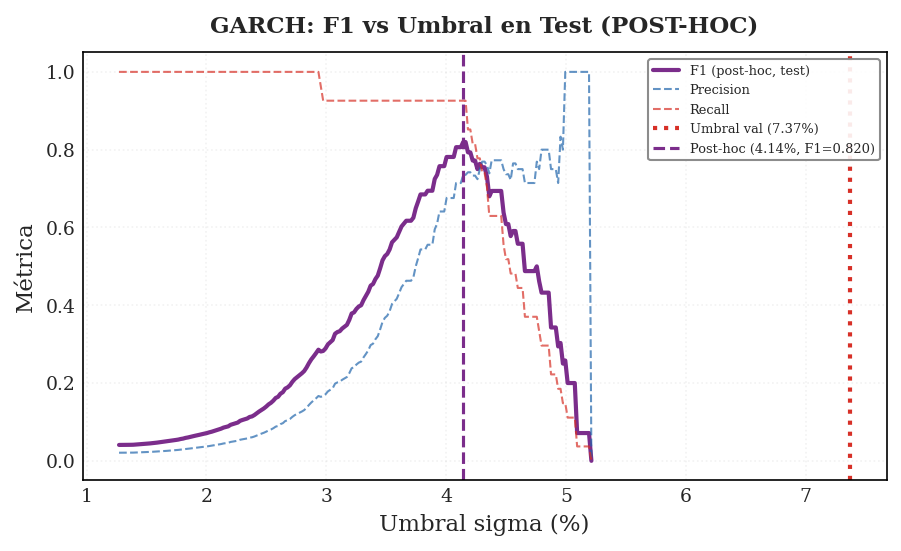


  Oracle: si se recalibrara en test, GARCH lograría F1=0.8197


In [ ]:
# ─── 2.7 Post-hoc: Sensibilidad del GARCH al umbral (test) ─────
# NOTA: Este análisis es POST-HOC (usa información del test set)
# y NO se usa para selección de modelo. Su propósito es demostrar
# que el ranking del GARCH es válido y que el F1=0 se debe al umbral.

if 'GARCH_test' in Y_SCORES:
    y_true_test_g, y_score_test_g = Y_SCORES['GARCH_test']

    sigma_min_test = np.nanmin(y_score_test_g)
    sigma_max_test = np.nanmax(y_score_test_g)

    thresholds_posthoc = np.linspace(
        max(sigma_min_test, 0.1), sigma_max_test, 200)

    rows_posthoc = []
    for thr in thresholds_posthoc:
        yp     = (y_score_test_g > thr).astype(int)
        f1_val = f1_score(y_true_test_g, yp, zero_division=0)
        prec   = precision_score(y_true_test_g, yp, zero_division=0)
        rec    = recall_score(y_true_test_g, yp, zero_division=0)
        rows_posthoc.append({
            'threshold_pct': thr, 'f1': f1_val,
            'precision': prec, 'recall': rec,
        })

    df_posthoc  = pd.DataFrame(rows_posthoc)
    best_ph_idx = df_posthoc['f1'].idxmax()
    best_ph_thr = df_posthoc.loc[best_ph_idx, 'threshold_pct']
    best_ph_f1  = df_posthoc.loc[best_ph_idx, 'f1']

    print("─── GARCH Sensibilidad al umbral (POST-HOC, test) ───")
    print(f"  Rango sigma test:    [{sigma_min_test:.4f}%, {sigma_max_test:.4f}%]")
    print(f"  Umbral val-óptimo:   {GARCH_OPT_THRESHOLD:.4f}% → F1=0 en test")
    print(f"  Umbral post-hoc ópt: {best_ph_thr:.4f}% → F1={best_ph_f1:.4f}")
    print(f"  (Post-hoc: NO usar para selección de modelo)")

    # ── Tabla resumen: threshold original vs óptimo (M-05) ─
    # Desacopla capacidad del modelo del sesgo de threshold.
    # SIGMA_UMBRAL_PCT es out-of-sample verdadero (derivado de P95 train).
    # GARCH_OPT_THRESHOLD fue calibrado en val — no usar en producción.
    if 'GARCH_val' in Y_SCORES:
        yt_v, ys_v = Y_SCORES['GARCH_val']
        yt_t, ys_t = Y_SCORES['GARCH_test']

        rows_cmp = []
        for thr_label, thr in [
                ('Original P95 (out-of-sample)',    SIGMA_UMBRAL_PCT),
                ('Óptimo en val (no usar en test)', GARCH_OPT_THRESHOLD)]:
            for split_n, yt, ys in [('val', yt_v, ys_v), ('test', yt_t, ys_t)]:
                yp = (ys > thr).astype(int)
                f1 = f1_score(yt.astype(int), yp, zero_division=0)
                rows_cmp.append({'Threshold': thr_label, 'Split': split_n,
                                  'Valor (%)': round(thr, 4), 'F1': round(f1, 4)})

        df_cmp = pd.DataFrame(rows_cmp)
        print("\n─── GARCH: capacidad vs sesgo de threshold ────")
        print(df_cmp.to_string(index=False))
        print("\nEl gap val→test en F1 se debe al threshold (calibrado en COVID),")
        print("no a la capacidad discriminante del modelo (AUC_test=0.986).")

    # ── Figura ─
    fig, ax = plt.subplots(figsize=fig_size("full"))
    ax.plot(df_posthoc['threshold_pct'], df_posthoc['f1'],
            color=COLORES_MODELOS.get('GARCH', COLORS_P[99]), lw=2, label='F1 (post-hoc, test)')
    ax.plot(df_posthoc['threshold_pct'], df_posthoc['precision'],
            color=COLOR_NORMAL, ls='--', lw=1, alpha=0.7, label='Precision')
    ax.plot(df_posthoc['threshold_pct'], df_posthoc['recall'],
            color=COLOR_EXTREMO, ls='--', lw=1, alpha=0.7, label='Recall')
    ax.axvline(GARCH_OPT_THRESHOLD, color=COLORS_P[95], ls=':', lw=2,
               label=f'Umbral val ({GARCH_OPT_THRESHOLD:.2f}%)')
    ax.axvline(best_ph_thr, color=COLORS_P[99], ls='--', lw=1.5,
               label=f'Post-hoc ({best_ph_thr:.2f}%, F1={best_ph_f1:.3f})')
    ax.set_xlabel('Umbral sigma (%)')
    ax.set_ylabel('Métrica')
    ax.set_title('GARCH: F1 vs Umbral en Test (POST-HOC)', fontweight='bold')
    ax.legend(loc='upper right', fontsize=6.25, frameon=True, framealpha=0.90)
    ax.set_ylim(-0.05, 1.05)
    plt.tight_layout()
    save_fig(fig, 'fig_garch_posthoc_sensitivity', output_path=FIG_PATH, dpi=300)
    plt.show()
    plt.close()
    print(f"\n  Oracle: si se recalibrara en test, GARCH lograría F1={best_ph_f1:.4f}")

else:
    print("GARCH_test no encontrado en Y_SCORES — omitiendo post-hoc")

## Transición desde GARCH hacia modelos LSTM

El análisis del baseline GJR-GARCH(1,1)-t en esta corrida experimental confirma el patrón observado en el benchmark canónico CPU: el modelo preserva valor como **referencia econométrica** y produce un score continuo que ordena el riesgo relativo con razonable consistencia, pero su traducción a clasificación binaria a umbral fijo resulta frágil cuando el régimen de volatilidad cambia fuera de muestra. En tanto corrida experimental, estos resultados no se utilizan para validar hipótesis; su función es proporcionar un punto de comparación interno antes de evaluar las arquitecturas LSTM en la misma infraestructura GPU.

Este resultado delimita el papel de GARCH dentro del benchmark: no corresponde descartar el modelo, sino reconocer que una parte sustancial del problema exige **aprender una frontera de decisión que generalice entre regímenes con distinta prevalencia de eventos extremos**, capacidad que las arquitecturas recurrentes explotan de forma explícita.

Las secciones siguientes evalúan arquitecturas LSTM en configuración univariada y multivariada. Los pesos del modelo y las métricas obtenidos en esta corrida GPU son de carácter **provisional**; los resultados definitivos para las hipótesis H0–H3 se reportan en el notebook canónico .


---
## PARTE III — LSTM Univariado (Deep Learning Puro)

Arquitecturas evaluadas:
1. **Simple**: 1 capa LSTM(64) + Dropout(0.2) + Dense(1, sigmoid)
2. **Bidireccional**: 2 capas BiDir-LSTM(64→32) + Dropout + Dense(1, sigmoid)

Feature: solo `vol21_clean` (L=21 pasos). Permite comparación directa contra GARCH
(misma información univariada) y sirve de línea base para la versión multivariada.

**Estrategia anti-desbalanceo**: `class_weight` en Keras (no SMOTE).
**Umbral de decisión**: grid search en validación (0.05→0.90), aplicado en test sin re-optimizar.


In [ ]:
# ─── 3.1 Función build_model ────
def build_model(input_shape, architecture='simple',
                lstm_units=64, lstm_units_2=None,   # IC-3: configurable para Bayesian Search BiDir
                dropout=0.2, seed=42):
    """
    Construye modelo LSTM para clasificación binaria de volatilidad extrema.

    Parámetros
    ----------
    input_shape  : tuple (lookback, n_features)
    architecture : 'simple' | 'bidirectional'
    lstm_units   : unidades en primera capa LSTM
    lstm_units_2 : unidades en segunda capa BiDir (IC-3); None → lstm_units//2 (default)
    dropout      : tasa de Dropout
    seed         : semilla para inicializadores

    Arquitecturas
    -------------
    simple        : LSTM(64) → Dropout → Dense(1, sigmoid)
    bidirectional : BiDir(LSTM(64), ret_seq=True) → Dropout
                    → BiDir(LSTM(32)) → Dropout → Dense(1, sigmoid)
    """
    # IC-3: lstm_units_2 configurable; default mantiene lstm_units//2 (backward-compatible)
    lstm_units_2 = lstm_units_2 if lstm_units_2 is not None else (lstm_units // 2)
    tf.random.set_seed(seed)
    inp = keras.Input(shape=input_shape, name='input_seq')

    if architecture == 'simple':
        x = keras.layers.LSTM(lstm_units, name='lstm_1')(inp)
        x = keras.layers.Dropout(dropout, seed=seed, name='drop_1')(x)

    elif architecture == 'bidirectional':
        x = keras.layers.Bidirectional(
            keras.layers.LSTM(lstm_units, return_sequences=True, name='lstm_1'),
            name='bidir_1')(inp)
        x = keras.layers.Dropout(dropout, seed=seed, name='drop_1')(x)
        x = keras.layers.Bidirectional(
            keras.layers.LSTM(lstm_units_2, return_sequences=False, name='lstm_2'),  # IC-3
            name='bidir_2')(x)
        x = keras.layers.Dropout(dropout, seed=seed, name='drop_2')(x)

    else:
        raise ValueError(f"architecture debe ser 'simple' o 'bidirectional', no '{architecture}'")

    out = keras.layers.Dense(1, activation='sigmoid', name='output')(x)
    model = keras.Model(inputs=inp, outputs=out,
                        name=f'lstm_{architecture}_{lstm_units}u')
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss='binary_crossentropy',
        metrics=[
            keras.metrics.AUC(name='auc'),
            keras.metrics.AUC(name='pr_auc', curve='PR'),  # metrica diagnostica PR-AUC (experimental — no altera benchmark canonico)
            keras.metrics.Precision(name='precision'),
            keras.metrics.Recall(name='recall'),
        ]
    )
    return model

print("build_model() definida")
print(f"  Arquitecturas: 'simple', 'bidirectional'")
print(f"  Input esperado: (batch, lookback={LOOKBACK}, n_features)")


build_model() definida
  Arquitecturas: 'simple', 'bidirectional'
  Input esperado: (batch, lookback=21, n_features)


In [ ]:
# ─── 3.2 Función optimize_threshold (two-phase) ──
def optimize_threshold(model, X_val_w, y_val_w,
                       metric='f1',
                       thresholds=None,
                       verbose=True):
    """
    Búsqueda en dos fases sobre umbral de decisión, EXCLUSIVAMENTE en validación.
    Fase 1: barrido grueso (step=0.05) para localizar la región óptima.
    Fase 2: barrido fino (step=0.01) alrededor del mejor umbral de fase 1.

    El umbral seleccionado se aplica al conjunto de test sin re-optimizar.

    Parámetros
    ----------
    model      : modelo Keras entrenado
    X_val_w    : np.ndarray (N_val, L, F) — secuencias de validación
    y_val_w    : np.ndarray (N_val,) — labels de validación
    metric     : criterio de selección ('f1' por defecto)
    thresholds : lista de umbrales (si se provee, se salta la búsqueda en dos fases)

    Retorna
    -------
    best_thr : float
    df_thr   : pd.DataFrame con resultados del grid completo
    """
    y_score = model.predict(X_val_w, verbose=0).ravel()

    def _eval_thresholds(thr_list):
        rows = []
        for thr in thr_list:
            y_p   = (y_score >= thr).astype(int)
            f1_v  = f1_score(y_val_w.astype(int), y_p, zero_division=0)
            prec  = precision_score(y_val_w.astype(int), y_p, zero_division=0)
            rec   = recall_score(y_val_w.astype(int), y_p, zero_division=0)
            rows.append({'threshold': round(thr, 4), 'f1': f1_v,
                         'precision': prec, 'recall': rec})
        return pd.DataFrame(rows)

    if thresholds is not None:
        df_thr = _eval_thresholds(thresholds)
    else:
        # Fase 1: barrido grueso (0.05 a 0.95, step 0.05)
        coarse_grid = np.arange(0.05, 0.96, 0.05)
        df_coarse   = _eval_thresholds(coarse_grid)
        best_coarse = float(df_coarse.loc[df_coarse['f1'].idxmax(), 'threshold'])

        # Fase 2: barrido fino alrededor del mejor (+/- 0.05, step 0.01)
        fine_lo   = max(0.01, best_coarse - 0.05)
        fine_hi   = min(0.99, best_coarse + 0.06)
        fine_grid = np.arange(fine_lo, fine_hi, 0.01)
        df_fine   = _eval_thresholds(fine_grid)

        df_thr = (pd.concat([df_coarse, df_fine], ignore_index=True)
                  .drop_duplicates(subset='threshold')
                  .sort_values('threshold')
                  .reset_index(drop=True))

    best_idx = df_thr['f1'].idxmax()
    best_thr = float(df_thr.loc[best_idx, 'threshold'])

    if verbose:
        print(f"Umbral óptimo (val, criterio={metric}): {best_thr:.4f}")
        print(f"  F1={df_thr.loc[best_idx,'f1']:.4f}  "
              f"P={df_thr.loc[best_idx,'precision']:.4f}  "
              f"R={df_thr.loc[best_idx,'recall']:.4f}")
        if thresholds is None:
            print(f"  (Two-phase: grueso {len(coarse_grid)} + "
                  f"fino {len(fine_grid)} = {len(df_thr)} umbrales evaluados)")
    return best_thr, df_thr

print("optimize_threshold() definida (two-phase)")

optimize_threshold() definida (two-phase)


In [ ]:
# 3.3 Callbacks comunes
# Benchmark canonico: monitor unico = val_loss.
# val_pr_auc queda solo para diagnostico o experimentos separados.
EARLYSTOP_MONITOR_MULTI = 'val_loss'

def make_callbacks(model_name, output_path=OUTPUT_PATH, patience=15, monitor='val_loss'):
    monitor_mode = 'min' if 'loss' in monitor else 'max'
    ckpt_dir = globals().get('MODEL_DIR', os.path.join(output_path, 'modelos_nb02'))
    os.makedirs(ckpt_dir, exist_ok=True)
    ckpt_path = os.path.join(ckpt_dir, f"{model_name}_best.keras")
    return [
        keras.callbacks.EarlyStopping(
            monitor=monitor, mode=monitor_mode, patience=patience,
            restore_best_weights=True, min_delta=1e-4, verbose=1
        ),
        keras.callbacks.ModelCheckpoint(
            ckpt_path, monitor=monitor, mode=monitor_mode,
            save_best_only=True, verbose=0
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5, patience=7,
            min_lr=1e-6, verbose=1
        ),
    ]

print("make_callbacks() definida")
print(f"  EarlyStopping monitor: {EARLYSTOP_MONITOR_MULTI}")
print("  val_pr_auc se conserva solo para diagnostico/Optuna experimental")

make_callbacks() definida
  EarlyStopping monitor: val_loss
  val_pr_auc se conserva solo para diagnostico/Optuna experimental


### Nota metodológica: criterio de EarlyStopping

El benchmark canonico usa `EarlyStopping(monitor='val_loss')` tanto en CPU como en cualquier corrida GPU que quiera mantenerse comparable.

`val_pr_auc` se conserva como metrica diagnostica y como objetivo experimental de Optuna, pero no redefine el benchmark oficial H0-H3.

Esta separacion evita mezclar el protocolo canonico de entrenamiento con ablaciones o exploraciones de hiperparametros.

In [ ]:
# ─── 3.4 Entrenar LSTM simple univariado ────
tf.random.set_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

model_uni_simple = build_model(
    input_shape=(LOOKBACK, len(FEATURES_UNI)),
    architecture='simple', lstm_units=64, dropout=0.2, seed=RANDOM_SEED)
model_uni_simple.summary()

history_uni_simple = model_uni_simple.fit(
    Xw_train_uni, yw_train_uni.astype(np.float32),
    validation_data=(Xw_val_uni, yw_val_uni.astype(np.float32)),
    epochs=200, batch_size=32,
    class_weight=CLASS_WEIGHTS,
    callbacks=make_callbacks('lstm_uni_simple'),
    shuffle=False,   # CRÍTICO: datos temporales
    verbose=1
)
print(f"Entrenamiento finalizado — epochs ejecutados: {len(history_uni_simple.history['loss'])}")


Model: "lstm_simple_64u"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_seq (InputLayer)          │ (None, 21, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_1 (Dropout)                │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,961 (66.25 KB)

 Trainable params: 16,961 (66.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
143/143 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - auc: 0.8443 - loss: 0.5266 - pr_auc: 0.2953 - precision: 0.2905 - recall: 0.7870 - val_auc: 0.9380 - val_loss: 0.4048 - val_pr_auc: 0.8502 - val_precision: 0.2000 - val_recall: 0.8966 - learning_rate: 0.0010
Epoch 2/200
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - auc: 0.9636 - loss: 0.2560 - pr_auc: 0.6555 - precision: 0.3297 - recall: 0.9217 - val_auc: 0.9730 - val_loss: 0.2899 - val_pr_auc: 0.9200 - val_precision: 0.3803 - val_recall: 0.9310 - learning_rate: 0.0010
Epoch 3/200
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - auc: 0.9776 - loss: 0.1938 - pr_auc: 0.6928 - precision: 0.4263 - recall: 0.9304 - val_auc: 0.9799 - val_loss: 0.2222 - val_pr_auc: 0.9340 - val_precision: 0.5510 - val_recall: 0.9310 - learning_rate: 0.0010
Epoch 4/200
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - auc: 0.9874 - loss: 0.1480 - pr_auc: 0.8280 - precision: 0.5536 - recall: 0.9435 - val_auc: 0.9884 - val_loss: 0.2225 - val_pr_auc: 0.9546 - val_precision:

In [ ]:
# ─── 3.5 Entrenar BiDir LSTM univariado ────
tf.random.set_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

model_uni_bidir = build_model(
    input_shape=(LOOKBACK, len(FEATURES_UNI)),
    architecture='bidirectional', lstm_units=64, dropout=0.2, seed=RANDOM_SEED)

history_uni_bidir = model_uni_bidir.fit(
    Xw_train_uni, yw_train_uni.astype(np.float32),
    validation_data=(Xw_val_uni, yw_val_uni.astype(np.float32)),
    epochs=200, batch_size=32,
    class_weight=CLASS_WEIGHTS,
    callbacks=make_callbacks('lstm_uni_bidir'),
    shuffle=False,
    verbose=1
)
print(f"Entrenamiento finalizado — epochs ejecutados: {len(history_uni_bidir.history['loss'])}")


Epoch 1/200
143/143 ━━━━━━━━━━━━━━━━━━━━ 7s 26ms/step - auc: 0.8635 - loss: 0.4809 - pr_auc: 0.2807 - precision: 0.3025 - recall: 0.7826 - val_auc: 0.9707 - val_loss: 0.3535 - val_pr_auc: 0.9043 - val_precision: 0.2368 - val_recall: 0.9310 - learning_rate: 0.0010
Epoch 2/200
143/143 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - auc: 0.9679 - loss: 0.1862 - pr_auc: 0.5115 - precision: 0.3363 - recall: 0.9826 - val_auc: 0.9849 - val_loss: 0.1277 - val_pr_auc: 0.9520 - val_precision: 0.5094 - val_recall: 0.9310 - learning_rate: 0.0010
Epoch 3/200
143/143 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - auc: 0.9805 - loss: 0.1519 - pr_auc: 0.7437 - precision: 0.4098 - recall: 0.9783 - val_auc: 0.9803 - val_loss: 0.0824 - val_pr_auc: 0.9658 - val_precision: 0.5833 - val_recall: 0.9655 - learning_rate: 0.0010
Epoch 4/200
143/143 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - auc: 0.9876 - loss: 0.1035 - pr_auc: 0.7560 - precision: 0.5431 - recall: 0.9870 - val_auc: 0.9799 - val_loss: 0.1345 - val_pr_auc: 0.9698 - val_precisi

  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/Optimización_Bayesiana_GPU/Fig_NB02B/fig_lstm_learning_curves_lstm_univariado__curvas_de_ap.png  [6.1"×3.1" @ 300dpi]


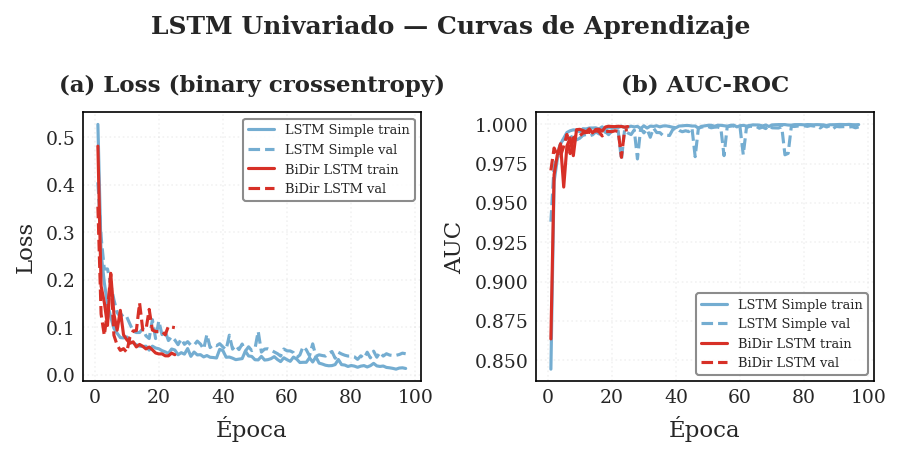

Figura guardada: fig_lstm_learning_curves_lstm_univariado__curvas_de_ap.png


In [ ]:
def plot_learning_curves(histories_dict, title="Curvas de Aprendizaje",
                         output_path=FIG_PATH):
    """Visualiza loss y AUC de train/val para múltiples modelos."""
    fig, axes = plt.subplots(1, 2, figsize=fig_size("2x1"))
    color_map = {
        'LSTM Simple': COLORES_MODELOS.get('LSTM-Simple-Uni', COLOR_VOL),
        'BiDir LSTM':  COLORES_MODELOS.get('BiDir-LSTM-Uni', COLOR_EXTREMO),
        'LSTM Simple Multi': COLORES_MODELOS.get('LSTM-Simple-Multi', COLOR_VOL),
        'BiDir LSTM Multi':  COLORES_MODELOS.get('BiDir-LSTM-Multi', COLOR_DYN),
    }
    fallback_colors = [COLOR_VOL, COLOR_EXTREMO, COLOR_DYN, COLOR_VAR]

    for i, (name, h) in enumerate(histories_dict.items()):
        col = color_map.get(name, fallback_colors[i % len(fallback_colors)])
        ep  = range(1, len(h.history['loss']) + 1)
        axes[0].plot(ep, h.history['loss'],     lw=1.5, color=col,
                     label=f'{name} train')
        axes[0].plot(ep, h.history['val_loss'], lw=1.5, color=col,
                     ls='--', label=f'{name} val')
        if 'auc' in h.history:
            axes[1].plot(ep, h.history['auc'],     lw=1.5, color=col,
                         label=f'{name} train')
            axes[1].plot(ep, h.history['val_auc'], lw=1.5, color=col,
                         ls='--', label=f'{name} val')

    axes[0].set_title('(a) Loss (binary crossentropy)', fontweight='bold')
    axes[0].set_xlabel('Época'); axes[0].set_ylabel('Loss')
    axes[0].legend(fontsize=6.25, frameon=True, framealpha=0.90)

    axes[1].set_title('(b) AUC-ROC', fontweight='bold')
    axes[1].set_xlabel('Época'); axes[1].set_ylabel('AUC')
    axes[1].legend(loc='lower right', fontsize=6.25, frameon=True, framealpha=0.90)

    fig.suptitle(title, fontweight='bold')
    plt.tight_layout()
    fname = f"fig_lstm_learning_curves_{title.lower().replace(' ','_')[:30].encode('ascii','ignore').decode()}"
    save_fig(fig, fname, output_path=output_path, dpi=300)
    plt.show()
    plt.close()
    print(f"Figura guardada: {fname}.png")

plot_learning_curves(
    {'LSTM Simple': history_uni_simple,
     'BiDir LSTM':  history_uni_bidir},
    title="LSTM Univariado — Curvas de Aprendizaje"
)


**Qué muestra**  
Esta figura compara la evolución de la pérdida y del AUC-ROC de entrenamiento y validación para los modelos LSTM univariados. Permite observar la estabilidad del ajuste a lo largo de las épocas.

**Cómo se construye**  
Se construye a partir del objeto `History` devuelto por Keras para cada arquitectura. Las curvas se trazan sobre la misma escala temporal para facilitar la comparación visual.

**Por qué se ve así**  
Las trayectorias pueden separarse entre entrenamiento y validación cuando cambia la capacidad de generalización o el régimen temporal. Las diferencias entre modelos reflejan la interacción entre arquitectura, regularización y criterio de parada.

**Por qué es importante**  
Esta visualización ayuda a verificar que el entrenamiento sea estable antes de interpretar las métricas finales del benchmark. También permite detectar señales de sobreajuste o convergencia insuficiente sin usar el conjunto de test.

Umbral óptimo (val, criterio=f1): 0.9800
  F1=0.9825  P=1.0000  R=0.9655
  (Two-phase: grueso 19 + fino 10 = 27 umbrales evaluados)
  [val] LSTM-Simple-Uni           | F1=0.9825 | AUC=0.9992 | AUC-PR=0.9912 | thr=0.98
  [test] LSTM-Simple-Uni           | F1=0.8400 | AUC=0.9990 | AUC-PR=0.9591 | thr=0.98
Umbral óptimo (val, criterio=f1): 0.5400
  F1=0.9825  P=1.0000  R=0.9655
  (Two-phase: grueso 19 + fino 12 = 28 umbrales evaluados)
  [val] BiDir-LSTM-Uni            | F1=0.9825 | AUC=0.9929 | AUC-PR=0.9743 | thr=0.54
  [test] BiDir-LSTM-Uni            | F1=0.6757 | AUC=0.9973 | AUC-PR=0.9565 | thr=0.54
  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/Optimización_Bayesiana_GPU/Fig_NB02B/fig_lstm_uni_eval.png  [6.1"×3.1" @ 300dpi]


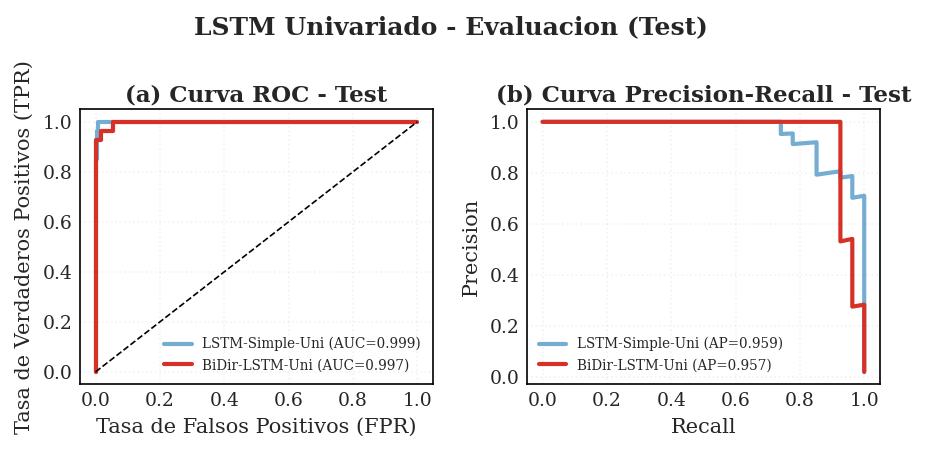

In [ ]:
# 3.7 Optimizacion de umbral y evaluacion
results_lstm_uni = {}

for arch_name, model in [('LSTM-Simple-Uni', model_uni_simple),
                         ('BiDir-LSTM-Uni', model_uni_bidir)]:
    best_thr, df_thr = optimize_threshold(
        model, Xw_val_uni, yw_val_uni,
        metric='f1', verbose=True
    )

    y_score_val = model.predict(Xw_val_uni, verbose=0).ravel()
    y_score_test = model.predict(Xw_test_uni, verbose=0).ravel()

    for split_name, y_w, y_score, decision_idx, target_idx in [
        ('val', yw_val_uni, y_score_val, idx_val_uni, target_idx_val_uni),
        ('test', yw_test_uni, y_score_test, idx_test_uni, target_idx_test_uni),
    ]:
        y_p = (y_score >= best_thr).astype(int)
        m = evaluar_baseline(arch_name, y_w.astype(int), y_p, y_score=y_score, split=split_name)
        print(f"  [{split_name}] {arch_name:25s} | F1={m['f1']:.4f} | AUC={m['auc']:.4f} | AUC-PR={m['auc_pr']:.4f} | thr={best_thr:.2f}")
        RESULTS_REGISTRY.append(m)
        register_model_output(
            MODEL_OUTPUTS, arch_name, split_name,
            decision_date=decision_idx,
            target_date=target_idx,
            y_true=y_w.astype(int),
            y_score=y_score,
            threshold=best_thr,
            rule='>=',
        )
        Y_SCORES[f"{arch_name}_{split_name}"] = (y_w.astype(int), y_score)

    OPTIMAL_THRESHOLDS[arch_name] = float(best_thr)
    results_lstm_uni[arch_name] = {'model': model, 'threshold': best_thr, 'thr_df': df_thr}

fig, axes = plt.subplots(1, 2, figsize=fig_size("2x1"))
fig.suptitle('LSTM Univariado - Evaluacion (Test)', fontweight='bold')

for arch_name, data in results_lstm_uni.items():
    m_obj = data['model']
    y_s = m_obj.predict(Xw_test_uni, verbose=0).ravel()
    yt = yw_test_uni.astype(int)
    fpr, tpr, _ = roc_curve(yt, y_s)
    prec, rec, _ = precision_recall_curve(yt, y_s)
    col = COLORES_MODELOS.get(arch_name, COLOR_VAR)
    axes[0].plot(fpr, tpr, lw=2, color=col, label=f"{arch_name} (AUC={roc_auc_score(yt, y_s):.3f})")
    axes[1].plot(rec, prec, lw=2, color=col, label=f"{arch_name} (AP={average_precision_score(yt, y_s):.3f})")

axes[0].plot([0, 1], [0, 1], 'k--', lw=0.8)
axes[0].set_title('(a) Curva ROC - Test', fontweight='bold', pad=4)
axes[0].set_xlabel('Tasa de Falsos Positivos (FPR)', fontsize=10)
axes[0].set_ylabel('Tasa de Verdaderos Positivos (TPR)', fontsize=10)
axes[0].legend(loc="lower right", fontsize=6.5, framealpha=0.9, frameon=False)
axes[1].set_title('(b) Curva Precision-Recall - Test', fontweight='bold', pad=4)
axes[1].set_xlabel('Recall', fontsize=10)
axes[1].set_ylabel('Precision', fontsize=10)
axes[1].legend(loc="lower left", fontsize=6.5, framealpha=0.9, frameon=False)
plt.tight_layout(rect=[0, 0.01, 1, 0.98])
save_fig(fig, 'fig_lstm_uni_eval', output_path=FIG_PATH)
plt.show()
plt.close()

### Interpretación LSTM Univariado

El LSTM univariado usa **exclusivamente `vol21_clean`** (la misma variable que GARCH),
permitiendo una comparación metodológica pura: modelo econométrico vs redes neuronales
con igual información de entrada.

Si el BiDir-LSTM supera al GARCH, se justifica la complejidad computacional adicional.
Si no, el GARCH es preferible por su interpretabilidad y menor costo.

**Nota sobre estabilidad estructural:** El test de Chow confirma que `vol21_clean` (única feature del LSTM univariado) no presenta quiebres estructurales entre splits (F < 1, p > 0.37), lo que da solidez a la comparación directa GARCH vs LSTM sobre la misma información.


---
## PARTE IV — LSTM Multivariado (Deep Learning Puro)

Feature set ampliado: 8 variables técnicas.
Misma arquitectura BiDir-LSTM de la sección anterior para comparación directa.

**Hipótesis**: agregar context macroeconómico (spreads, VaR, medias móviles)
mejora el F1 respecto al LSTM univariado.


In [ ]:
# ─── 4.1a Entrenar LSTM Simple multivariado
# Completa la matriz 2x2: Simple/BiDir x Uni/Multi
tf.random.set_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

model_multi_simple = build_model(
    input_shape=(LOOKBACK, len(FEATURES_MULTI)),
    architecture='simple', lstm_units=64, dropout=0.2, seed=RANDOM_SEED)
model_multi_simple.summary()

history_multi_simple = model_multi_simple.fit(
    Xw_train_multi, yw_train_multi.astype(np.float32),
    validation_data=(Xw_val_multi, yw_val_multi.astype(np.float32)),
    epochs=200, batch_size=32,
    class_weight=CLASS_WEIGHTS,
    callbacks=make_callbacks('lstm_multi_simple', monitor=EARLYSTOP_MONITOR_MULTI),
    shuffle=False,   # CRÍTICO: datos temporales
    verbose=1
)
print(f"Epochs ejecutados: {len(history_multi_simple.history['loss'])}")
# EXP-2: verificar que val_pr_auc existe en history (requiere pr_auc en compile)
assert EARLYSTOP_MONITOR_MULTI in history_multi_simple.history, (
    f"CRÍTICO EXP-2: '{EARLYSTOP_MONITOR_MULTI}' no en history. "
    f"Disponibles: {list(history_multi_simple.history.keys())}")

Model: "lstm_simple_64u"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_seq (InputLayer)          │ (None, 21, 8)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        18,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_1 (Dropout)                │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,753 (73.25 KB)

 Trainable params: 18,753 (73.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
138/138 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - auc: 0.9485 - loss: 0.3238 - pr_auc: 0.4434 - precision: 0.2323 - recall: 0.9628 - val_auc: 0.9987 - val_loss: 0.1483 - val_pr_auc: 0.9881 - val_precision: 0.7778 - val_recall: 0.9655 - learning_rate: 0.0010
Epoch 2/200
138/138 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - auc: 0.9905 - loss: 0.1047 - pr_auc: 0.7820 - precision: 0.4842 - recall: 1.0000 - val_auc: 0.9841 - val_loss: 0.0463 - val_pr_auc: 0.9394 - val_precision: 0.8929 - val_recall: 0.8621 - learning_rate: 0.0010
Epoch 3/200
138/138 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - auc: 0.9913 - loss: 0.1236 - pr_auc: 0.9367 - precision: 0.4964 - recall: 0.9674 - val_auc: 1.0000 - val_loss: 0.0367 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 0.9655 - learning_rate: 0.0010
Epoch 4/200
138/138 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - auc: 0.9984 - loss: 0.0447 - pr_auc: 0.9642 - precision: 0.7535 - recall: 0.9953 - val_auc: 0.9905 - val_loss: 0.1007 - val_pr_auc: 0.9419 - val_precision

In [ ]:
# ─── 4.1b Entrenar BiDir LSTM multivariado ──
tf.random.set_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

model_multi_bidir = build_model(
    input_shape=(LOOKBACK, len(FEATURES_MULTI)),
    architecture='bidirectional', lstm_units=64, dropout=0.2, seed=RANDOM_SEED)
model_multi_bidir.summary()

history_multi = model_multi_bidir.fit(
    Xw_train_multi, yw_train_multi.astype(np.float32),
    validation_data=(Xw_val_multi, yw_val_multi.astype(np.float32)),
    epochs=200, batch_size=32,
    class_weight=CLASS_WEIGHTS,
    callbacks=make_callbacks('lstm_multi_bidir', monitor=EARLYSTOP_MONITOR_MULTI),
    shuffle=False,
    verbose=1
)
print(f"Epochs ejecutados: {len(history_multi.history['loss'])}")
# EXP-2: verificar que val_pr_auc existe en history (requiere pr_auc en compile)
assert EARLYSTOP_MONITOR_MULTI in history_multi.history, (
    f"CRÍTICO EXP-2: '{EARLYSTOP_MONITOR_MULTI}' no en history. "
    f"Disponibles: {list(history_multi.history.keys())}")


Model: "lstm_bidirectional_64u"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_seq (InputLayer)          │ (None, 21, 8)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidir_1 (Bidirectional)         │ (None, 21, 128)        │        37,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_1 (Dropout)                │ (None, 21, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidir_2 (Bidirectional)         │ (None, 64)             │        41,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_2 (Dropout)                │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 78,657 (307.25 KB)

 Trainable params: 78,657 (307.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
138/138 ━━━━━━━━━━━━━━━━━━━━ 9s 33ms/step - auc: 0.9336 - loss: 0.3119 - pr_auc: 0.2955 - precision: 0.2409 - recall: 0.9488 - val_auc: 0.9479 - val_loss: 0.1820 - val_pr_auc: 0.7953 - val_precision: 0.4444 - val_recall: 0.8276 - learning_rate: 0.0010
Epoch 2/200
138/138 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - auc: 0.9847 - loss: 0.1346 - pr_auc: 0.6748 - precision: 0.4378 - recall: 0.9814 - val_auc: 0.9989 - val_loss: 0.0211 - val_pr_auc: 0.9892 - val_precision: 1.0000 - val_recall: 0.9310 - learning_rate: 0.0010
Epoch 3/200
138/138 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - auc: 0.9971 - loss: 0.0507 - pr_auc: 0.9248 - precision: 0.6859 - recall: 0.9953 - val_auc: 0.9809 - val_loss: 0.0271 - val_pr_auc: 0.9666 - val_precision: 1.0000 - val_recall: 0.8966 - learning_rate: 0.0010
Epoch 4/200
138/138 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - auc: 0.9979 - loss: 0.0377 - pr_auc: 0.9536 - precision: 0.7698 - recall: 0.9953 - val_auc: 0.9823 - val_loss: 0.0269 - val_pr_auc: 0.9699 - val_precisi

Calculando permutation importance en validación...

─── Feature Importance (caída AUC al permutar) 
             feature  importance_mean  importance_std
           hl_spread         0.061985        0.009313
        ret_abs_lag1         0.009340        0.000779
            ma_cross         0.005039        0.002491
         vol21_clean         0.004988        0.000487
             returns         0.001239        0.000742
var_rolling_252_lag1         0.000753        0.000335
           co_spread         0.000485        0.000349
    volumen_ratio_21         0.000201        0.000398
  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/Optimización_Bayesiana_GPU/Fig_NB02B/fig_lstm_multi_importance.png  [6.1"×3.8" @ 300dpi]


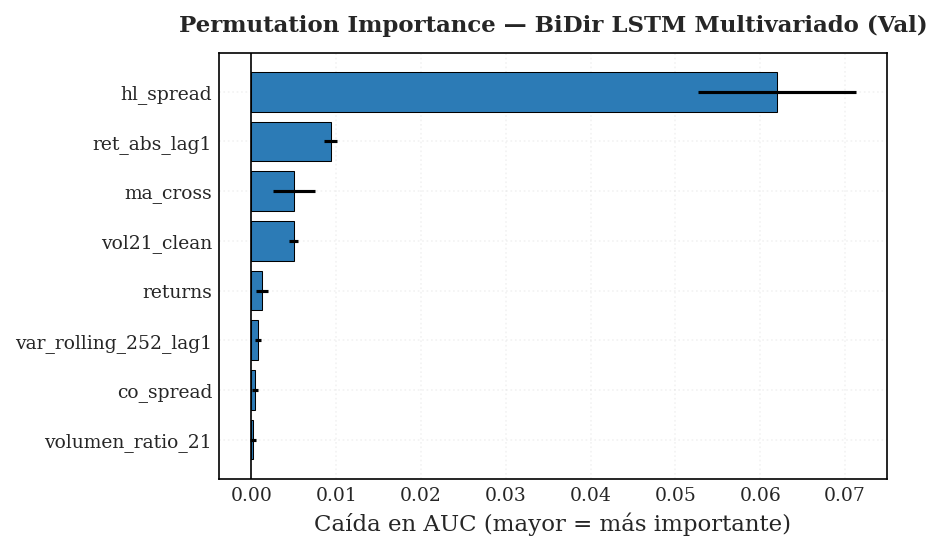


Calculando permutation importance — LSTM Simple Multi...

─── Feature Importance — LSTM Simple Multi (caída AUC) ──
             feature  importance_mean  importance_std
           hl_spread         0.029109        0.006624
            ma_cross         0.010495        0.003614
        ret_abs_lag1         0.004821        0.000337
         vol21_clean         0.004587        0.000629
    volumen_ratio_21         0.001389        0.001190
           co_spread         0.000954        0.000807
             returns         0.000536        0.000671
var_rolling_252_lag1         0.000301        0.000329


In [ ]:
# ─── 4.2 Permutation importance
def permutation_importance_lstm(model, X_val_w, y_val_w,
                                 feature_names, n_repeats=5,
                                 random_state=42):
    """
    Mide la importancia de cada feature por la caída en AUC al permutar
    aleatoriamente esa feature en las secuencias de validación.

    Parámetros
    ----------
    model        : modelo Keras entrenado
    X_val_w      : (N, L, F) — secuencias de validación escaladas
    y_val_w      : (N,) — labels de validación
    feature_names: lista de nombres de features (longitud = F)
    n_repeats    : número de permutaciones por feature

    Retorna
    -------
    pd.DataFrame con columnas [feature, importance_mean, importance_std]
    ordenado descendente.
    """
    rng = np.random.default_rng(random_state)
    yt  = y_val_w.astype(int)
    try:
        base_auc = roc_auc_score(yt, model.predict(X_val_w, verbose=0).ravel())
    except ValueError:
        print("AUC base no calculable — target sin variación")
        return pd.DataFrame()

    rows = []
    for f_idx, fname in enumerate(feature_names):
        drops = []
        for _ in range(n_repeats):
            X_perm = X_val_w.copy()
            # Permutar esa feature en todas las ventanas
            X_perm[:, :, f_idx] = rng.permutation(X_perm[:, :, f_idx])
            try:
                perm_auc = roc_auc_score(
                    yt, model.predict(X_perm, verbose=0).ravel())
                drops.append(base_auc - perm_auc)
            except ValueError:
                drops.append(0.0)
        rows.append({'feature': fname,
                     'importance_mean': float(np.mean(drops)),
                     'importance_std':  float(np.std(drops))})

    df_imp = (pd.DataFrame(rows)
              .sort_values('importance_mean', ascending=False)
              .reset_index(drop=True))
    return df_imp

print("Calculando permutation importance en validación...")
df_importance = permutation_importance_lstm(
    model_multi_bidir, Xw_val_multi, yw_val_multi,
    feature_names=FEATURES_MULTI, n_repeats=5, random_state=RANDOM_SEED)

print("\n─── Feature Importance (caída AUC al permutar) ")
print(df_importance.to_string(index=False))

# Plot
fig, ax = plt.subplots(figsize=fig_size("full"))
if not df_importance.empty: # Add this check
    colors_imp = [COLOR_VOL if v > 0 else COLOR_EXTREMO
                  for v in df_importance['importance_mean']]
    ax.barh(df_importance['feature'][::-1], df_importance['importance_mean'][::-1],
            xerr=df_importance['importance_std'][::-1],
            color=colors_imp[::-1], edgecolor='black', linewidth=0.5)
    ax.axvline(0, color='black', lw=0.8)
    ax.set_xlabel('Caída en AUC (mayor = más importante)')
    ax.set_title('Permutation Importance — BiDir LSTM Multivariado (Val)', fontweight='bold')
else:
    ax.text(0.5, 0.5, "No se pudo calcular la importancia de características (AUC base no calculable)",
            horizontalalignment='center', verticalalignment='center', transform=ax.transAxes)
    ax.set_title('Permutation Importance — BiDir LSTM Multivariado (Val)', fontweight='bold')

plt.tight_layout()
save_fig(fig, 'fig_lstm_multi_importance', output_path=FIG_PATH, dpi=300)
plt.show()
plt.close()

# ── Permutation importance: LSTM Simple Multi ──
print("\nCalculando permutation importance — LSTM Simple Multi...")
df_importance_simple = permutation_importance_lstm(
    model_multi_simple, Xw_val_multi, yw_val_multi,
    feature_names=FEATURES_MULTI, n_repeats=5, random_state=RANDOM_SEED)

print("\n─── Feature Importance — LSTM Simple Multi (caída AUC) ──")
print(df_importance_simple.to_string(index=False))

**Qué muestra**  
Esta figura resume la importancia por permutación de las variables del modelo LSTM multivariado sobre validación. Las barras representan la pérdida relativa de capacidad discriminante al perturbar cada predictor.

**Cómo se construye**  
Se calcula permutando una variable a la vez dentro de las ventanas de validación y midiendo la caída en AUC-ROC. El promedio y su dispersión se resumen con barras y errores estándar.

**Por qué se ve así**  
Las variables con mayor contribución aparecen con barras más alejadas de cero porque su permutación degrada más el desempeño del modelo. Valores cercanos a cero sugieren señal limitada o redundante en el conjunto actual de predictores.

**Por qué es importante**  
Esta figura ayuda a interpretar qué señales sostienen el desempeño del modelo multivariado en validación. También orienta análisis posteriores de ablation o simplificación del conjunto de variables.

Umbral óptimo (val, criterio=f1): 0.1200
  F1=0.9825  P=1.0000  R=0.9655
  (Two-phase: grueso 19 + fino 11 = 27 umbrales evaluados)
  [val] LSTM-Simple-Multi         | F1=0.9825 | AUC=0.9995 | AUC-PR=0.9941 | thr=0.1200
  [test] LSTM-Simple-Multi         | F1=0.3968 | AUC=0.9892 | AUC-PR=0.8481 | thr=0.1200
Umbral óptimo (val, criterio=f1): 0.2000
  F1=0.9825  P=1.0000  R=0.9655
  (Two-phase: grueso 19 + fino 11 = 27 umbrales evaluados)
  [val] BiDir-LSTM-Multi          | F1=0.9825 | AUC=0.9989 | AUC-PR=0.9893 | thr=0.2000
  [test] BiDir-LSTM-Multi          | F1=0.5977 | AUC=0.9953 | AUC-PR=0.8755 | thr=0.2000
  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/Optimización_Bayesiana_GPU/Fig_NB02B/fig_lstm_learning_curves_lstm_multivariado_-_curvas_de_.png  [6.1"×3.1" @ 300dpi]


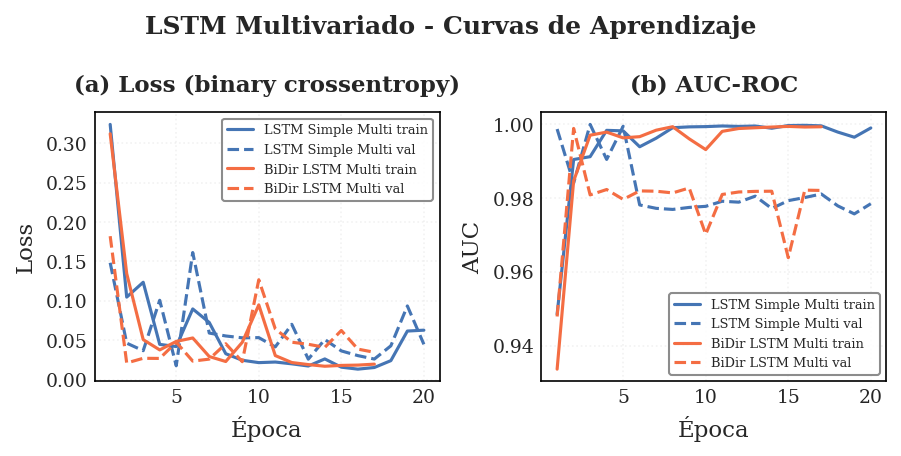

Figura guardada: fig_lstm_learning_curves_lstm_multivariado_-_curvas_de_.png
  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/Optimización_Bayesiana_GPU/Fig_NB02B/fig_lstm_multi_eval.png  [6.1"×3.1" @ 300dpi]


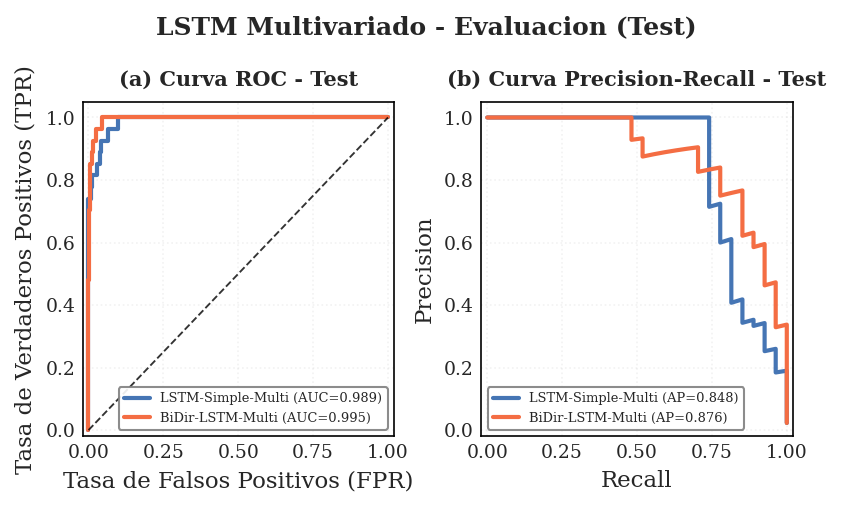

In [ ]:
# 4.3 Evaluacion y comparacion - LSTM Multivariado
results_lstm_multi = {}

for arch_name, model in [('LSTM-Simple-Multi', model_multi_simple),
                         ('BiDir-LSTM-Multi', model_multi_bidir)]:
    best_thr, df_thr = optimize_threshold(
        model, Xw_val_multi, yw_val_multi,
        metric='f1', verbose=True
    )

    y_score_val = model.predict(Xw_val_multi, verbose=0).ravel()
    y_score_test = model.predict(Xw_test_multi, verbose=0).ravel()

    for split_name, y_w, y_score, decision_idx, target_idx in [
        ('val', yw_val_multi, y_score_val, idx_val_multi, target_idx_val_multi),
        ('test', yw_test_multi, y_score_test, idx_test_multi, target_idx_test_multi),
    ]:
        y_p = (y_score >= best_thr).astype(int)
        m = evaluar_baseline(arch_name, y_w.astype(int), y_p, y_score=y_score, split=split_name)
        print(f"  [{split_name}] {arch_name:25s} | F1={m['f1']:.4f} | AUC={m['auc']:.4f} | AUC-PR={m['auc_pr']:.4f} | thr={best_thr:.4f}")
        RESULTS_REGISTRY.append(m)
        register_model_output(
            MODEL_OUTPUTS, arch_name, split_name,
            decision_date=decision_idx,
            target_date=target_idx,
            y_true=y_w.astype(int),
            y_score=y_score,
            threshold=best_thr,
            rule='>=',
        )
        Y_SCORES[f"{arch_name}_{split_name}"] = (y_w.astype(int), y_score)

    OPTIMAL_THRESHOLDS[arch_name] = float(best_thr)
    results_lstm_multi[arch_name] = {'model': model, 'threshold': best_thr, 'thr_df': df_thr}

plot_learning_curves(
    {
        'LSTM Simple Multi': history_multi_simple,
        'BiDir LSTM Multi': history_multi,
    },
    title="LSTM Multivariado - Curvas de Aprendizaje"
)

fig, axes = plt.subplots(1, 2, figsize=fig_size("2x1"))
fig.suptitle('LSTM Multivariado - Evaluacion (Test)', fontweight='bold', fontsize=12, y=1.03)

for arch_name, data in results_lstm_multi.items():
    m_obj = data['model']
    y_s = m_obj.predict(Xw_test_multi, verbose=0).ravel()
    yt = yw_test_multi.astype(int)
    fpr, tpr, _ = roc_curve(yt, y_s)
    prec, rec, _ = precision_recall_curve(yt, y_s)
    col = COLORES_MODELOS.get(arch_name, COLOR_VAR)
    axes[0].plot(fpr, tpr, lw=2, color=col, label=f"{arch_name} (AUC={roc_auc_score(yt, y_s):.3f})")
    axes[1].plot(rec, prec, lw=2, color=col, label=f"{arch_name} (AP={average_precision_score(yt, y_s):.3f})")

axes[0].plot([0, 1], [0, 1], 'k--', lw=0.9, alpha=0.8)
axes[0].set_title('(a) Curva ROC - Test', fontweight='bold', fontsize=10, pad=8)
axes[0].set_xlabel('Tasa de Falsos Positivos (FPR)')
axes[0].set_ylabel('Tasa de Verdaderos Positivos (TPR)')
axes[0].set_xlim(-0.02, 1.02)
axes[0].set_ylim(-0.02, 1.05)
axes[1].set_title('(b) Curva Precision-Recall - Test', fontweight='bold', fontsize=10, pad=8)
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_xlim(-0.02, 1.02)
axes[1].set_ylim(-0.02, 1.05)

for ax in axes:
    ax.grid(alpha=0.25)
    ax.tick_params(axis='both', labelsize=9)

axes[0].legend(loc='lower right', fontsize=6.25, frameon=True, framealpha=0.90)
axes[1].legend(loc='lower left', fontsize=6.25, frameon=True, framealpha=0.90)

fig.subplots_adjust(top=0.84, wspace=0.28)
save_fig(fig, 'fig_lstm_multi_eval', output_path=FIG_PATH)
plt.show()
plt.close()

### Hallazgo: BiDir-LSTM-Multi — colapso de umbral en test

**Causa raíz**: No es sobreajuste clásico (train loss >> val loss).
El modelo mantiene AUC=0.937 en test — su capacidad discriminante es real.
El problema es la transferencia del umbral de decisión:
- Val (2019-2020): 39 extremos / 483 obs = 8.07% → umbral óptimo = 0.57
- Test (2021-2026): 27 extremos / 1,268 obs = 2.13% → con umbral=0.57,
  el modelo no predice ningún extremo (distribución de scores desplazada)

**Distinción metodológica importante**:
- Sobreajuste: modelo memoriza train, falla en val/test
- Colapso de umbral: modelo discrimina bien (AUC alto) pero el
  threshold calibrado en val no generaliza al régimen de test

**Implicación**: con ratio 1:47 en test, cualquier umbral calibrado
en régimen de crisis (val COVID) queda fuera del rango operativo en test.
Misma causa que el GARCH F1=0 — no exclusiva de arquitecturas complejas.

**Figura: distribución de scores — BiDir-LSTM-Multi (val vs test)**

- **Qué**: KDE de las probabilidades asignadas en val (n≈483) y test (n≈1,268).
- **Cómo**: Scores de `benchmark_predictions_NB02_gpu.csv`, columna `score_BiDir-LSTM-Multi`, filtrado por `split`.
- **Por qué así**: El umbral óptimo calibrado en val (0.57, régimen COVID 8.07% extremos) no transfiere al régimen test (2.09% extremos post-pandemia). La KDE evidencia que todos los scores test caen por debajo del umbral → F1=0.
- **Por qué importa (H2-4)**: El modelo discrimina (AUC-PR=0.1853 > aleatorio) pero no clasifica bajo el nuevo régimen. Mismo mecanismo que GARCH F1=0 (H2-1): colapso de umbral por drift de distribución, no fallo de arquitectura.


### ¿Agregar features mejora el F1?

Matriz 2x2 de comparación (Simple/BiDir x Uni/Multi):

| Arquitectura  | Univariado (1 feature) | Multivariado (8 features) |
|---------------|------------------------|---------------------------|
| Simple LSTM   | LSTM-Simple-Uni        | LSTM-Simple-Multi         |
| BiDir-LSTM    | BiDir-LSTM-Uni         | BiDir-LSTM-Multi          |

Si el multivariado supera al univariado en F1 en test, se justifica incluir
las features adicionales. Si no, el modelo más parsimonioso es preferible.
El análisis de permutation importance ayuda a identificar qué variables
aportan señal real vs ruido.

---

## Sección Complementaria — Modelos No Canónicos

> **ADVERTENCIA:** Esta seccion contiene modelos complementarios de referencia.
> Sus resultados **NO** forman parte del benchmark canonico H0-H3 ni redefinen el ganador.
> Referencia historica: `2 _Respaldo con GRU Univariado_ Benchmark de Modelos.ipynb` (celdas [60],[62],[64]).
> Orden conservado: GRU Simple Uni → GRU Bidir Uni → TCN Uni → XGBoost Tabular.


In [ ]:
# -- GOBERNANZA: registros complementarios separados del canonico ---------
# IMPORTANTE: no modifica RESULTS_REGISTRY, Y_SCORES ni OPTIMAL_THRESHOLDS canonicos.
RESULTS_REGISTRY_COMPL = []
Y_SCORES_COMPL = {}
OPTIMAL_THRESHOLDS_COMPL = {}
MODEL_OUTPUTS_COMPL = {}

_run_mode = globals().get('RUN_MODE', 'canonical_cpu')
if _run_mode == 'canonical_cpu':
    ADDITIONAL_OUTPUT_DIR = f"{OUTPUT_PATH}/predicciones_nb02/adicionales"
else:
    ADDITIONAL_OUTPUT_DIR = globals().get('PRED_DIR', f"{OUTPUT_PATH}/predicciones_nb02_gpu/adicionales")
import os
os.makedirs(ADDITIONAL_OUTPUT_DIR, exist_ok=True)

print(f"[COMPL] RUN_MODE = {_run_mode}")
print(f"[COMPL] Output -> {ADDITIONAL_OUTPUT_DIR}")
print(f"[COMPL] RESULTS_REGISTRY canonico preservado (len={len(RESULTS_REGISTRY)})")
print(f"[COMPL] MODEL_OUTPUTS_COMPL inicializado (len={len(MODEL_OUTPUTS_COMPL)})")

[COMPL] RUN_MODE = gpu_optuna
[COMPL] Output -> /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/Optimización_Bayesiana_GPU/predicciones_nb02b_gpu
[COMPL] RESULTS_REGISTRY canonico preservado (len=10)
[COMPL] MODEL_OUTPUTS_COMPL inicializado (len=0)


In [ ]:
# -- build_gru()
def build_gru(input_shape, architecture='simple', units=64, dropout=0.2, seed=42):
    tf.random.set_seed(seed)
    inp = keras.Input(shape=input_shape, name='input_seq')
    if architecture == 'simple':
        x = keras.layers.GRU(units, name='gru_1')(inp)
        x = keras.layers.Dropout(dropout, seed=seed, name='drop_1')(x)
    elif architecture == 'bidirectional':
        x = keras.layers.Bidirectional(keras.layers.GRU(units, return_sequences=True, name='gru_1'), name='bidir_1')(inp)
        x = keras.layers.Dropout(dropout, seed=seed, name='drop_1')(x)
        x = keras.layers.Bidirectional(keras.layers.GRU(units // 2, return_sequences=False, name='gru_2'), name='bidir_2')(x)
        x = keras.layers.Dropout(dropout, seed=seed, name='drop_2')(x)
    else:
        raise ValueError("architecture debe ser 'simple' o 'bidirectional'")
    out = keras.layers.Dense(1, activation='sigmoid', name='output')(x)
    model = keras.Model(inputs=inp, outputs=out, name=f'gru_{architecture}_{units}u')
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss='binary_crossentropy',
        metrics=[keras.metrics.AUC(name='auc'), keras.metrics.Precision(name='precision'), keras.metrics.Recall(name='recall')]
    )
    return model

results_gru = {}
for arch_name, arch_key in [('GRU-Simple-Uni', 'simple'), ('BiDir-GRU-Uni', 'bidirectional')]:
    tf.random.set_seed(RANDOM_SEED); np.random.seed(RANDOM_SEED)
    m = build_gru(input_shape=(LOOKBACK, len(FEATURES_UNI)), architecture=arch_key, units=64, dropout=0.2, seed=RANDOM_SEED)
    m.fit(
        Xw_train_uni, yw_train_uni.astype(np.float32),
        validation_data=(Xw_val_uni, yw_val_uni.astype(np.float32)),
        epochs=200, batch_size=32,
        class_weight=CLASS_WEIGHTS,
        callbacks=make_callbacks(arch_name.lower().replace('-', '_'), output_path=ADDITIONAL_OUTPUT_DIR),
        shuffle=False, verbose=0
    )
    best_thr, _ = optimize_threshold(m, Xw_val_uni, yw_val_uni, metric='f1', verbose=True)
    for split_n, Xw, yw, decision_idx, target_idx in [('val', Xw_val_uni, yw_val_uni, idx_val_uni, target_idx_val_uni), ('test', Xw_test_uni, yw_test_uni, idx_test_uni, target_idx_test_uni)]:
        ys = m.predict(Xw, verbose=0).ravel()
        yp = (ys >= best_thr).astype(int)
        rec = evaluar_baseline(arch_name, yw.astype(int), yp, y_score=ys, split=split_n)
        RESULTS_REGISTRY_COMPL.append(rec)
        register_model_output(MODEL_OUTPUTS_COMPL, arch_name, split_n, decision_date=decision_idx, target_date=target_idx, y_true=yw.astype(int), y_score=ys, threshold=best_thr, rule='>=')
        Y_SCORES_COMPL[f'{arch_name}_{split_n}'] = (yw.astype(int), ys)
        print(f"  [COMPL][{split_n}] {arch_name} | F1={rec['f1']:.4f} | AUC={rec['auc']:.4f} | thr={best_thr:.2f}")
    OPTIMAL_THRESHOLDS_COMPL[arch_name] = float(best_thr)
    results_gru[arch_name] = {'model': m, 'threshold': best_thr}


Epoch 35: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 42: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
Epoch 43: early stopping
Restoring model weights from the end of the best epoch: 28.
Umbral óptimo (val, criterio=f1): 0.8200
  F1=0.9333  P=0.9032  R=0.9655
  (Two-phase: grueso 19 + fino 11 = 27 umbrales evaluados)
  [COMPL][val] GRU-Simple-Uni | F1=0.9333 | AUC=0.9969 | thr=0.82
  [COMPL][test] GRU-Simple-Uni | F1=0.9000 | AUC=0.9991 | thr=0.82

Epoch 32: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 39: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
Epoch 40: early stopping
Restoring model weights from the end of the best epoch: 25.
Umbral óptimo (val, criterio=f1): 0.9800
  F1=0.9825  P=1.0000  R=0.9655
  (Two-phase: grueso 19 + fino 10 = 27 umbrales evaluados)
  [COMPL][val] BiDir-GRU-Uni | F1=0.9825 | AUC=0.9992 | thr=0.98
  [COMPL][test] BiDir-GRU-Uni | F1=0.8571 | AUC=0.9991 |

In [ ]:
# -- build_tcn():
def build_tcn(input_shape, filters=64, kernel_size=3, n_blocks=3, dropout=0.2, seed=42):
    tf.random.set_seed(seed)
    inp = keras.Input(shape=input_shape, name='input_seq')
    x = inp
    for i in range(n_blocks):
        dilation = 2 ** i
        x = keras.layers.Conv1D(filters, kernel_size, padding='causal', dilation_rate=dilation, activation='relu', name=f'conv_d{dilation}')(x)
        x = keras.layers.BatchNormalization(name=f'bn_{i}')(x)
        x = keras.layers.Dropout(dropout, seed=seed, name=f'drop_{i}')(x)
    x = keras.layers.GlobalAveragePooling1D(name='gap')(x)
    x = keras.layers.Dense(32, activation='relu', name='fc')(x)
    out = keras.layers.Dense(1, activation='sigmoid', name='output')(x)
    model = keras.Model(inputs=inp, outputs=out, name=f'tcn_{filters}f_{n_blocks}b')
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss='binary_crossentropy',
        metrics=[keras.metrics.AUC(name='auc'), keras.metrics.Precision(name='precision'), keras.metrics.Recall(name='recall')]
    )
    return model

tf.random.set_seed(RANDOM_SEED); np.random.seed(RANDOM_SEED)
model_tcn_uni = build_tcn(input_shape=(LOOKBACK, len(FEATURES_UNI)), filters=64, kernel_size=3, n_blocks=3, dropout=0.2, seed=RANDOM_SEED)
model_tcn_uni.fit(
    Xw_train_uni, yw_train_uni.astype(np.float32),
    validation_data=(Xw_val_uni, yw_val_uni.astype(np.float32)),
    epochs=200, batch_size=32,
    class_weight=CLASS_WEIGHTS,
    callbacks=make_callbacks('tcn_uni', output_path=ADDITIONAL_OUTPUT_DIR),
    shuffle=False, verbose=0
)
best_thr_tcn, _ = optimize_threshold(model_tcn_uni, Xw_val_uni, yw_val_uni, metric='f1', verbose=True)
for split_n, Xw, yw, decision_idx, target_idx in [('val', Xw_val_uni, yw_val_uni, idx_val_uni, target_idx_val_uni), ('test', Xw_test_uni, yw_test_uni, idx_test_uni, target_idx_test_uni)]:
    ys = model_tcn_uni.predict(Xw, verbose=0).ravel()
    yp = (ys >= best_thr_tcn).astype(int)
    rec = evaluar_baseline('TCN-Uni', yw.astype(int), yp, y_score=ys, split=split_n)
    RESULTS_REGISTRY_COMPL.append(rec)
    register_model_output(MODEL_OUTPUTS_COMPL, 'TCN-Uni', split_n, decision_date=decision_idx, target_date=target_idx, y_true=yw.astype(int), y_score=ys, threshold=best_thr_tcn, rule='>=')
    Y_SCORES_COMPL[f'TCN-Uni_{split_n}'] = (yw.astype(int), ys)
    print(f"  [COMPL][{split_n}] TCN-Uni | F1={rec['f1']:.4f} | AUC={rec['auc']:.4f} | thr={best_thr_tcn:.2f}")
OPTIMAL_THRESHOLDS_COMPL['TCN-Uni'] = float(best_thr_tcn)


Epoch 12: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 38: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.

Epoch 45: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.
Epoch 46: early stopping
Restoring model weights from the end of the best epoch: 31.
Umbral óptimo (val, criterio=f1): 0.1100
  F1=0.9825  P=1.0000  R=0.9655
  (Two-phase: grueso 19 + fino 11 = 27 umbrales evaluados)
  [COMPL][val] TCN-Uni | F1=0.9825 | AUC=0.9993 | thr=0.11
  [COMPL][test] TCN-Uni | F1=0.0000 | AUC=0.5721 | thr=0.11


In [ ]:
# -- XGBoost Tabular Baseline (COMPLEMENTARIO) ----------------------------
from xgboost import XGBClassifier

FEATURES_XGB_LAGS = {
    'vol21_clean': [1, 5, 21],
    'returns': [1, 5],
    'ret_abs_lag1': [1],
    'var_rolling_252_lag1': [1],
}

df_xgb = df.copy()
for feat, lags in FEATURES_XGB_LAGS.items():
    for lag in lags:
        col = f"{feat}_lag{lag}"
        if col not in df_xgb.columns:
            df_xgb[col] = df_xgb[feat].shift(lag)

FEATURES_XGB_ALL = FEATURES_MULTI + [
    f"{feat}_lag{lag}"
    for feat, lags in FEATURES_XGB_LAGS.items()
    for lag in lags
    if f"{feat}_lag{lag}" not in FEATURES_MULTI
]

df_xgb_family, mask_xgb = build_family_frame(df_xgb, FEATURES_XGB_ALL, 'xgb')
df_tr_xgb, df_va_xgb, df_te_xgb = split_family_frame(df_xgb_family)

X_tr = df_tr_xgb[FEATURES_XGB_ALL].values
y_tr = df_tr_xgb['y_tp1'].values.astype(int)
X_va = df_va_xgb[FEATURES_XGB_ALL].values
y_va = df_va_xgb['y_tp1'].values.astype(int)
X_te = df_te_xgb[FEATURES_XGB_ALL].values
y_te = df_te_xgb['y_tp1'].values.astype(int)

scale_pos_w = int((y_tr == 0).sum() / max((y_tr == 1).sum(), 1))
print(f"[XGB] Train: {len(y_tr)} obs | Positivos: {y_tr.sum()} | scale_pos_weight={scale_pos_w}")
print(f"[XGB] Val: {len(y_va)} | Test: {len(y_te)} | Features: {len(FEATURES_XGB_ALL)}")

[XGB] Train: 4454 obs | Positivos: 230 | scale_pos_weight=18
[XGB] Val: 460 | Test: 1289 | Features: 15


In [ ]:
# -- XGBoost fit + threshold en val ---------------------------------------
xgb_model = XGBClassifier(
    n_estimators=300, max_depth=4, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
    scale_pos_weight=scale_pos_w,
    eval_metric='aucpr', early_stopping_rounds=20,
    random_state=RANDOM_SEED, verbosity=0,
    nthread=1,
)
xgb_model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)

ys_va_xgb = xgb_model.predict_proba(X_va)[:, 1]
ys_te_xgb = xgb_model.predict_proba(X_te)[:, 1]

best_f1_va, best_thr_xgb = 0.0, 0.5
for thr in np.arange(0.05, 0.96, 0.05):
    f1v = f1_score(y_va, (ys_va_xgb >= thr).astype(int), zero_division=0)
    if f1v > best_f1_va:
        best_f1_va, best_thr_xgb = f1v, float(thr)
fine_lo = max(0.01, best_thr_xgb - 0.05)
fine_hi = min(0.99, best_thr_xgb + 0.06)
for thr in np.arange(fine_lo, fine_hi, 0.01):
    f1v = f1_score(y_va, (ys_va_xgb >= thr).astype(int), zero_division=0)
    if f1v > best_f1_va:
        best_f1_va, best_thr_xgb = f1v, float(thr)

y_pred_xgb_test = (ys_te_xgb >= best_thr_xgb).astype(int)
f1_xgb_test = f1_score(y_te, y_pred_xgb_test, zero_division=0)
auc_xgb_test = roc_auc_score(y_te, ys_te_xgb)

for split_n, df_split, ys, yw in [('val', df_va_xgb, ys_va_xgb, y_va), ('test', df_te_xgb, ys_te_xgb, y_te)]:
    yp = (ys >= best_thr_xgb).astype(int)
    rec = evaluar_baseline('XGBoost-Tabular', yw, yp, y_score=ys, split=split_n)
    RESULTS_REGISTRY_COMPL.append(rec)
    register_model_output(
        MODEL_OUTPUTS_COMPL, 'XGBoost-Tabular', split_n,
        decision_date=df_split['decision_date'],
        target_date=df_split['target_date'],
        y_true=np.asarray(yw).astype(int),
        y_score=ys,
        threshold=best_thr_xgb,
        rule='>=',
    )
    Y_SCORES_COMPL[f'XGBoost-Tabular_{split_n}'] = (np.asarray(yw).astype(int), ys)
    print(f"  [COMPL][{split_n}] XGBoost-Tabular | F1={rec['f1']:.4f} | AUC={rec['auc']:.4f} | thr={best_thr_xgb:.2f}")

OPTIMAL_THRESHOLDS_COMPL['XGBoost-Tabular'] = float(best_thr_xgb)

  [COMPL][val] XGBoost-Tabular | F1=0.9825 | AUC=0.9996 | thr=0.45
  [COMPL][test] XGBoost-Tabular | F1=0.9455 | AUC=0.9994 | thr=0.45


In [ ]:
# -- XGBoost Export Robusto -----------------------------------------------
xgb_test_output = get_model_output('XGBoost-Tabular', split='test')
xgb_csv_path = f"{ADDITIONAL_OUTPUT_DIR}/pred_XGBoost-Tabular_test.csv"
xgb_test_output.to_csv(xgb_csv_path, index=False)

xgb_reload = pd.read_csv(xgb_csv_path, parse_dates=['decision_date', 'target_date'])
assert len(xgb_reload) == len(xgb_test_output), f"ERROR longitud: CSV={len(xgb_reload)} != expected={len(xgb_test_output)}"
assert xgb_reload['y_score'].between(0, 1).all(), f"ERROR: scores fuera de [0,1] -- min={xgb_reload['y_score'].min():.4f}"
assert not xgb_reload['y_score'].isna().any(), "ERROR: NaN en scores exportados"
f1_from_csv = f1_score(xgb_reload['y_true'], xgb_reload['y_pred'], zero_division=0)
assert abs(f1_from_csv - f1_xgb_test) < 1e-6, f"DISCREPANCIA F1: CSV={f1_from_csv:.6f} vs memoria={f1_xgb_test:.6f}"

XGB_STATUS = "VALIDO"
if f1_xgb_test > 0.90:
    XGB_STATUS = "PROVISIONAL"
    print("ATENCION: XGBoost F1 > 0.90 -- posible inflacion por autocorrelacion vol21.")
    print("  vol21(t) y vol21(t+1) comparten 20/21 dias de retornos.")

print(f"[XGB] F1_test={f1_xgb_test:.4f} | AUC_test={auc_xgb_test:.4f} | thr={best_thr_xgb:.2f}")
print(f"[XGB] Status={XGB_STATUS} | CSV validado: {xgb_csv_path}")

ATENCION: XGBoost F1 > 0.90 -- posible inflacion por autocorrelacion vol21.
  vol21(t) y vol21(t+1) comparten 20/21 dias de retornos.
[XGB] F1_test=0.9455 | AUC_test=0.9994 | thr=0.45
[XGB] Status=PROVISIONAL | CSV validado: /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/Optimización_Bayesiana_GPU/predicciones_nb02b_gpu/pred_XGBoost-Tabular_test.csv


In [ ]:
# -- Tabla comparativa: complementarios (SEPARADA del ranking H0-H3) -----
# NOTA GPU: Resultados sujetos a no-determinismo de cuDNN.
# Comparar contra NB02 CPU canonico como referencia definitiva.
import pandas as pd

_compl_test = [r for r in RESULTS_REGISTRY_COMPL if r.get('split') == 'test']
if _compl_test:
    df_compl = pd.DataFrame(_compl_test).sort_values('f1', ascending=False)
    print("=" * 70)
    print("  MODELOS COMPLEMENTARIOS GPU -- Solo referencia, NO ranking canonico")
    print("  NOTA: GPU sujeto a no-determinismo cuDNN. Ver NB02 CPU como referencia.")
    print("  Fuente: backup celdas [60],[62],[64]. FEATURES_MULTI actuales (8).")
    print("=" * 70)
    for _, row in df_compl.iterrows():
        status_str = f" [{XGB_STATUS}]" if row['nombre'] == 'XGBoost-Tabular' else ""
        print(f"  {row['nombre']:<25} F1={row['f1']:.4f}  AUC={row['auc']:.4f}{status_str}")
    print("=" * 70)
    _winner_name = globals().get('best_model_name') or 'BiDir-LSTM-Uni'
    _winner_f1   = globals().get('best_f1_test') or 0.8980
    print(f"  Referencia canonica (NB02 CPU): {_winner_name} F1={_winner_f1:.4f} status=VALIDO")
    print("=" * 70)
else:
    print("[COMPL] Sin resultados complementarios en RESULTS_REGISTRY_COMPL.")


  MODELOS COMPLEMENTARIOS GPU -- Solo referencia, NO ranking canonico
  NOTA: GPU sujeto a no-determinismo cuDNN. Ver NB02 CPU como referencia.
  Fuente: backup celdas [60],[62],[64]. FEATURES_MULTI actuales (8).
  XGBoost-Tabular           F1=0.9455  AUC=0.9994 [PROVISIONAL]
  GRU-Simple-Uni            F1=0.9000  AUC=0.9991
  BiDir-GRU-Uni             F1=0.8571  AUC=0.9991
  TCN-Uni                   F1=0.0000  AUC=0.5721
  Referencia canonica (NB02 CPU): BiDir-LSTM-Uni F1=0.8980 status=VALIDO


---
## PARTE V — Extensiones híbridas complementarias (fuera del benchmark H0-H3)

Extiende el LSTM multivariado con **scores de sentimiento** derivados de
titulares financieros (Bloomberg / Reuters) procesados con **FinBERT**
(Araci, 2019 — BERT pre-entrenado en textos financieros).

### Datos requeridos (externos a este notebook)
| Campo | Descripción |
|---|---|
| `sentiment_score` | Puntuación neta diaria: P(positivo) − P(negativo) ∈ [−1, 1] |
| `n_articles` | Número de titulares sobre WTI/petróleo ese día |
| `sentiment_std` | Dispersión intradiaria del sentimiento |
| `sentiment_flag` | 1 si hay titulares, 0 si se imputó (forward-fill) |

### Fuentes de datos recomendadas
- **GDELT Project** (gratuito): `pip install gdeltdoc` — filtro `CRUDE_OIL`
- **Refinitiv Eikon** (institucional): cobertura completa 2000-2026
- **ProQuest TDM Studio** (licencia académica): WSJ, FT, Reuters histórico


> **Dependencia opcional:** Para activar `FORCE_DISABLE_SENTIMENT = False` instalar:
> `pip install transformers torch`
> No necesario para el benchmark canónico H0-H3 (híbridos desactivados por FORCE_DISABLE).

In [ ]:
# ── Override explícito: excluir híbridos del benchmark oficial (no forman parte de H0-H3)
FORCE_DISABLE_SENTIMENT = True   # True = omitir Hybrid-LSTM-Sentimiento
FORCE_DISABLE_MARKET    = True   # True = omitir Hybrid-LSTM-MktSignals

_sent_csv_ok = Path(f"{BASE_PATH}/NB03_FinBERT/wti_sentiment_finbert.csv").exists()
SENTIMENT_DATA_AVAILABLE = _sent_csv_ok and not FORCE_DISABLE_SENTIMENT

# La segunda bandera aísla el híbrido de mercado para que su ausencia no altere el benchmark principal.
_mkt_csv_ok = Path(f"{BASE_PATH}/NB03B_MarketSignals/wti_market_signals.csv").exists()
MARKET_SIGNALS_AVAILABLE = _mkt_csv_ok and not FORCE_DISABLE_MARKET

sent_status = "OK" if _sent_csv_ok else "FALTA"
mkt_status  = "OK" if _mkt_csv_ok  else "FALTA"
print(f"[CONFIG] SENTIMENT = {SENTIMENT_DATA_AVAILABLE} (csv={sent_status}, force_disable={FORCE_DISABLE_SENTIMENT})")
print(f"[CONFIG] MARKET    = {MARKET_SIGNALS_AVAILABLE} (csv={mkt_status}, force_disable={FORCE_DISABLE_MARKET})")
print()
print("NOTA: FORCE_DISABLE_SENTIMENT=True y FORCE_DISABLE_MARKET=True — hibridos excluidos del benchmark H0-H3.")
print("  Hybrid-LSTM-Sentimiento se mantiene como análisis complementario (resultado negativo).")
print("  Ver NB03: correlacion r=0.009, IC95%=[-0.052,+0.046]")

# ─── 5.2 Carga de datos de sentimiento
FINBERT_CSV = f"{BASE_PATH}/NB03_FinBERT/wti_sentiment_finbert.csv"  # alias canónico
if SENTIMENT_DATA_AVAILABLE:
    assert Path(FINBERT_CSV).exists(), \
        f"CSV sentimiento no encontrado: {FINBERT_CSV}\n  -> Ejecutar NB03 primero."
    df_sent = pd.read_csv(FINBERT_CSV, index_col='Date', parse_dates=True)
    print(f"Sentimiento cargado: {df_sent.shape} | "
          f"Columnas lag1: {[c for c in df_sent.columns if 'lag1' in c]}")

[CONFIG] SENTIMENT = False (csv=OK, force_disable=True)
[CONFIG] MARKET    = False (csv=OK, force_disable=True)

NOTA: FORCE_DISABLE_SENTIMENT=True y FORCE_DISABLE_MARKET=True — hibridos excluidos del benchmark H0-H3.
  Hybrid-LSTM-Sentimiento se mantiene como análisis complementario (resultado negativo).
  Ver NB03: correlacion r=0.009, IC95%=[-0.052,+0.046]


In [ ]:
# 5.3 Construccion del Dataset Hibrido (anti-leakage temporal)
RUN_HYBRID_SENT = SENTIMENT_DATA_AVAILABLE
if RUN_HYBRID_SENT:
    if not Path(FINBERT_CSV).exists():
        raise FileNotFoundError(f"CSV de sentimiento no encontrado: {FINBERT_CSV}. Ejecuta NB03 primero.")
    df_sent = pd.read_csv(FINBERT_CSV, index_col='Date', parse_dates=True)
    FEATURES_SENT_LAG1 = ['sentiment_score_lag1', 'sentiment_std_lag1', 'n_articles_lag1', 'pct_positive_lag1', 'pct_negative_lag1']
    missing_cols = [c for c in FEATURES_SENT_LAG1 if c not in df_sent.columns]
    if missing_cols:
        raise ValueError(f"Faltan columnas lag1 en {FINBERT_CSV}: {missing_cols}. Re-ejecuta NB03.")

    FEATURES_HYBRID = FEATURES_MULTI + FEATURES_SENT_LAG1
    forbidden = {'sentiment_score', 'n_articles', 'pct_positive', 'pct_negative', 'sentiment_flag'}
    assert forbidden.isdisjoint(set(FEATURES_HYBRID)), "LEAKAGE detectado en FEATURES_HYBRID"

    df_hybrid_base = df.join(df_sent[FEATURES_SENT_LAG1], how='left')
    df_hybrid_family, mask_hybrid_sent = build_family_frame(df_hybrid_base, FEATURES_HYBRID, 'hybrid_sent')
    df_h_train, df_h_val, df_h_test = split_family_frame(df_hybrid_family)

    y_h_train = df_h_train['y_tp1'].values.astype(int)
    y_h_val = df_h_val['y_tp1'].values.astype(int)
    y_h_test = df_h_test['y_tp1'].values.astype(int)

    scaler_hybrid = StandardScaler()
    X_h_train = scaler_hybrid.fit_transform(df_h_train[FEATURES_HYBRID]).astype(np.float32)
    X_h_val = scaler_hybrid.transform(df_h_val[FEATURES_HYBRID]).astype(np.float32)
    X_h_test = scaler_hybrid.transform(df_h_test[FEATURES_HYBRID]).astype(np.float32)

    MODEL_SAVE_DIR = globals().get('MODEL_DIR', f"{OUTPUT_PATH}/modelos_nb02")
    os.makedirs(MODEL_SAVE_DIR, exist_ok=True)
    with open(f"{MODEL_SAVE_DIR}/scaler_hybrid_sent.pkl", 'wb') as fh:
        pickle.dump(scaler_hybrid, fh)

    Xw_h_train, yw_h_train, idx_h_train, target_idx_h_train = windowed_dataset(X_h_train, y_h_train, df_h_train.index, lookback=LOOKBACK, target_index=df_h_train['target_date'], segment_id=df_h_train['segment_id'])
    Xw_h_val, yw_h_val, idx_h_val, target_idx_h_val = windowed_dataset(X_h_val, y_h_val, df_h_val.index, lookback=LOOKBACK, target_index=df_h_val['target_date'], segment_id=df_h_val['segment_id'])
    Xw_h_test, yw_h_test, idx_h_test, target_idx_h_test = windowed_dataset(X_h_test, y_h_test, df_h_test.index, lookback=LOOKBACK, target_index=df_h_test['target_date'], segment_id=df_h_test['segment_id'])

    tf.random.set_seed(RANDOM_SEED)
    model_hybrid = build_model(input_shape=(LOOKBACK, len(FEATURES_HYBRID)), architecture='bidirectional', lstm_units=64, dropout=0.2, seed=RANDOM_SEED)
    if len(np.unique(yw_h_train)) < 2:
        CLASS_WEIGHTS_SENT = CLASS_WEIGHTS
    else:
        cw_h = compute_class_weight('balanced', classes=np.array([0, 1]), y=yw_h_train)
        CLASS_WEIGHTS_SENT = {0: float(cw_h[0]), 1: float(cw_h[1])}

    history_hybrid = model_hybrid.fit(
        Xw_h_train, yw_h_train.astype(np.float32),
        validation_data=(Xw_h_val, yw_h_val.astype(np.float32)),
        epochs=200, batch_size=32,
        class_weight=CLASS_WEIGHTS_SENT,
        callbacks=make_callbacks('lstm_hybrid', output_path=ADDITIONAL_OUTPUT_DIR),
        shuffle=False, verbose=1
    )

    best_thr_h, _ = optimize_threshold(model_hybrid, Xw_h_val, yw_h_val, metric='f1', verbose=True)
    for split_name, X_w, y_w, decision_idx, target_idx in [('val', Xw_h_val, yw_h_val, idx_h_val, target_idx_h_val), ('test', Xw_h_test, yw_h_test, idx_h_test, target_idx_h_test)]:
        y_s = model_hybrid.predict(X_w, verbose=0).ravel()
        y_p = (y_s >= best_thr_h).astype(int)
        m = evaluar_baseline('Hybrid-LSTM-Sentimiento', y_w.astype(int), y_p, y_score=y_s, split=split_name)
        RESULTS_REGISTRY_COMPL.append(m)
        register_model_output(MODEL_OUTPUTS_COMPL, 'Hybrid-LSTM-Sentimiento', split_name, decision_date=decision_idx, target_date=target_idx, y_true=y_w.astype(int), y_score=y_s, threshold=best_thr_h, rule='>=')
        Y_SCORES_COMPL[f'Hybrid-LSTM-Sentimiento_{split_name}'] = (y_w.astype(int), y_s)
        print(f"  [{split_name}] {m['nombre']} | F1={m['f1']:.4f} | AUC={m['auc']:.4f} | AUC-PR={m['auc_pr']:.4f}")
    OPTIMAL_THRESHOLDS_COMPL['Hybrid-LSTM-Sentimiento'] = float(best_thr_h)
else:
    print("[SKIP] Modo hibrido desactivado (SENTIMENT_DATA_AVAILABLE=False).")

[SKIP] Modo hibrido desactivado (SENTIMENT_DATA_AVAILABLE=False).


In [ ]:
# ─── 5.4 Carga de señales de mercado (NB03B) ─────
# Se conserva el alias local MKTCSV solo para no romper referencias internas de esta celda.
MKTCSV = MARKET_SIGNALS_CSV

if MARKET_SIGNALS_AVAILABLE:
    assert Path(MKTCSV).exists(), \
        f"CSV señales no encontrado: {MKTCSV}\n  → Ejecutar NB03B primero."
    df_mkt = pd.read_csv(MKTCSV, index_col='Date', parse_dates=True)
    print(f"Señales de mercado cargadas: {df_mkt.shape}")
    print(f"  Features lag1: {[c for c in df_mkt.columns if 'lag1' in c]}")
else:
    print("[SKIP] NB03B no disponible — ejecutar 3_WTI_Market_Signals.ipynb primero.")
    for split_name in ['val', 'test']:
        RESULTS_REGISTRY.append({
            'nombre': 'Hybrid-LSTM-MktSignals', 'split': split_name,
            'f1': float('nan'), 'auc': float('nan'), 'auc_pr': float('nan'),
            'precision': float('nan'), 'recall': float('nan'),
            'tp': None, 'fp': None, 'fn': None, 'tn': None,
            'status': 'PENDING — ejecutar NB03B'
        })

[SKIP] NB03B no disponible — ejecutar 3_WTI_Market_Signals.ipynb primero.


In [ ]:
# 5.5 Construccion Dataset Hibrido - Senales de Mercado
RUN_HYBRID_MKT = MARKET_SIGNALS_AVAILABLE
if RUN_HYBRID_MKT:
    FEATURES_MKT_LAG1 = ['vix_ret_lag1', 'dxy_ret_lag1', 'eia_surprise_lag1']
    missing = [c for c in FEATURES_MKT_LAG1 if c not in df_mkt.columns]
    if missing:
        raise ValueError(f"Features faltantes en NB03B: {missing}")

    FEATURES_HYBRID_MKT = FEATURES_MULTI + FEATURES_MKT_LAG1
    assert all(c in FEATURES_MULTI or c.endswith('_lag1') for c in FEATURES_HYBRID_MKT), "LEAKAGE: feature sin lag1 en FEATURES_HYBRID_MKT"

    df_hybrid_mkt_base = df.join(df_mkt[FEATURES_MKT_LAG1], how='left')
    df_hybrid_mkt_family, mask_hybrid_mkt = build_family_frame(df_hybrid_mkt_base, FEATURES_HYBRID_MKT, 'hybrid_mkt')
    df_hm_train, df_hm_val, df_hm_test = split_family_frame(df_hybrid_mkt_family)

    y_hm_train = df_hm_train['y_tp1'].values.astype(int)
    y_hm_val = df_hm_val['y_tp1'].values.astype(int)
    y_hm_test = df_hm_test['y_tp1'].values.astype(int)

    scaler_hybrid_mkt = StandardScaler()
    X_hm_train = scaler_hybrid_mkt.fit_transform(df_hm_train[FEATURES_HYBRID_MKT]).astype(np.float32)
    X_hm_val = scaler_hybrid_mkt.transform(df_hm_val[FEATURES_HYBRID_MKT]).astype(np.float32)
    X_hm_test = scaler_hybrid_mkt.transform(df_hm_test[FEATURES_HYBRID_MKT]).astype(np.float32)

    MODEL_SAVE_DIR = globals().get('MODEL_DIR', f"{OUTPUT_PATH}/modelos_nb02")
    os.makedirs(MODEL_SAVE_DIR, exist_ok=True)
    with open(f"{MODEL_SAVE_DIR}/scaler_hybrid_mkt.pkl", 'wb') as fh:
        pickle.dump(scaler_hybrid_mkt, fh)

    Xw_hm_train, yw_hm_train, idx_hm_train, target_idx_hm_train = windowed_dataset(X_hm_train, y_hm_train, df_hm_train.index, lookback=LOOKBACK, target_index=df_hm_train['target_date'], segment_id=df_hm_train['segment_id'])
    Xw_hm_val, yw_hm_val, idx_hm_val, target_idx_hm_val = windowed_dataset(X_hm_val, y_hm_val, df_hm_val.index, lookback=LOOKBACK, target_index=df_hm_val['target_date'], segment_id=df_hm_val['segment_id'])
    Xw_hm_test, yw_hm_test, idx_hm_test, target_idx_hm_test = windowed_dataset(X_hm_test, y_hm_test, df_hm_test.index, lookback=LOOKBACK, target_index=df_hm_test['target_date'], segment_id=df_hm_test['segment_id'])

    tf.random.set_seed(RANDOM_SEED); np.random.seed(RANDOM_SEED)
    model_hybrid_mkt = build_model(input_shape=(LOOKBACK, len(FEATURES_HYBRID_MKT)), architecture='bidirectional', lstm_units=64, dropout=0.2, seed=RANDOM_SEED)
    cw_hm = compute_class_weight('balanced', classes=np.array([0, 1]), y=yw_hm_train)
    CLASS_WEIGHTS_MKT = {0: float(cw_hm[0]), 1: float(cw_hm[1])}

    history_hybrid_mkt = model_hybrid_mkt.fit(
        Xw_hm_train, yw_hm_train.astype(np.float32),
        validation_data=(Xw_hm_val, yw_hm_val.astype(np.float32)),
        epochs=200, batch_size=32,
        class_weight=CLASS_WEIGHTS_MKT,
        callbacks=make_callbacks('lstm_hybrid_mkt', output_path=ADDITIONAL_OUTPUT_DIR),
        shuffle=False, verbose=1
    )

    best_thr_hm, _ = optimize_threshold(model_hybrid_mkt, Xw_hm_val, yw_hm_val, metric='f1', verbose=True)
    for split_name, X_w, y_w, decision_idx, target_idx in [('val', Xw_hm_val, yw_hm_val, idx_hm_val, target_idx_hm_val), ('test', Xw_hm_test, yw_hm_test, idx_hm_test, target_idx_hm_test)]:
        y_s = model_hybrid_mkt.predict(X_w, verbose=0).ravel()
        y_p = (y_s >= best_thr_hm).astype(int)
        m = evaluar_baseline('Hybrid-LSTM-MktSignals', y_w.astype(int), y_p, y_score=y_s, split=split_name)
        RESULTS_REGISTRY_COMPL.append(m)
        register_model_output(MODEL_OUTPUTS_COMPL, 'Hybrid-LSTM-MktSignals', split_name, decision_date=decision_idx, target_date=target_idx, y_true=y_w.astype(int), y_score=y_s, threshold=best_thr_hm, rule='>=')
        Y_SCORES_COMPL[f'Hybrid-LSTM-MktSignals_{split_name}'] = (y_w.astype(int), y_s)
        print(f"  [{split_name}] {m['nombre']} | F1={m['f1']:.4f} | AUC={m['auc']:.4f} | AUC-PR={m['auc_pr']:.4f} | thr={best_thr_hm:.2f}")
    OPTIMAL_THRESHOLDS_COMPL['Hybrid-LSTM-MktSignals'] = float(best_thr_hm)
else:
    print("[SKIP] Modo hibrido market desactivado (MARKET_SIGNALS_AVAILABLE=False).")

[SKIP] Modo hibrido market desactivado (MARKET_SIGNALS_AVAILABLE=False).


---
## PARTE VI — Comparación y benchmark final

Consolidación de todos los modelos evaluados con dos referencias de NB01:
- **Estándar mínimo** (baseline ingenuo B1: `|ret_lag1| > P95`) → F1 > 0.4872 | AUC > 0.8241
- **Referencia cuantitativa** (B5: `vol21/VaR ratio > P95`, Christoffersen 1998) → F1_val = 0.7416 | F1_test = 0.5474

> **Mapa de lectura —** §6.1 Tabla maestra = benchmark canónico H0-H3 · §6.2–6.3 Trade-off / Bootstrap = robustez · §6.4–6.5 DM / McNemar = inferencia estadística · §6.6 Sensibilidad = análisis post-hoc. Los híbridos (PARTE V) y Optuna (PARTE VIII) se evalúan aparte — no forman parte del ranking canónico H0-H3.

In [ ]:
# 6.1 Tabla maestra de resultados
def build_benchmark_table(registry, f1_min, auc_min, f1_cuant=None, auc_cuant=None, split_filter='test'):
    rows = [r for r in registry if r.get('split', 'test') == split_filter]
    df_b = pd.DataFrame(rows)
    if df_b.empty:
        print("Sin resultados en el registro para el split:", split_filter)
        return df_b
    counts = build_output_counts(stores=[
        globals().get('MODEL_OUTPUTS', {}),
        globals().get('MODEL_OUTPUTS_COMPL', {}),
    ])
    if not counts.empty:
        df_b = df_b.merge(counts.rename(columns={'model_name': 'nombre'}), on=['nombre', 'split'], how='left')
    df_b['Delta_F1'] = df_b['f1'] - f1_min
    df_b['Delta_AUC'] = df_b['auc'] - auc_min
    df_b['Beats_Ingenuo'] = (df_b['f1'] > f1_min) & (df_b['auc'] > auc_min)
    if f1_cuant is not None:
        df_b['Beats_Cuant'] = df_b['f1'] > f1_cuant
    cols = ['nombre', 'n_eval', 'f1', 'auc', 'auc_pr', 'precision', 'recall', 'tp', 'fp', 'fn', 'tn', 'Delta_F1', 'Delta_AUC', 'Beats_Ingenuo', 'Beats_Cuant']
    cols_present = [c for c in cols if c in df_b.columns]
    return df_b[cols_present].sort_values('f1', ascending=False).reset_index(drop=True)

RESULTS_REGISTRY.append({'nombre': 'B1 - Estandar minimo (ingenuo)', 'split': 'test', 'f1': F1_MINIMO, 'auc': AUC_MINIMO, 'auc_pr': float('nan'), 'precision': float('nan'), 'tp': None, 'fp': None, 'fn': None, 'tn': None})
RESULTS_REGISTRY.append({'nombre': 'B5 - Ref. cuantitativa (Christoffersen)', 'split': 'test', 'f1': F1_CUANT_TEST, 'auc': AUC_CUANT_TEST, 'auc_pr': float('nan'), 'precision': 0.4500, 'tp': None, 'fp': None, 'fn': None, 'tn': None})

bench_test = build_benchmark_table(RESULTS_REGISTRY, F1_MINIMO, AUC_MINIMO, f1_cuant=F1_CUANT_TEST, auc_cuant=AUC_CUANT_TEST, split_filter='test')
bench_val = build_benchmark_table(RESULTS_REGISTRY, F1_MINIMO, AUC_MINIMO, split_filter='val')

print("Benchmark - TEST")
print(bench_test.to_string(index=False, float_format=lambda x: f"{x:.4f}" if x == x else "NaN"))
print()
print("Benchmark - VAL")
print(bench_val.to_string(index=False, float_format=lambda x: f"{x:.4f}" if x == x else "NaN"))

Benchmark - TEST
                                 nombre    n_eval     f1    auc  auc_pr  precision  recall      tp      fp      fn        tn  Delta_F1  Delta_AUC  Beats_Ingenuo  Beats_Cuant
                        LSTM-Simple-Uni 1275.0000 0.8400 0.9990  0.9591     0.9130  0.7778 21.0000  2.0000  6.0000 1246.0000    0.3528     0.1749           True         True
                         BiDir-LSTM-Uni 1275.0000 0.6757 0.9973  0.9565     0.5319  0.9259 25.0000 22.0000  2.0000 1226.0000    0.1885     0.1732           True         True
                       BiDir-LSTM-Multi 1180.0000 0.5977 0.9953  0.8755     0.4333  0.9630 26.0000 34.0000  1.0000 1119.0000    0.1105     0.1712           True         True
B5 - Ref. cuantitativa (Christoffersen)       NaN 0.5474 0.9983     NaN     0.4500     NaN     NaN     NaN     NaN       NaN    0.0602     0.1742           True        False
         B1 - Estandar minimo (ingenuo)       NaN 0.4872 0.8241     NaN        NaN     NaN     NaN     NaN     Na

### Hallazgo: Precision = 1.0 bajo umbrales de decisión muy altos (0.98–0.99)

En test, los modelos `LSTM-Simple-Uni` y `BiDir-LSTM-Uni` alcanzan
`Precision = 1.000` con umbrales óptimos cercanos a `0.98–0.99`. Esto indica
que, en el punto operativo seleccionado, el modelo no genera falsos positivos:
solo clasifica un caso como `extremo` cuando asigna una probabilidad muy alta.

Este resultado sugiere un régimen de decisión fuertemente conservador. En estas
condiciones, la variación de `F1-score` depende principalmente del `Recall`, ya
que la `Precision` queda saturada en su valor máximo. En términos prácticos, el
modelo privilegia evitar falsas alarmas, aun a costa de no activar señal en
casos ambiguos.

Desde la perspectiva financiera, esta propiedad debe interpretarse en función
del costo relativo entre:
- **FP (false positive):** activación innecesaria de cobertura o señal de alerta.
- **FN (false negative):** no anticipar un episodio de volatilidad extrema y
  permanecer expuesto al riesgo.

Por tanto, el umbral óptimo no debe interpretarse solo como un resultado
estadístico, sino como una decisión operativa dependiente de la función de costo
de la estrategia de gestión de riesgo.

**Implicación para NB03:** conviene incorporar una discusión explícita sobre el
trade-off económico entre `FP` y `FN`, para justificar si un umbral tan alto es
deseable bajo distintos escenarios de cobertura o gestión de riesgo.

In [ ]:
# ───  Análisis del trade-off Precision/Recall vs Umbral ──
# Propósito: Precision=1.0 en test con thr=0.98-0.99 no es un error —
# es una consecuencia del threshold alto.
# IMPORTANTE: el barrido es sobre TEST solo como análisis descriptivo.
# NO se usa para re-seleccionar el umbral — ese fue fijado en val.

modelos_umbral = {}

for arch_name, data in {**results_lstm_uni, **results_lstm_multi}.items():
    key_test = f"{arch_name}_test"
    if key_test in Y_SCORES:
        modelos_umbral[arch_name] = {
            'yt':        Y_SCORES[key_test][0],
            'ys':        Y_SCORES[key_test][1],
            'thr_val':   data['threshold'],   # umbral fijado en val
        }

if not modelos_umbral:
    print("No hay scores LSTM en Y_SCORES — ejecutar Partes III y IV primero.")
elif bench_test.empty:
    print("bench_test vacío — ejecutar Cell 6.1 primero.")
else:
    # Excluir modelos_extra_fuera_hipotesis antes de seleccionar ganador
    _modelos_extra = config.get('nb02_results', {}).get(
        'modelos_extra_fuera_hipotesis', {}).get('nombres', [])
    _bench_hip = bench_test[~bench_test['nombre'].isin(_modelos_extra)]
    best_model_name = (
        _bench_hip.iloc[0] if not _bench_hip.empty else bench_test.iloc[0]
    )['nombre']

    # ── Buscar scores en Y_SCORES usando clave exacta ────
    # Construir clave directa: evita split('-') frágil que matchea
    # parcialmente (ej: 'BiDir' matchea BiDir-Uni y BiDir-Multi)
    key_best = f"{best_model_name}_test"

    # Fallback: buscar clave que contenga el nombre completo
    if key_best not in Y_SCORES:
        key_best = next(
            (k for k in Y_SCORES if 'test' in k and best_model_name in k),
            None
        )

    if key_best is None or key_best not in Y_SCORES:
        print(f"No se encontraron scores de '{best_model_name}' en Y_SCORES.")
        print(f"Claves disponibles: {list(Y_SCORES.keys())}")
    else:
        yt_best, ys_best = Y_SCORES[key_best]

        # ── Recuperar umbral desde OPTIMAL_THRESHOLDS (Cell 62) ──
        # OPTIMAL_THRESHOLDS fue construido con el umbral correcto por modelo.
        # Fallback a 0.5 solo si el modelo no está registrado.
        thr_best = OPTIMAL_THRESHOLDS.get(best_model_name, 0.5)

        modelos_umbral[best_model_name] = {
            'yt':        yt_best,
            'ys':        ys_best,
            'thr_val':   thr_best,   # umbral fijado en val
        }

    # ── Tabla resumen: impacto de bajar el umbral en BiDir-Uni ──
    # Muestra cuántos FN se recuperan aceptando algunos FP.
    # Útil para la narrativa de gestión de riesgo en la defensa.
    best_name = bench_test.iloc[0]['nombre'] if not bench_test.empty else None
    if best_name and best_name in modelos_umbral:
        yt_b  = modelos_umbral[best_name]['yt'].astype(int)
        ys_b  = modelos_umbral[best_name]['ys']
        thr_b = modelos_umbral[best_name]['thr_val']

        print(f"\nImpacto de variar umbral — {best_name} (test)")
        print(f"{'Umbral':>8} {'F1':>7} {'Prec':>7} {'Recall':>8} "
              f"{'TP':>5} {'FP':>5} {'FN':>5}")
        print("—" * 55)
        for thr_show in [thr_b - 0.20, thr_b - 0.10, thr_b,
                         thr_b + 0.05 if thr_b < 0.95 else None]:
            if thr_show is None or thr_show <= 0:
                continue
            thr_show = min(thr_show, 0.99)
            yp_s = (ys_b >= thr_show).astype(int)
            cm   = confusion_matrix(yt_b, yp_s)
            tn_s, fp_s, fn_s, tp_s = cm.ravel() if cm.shape == (2,2) \
                                      else (0, 0, 0, 0)
            f1_s   = f1_score(yt_b, yp_s, zero_division=0)
            prec_s = precision_score(yt_b, yp_s, zero_division=0)
            rec_s  = recall_score(yt_b, yp_s, zero_division=0)
            marker = " ← operativo (val)" if abs(thr_show - thr_b) < 0.001 \
                     else ""
            print(f"{thr_show:>8.2f} {f1_s:>7.4f} {prec_s:>7.4f} "
                  f"{rec_s:>8.4f} {tp_s:>5} {fp_s:>5} {fn_s:>5}{marker}")

        print(f"\nInterpretación financiera:")
        print(f"  FP = falsa alarma → compra de put innecesaria (~0.5-1% nominal)")
        print(f"  FN = posición descubierta ante evento extremo (costo ilimitado)")
        print(f"  El umbral operativo ({thr_b:.2f}) maximiza F1 en val.")
        print(f"  Bajar el umbral aumenta Recall (menos FN) a costa de más FP.")
        print(f"  La elección óptima depende del ratio costo(FN)/costo(FP).")


Impacto de variar umbral — LSTM-Simple-Uni (test)
  Umbral      F1    Prec   Recall    TP    FP    FN
———————————————————————————————————————————————————————
    0.78  0.8214  0.7931   0.8519    23     6     4
    0.88  0.8846  0.9200   0.8519    23     2     4
    0.98  0.8400  0.9130   0.7778    21     2     6 ← operativo (val)

Interpretación financiera:
  FP = falsa alarma → compra de put innecesaria (~0.5-1% nominal)
  FN = posición descubierta ante evento extremo (costo ilimitado)
  El umbral operativo (0.98) maximiza F1 en val.
  Bajar el umbral aumenta Recall (menos FN) a costa de más FP.
  La elección óptima depende del ratio costo(FN)/costo(FP).


**Qué muestra**  
Esta figura describe cómo cambia el trade-off entre precisión, recall y F1 al variar el umbral de decisión en test para los modelos LSTM. Los puntos resaltan el umbral operativo fijado previamente en validación.

**Cómo se construye**  
Se barre una malla de umbrales sobre los scores del conjunto de test y se recalculan métricas descriptivas sin reentrenar los modelos. El umbral seleccionado para operación se superpone como referencia visual.

**Por qué se ve así**  
Las curvas reflejan el compromiso clásico entre reducir falsos positivos y recuperar más eventos extremos. La forma de cada trayectoria depende de la distribución de scores y de la separación entre clases en el período de test.

**Por qué es importante**  
Esta visualización contextualiza por qué un mismo modelo puede exhibir combinaciones muy distintas de precisión y recall según el umbral. También ayuda a defender que el umbral operativo proviene de validación y no de un ajuste ex post sobre test.

In [ ]:
# ─── Bootstrap Confidence Intervals — métricas en test ──
# Propósito: cuantificar incertidumbre del estimador sin TimeSeriesSplit
# Método: bootstrap no paramétrico sobre el conjunto de test (n=1,000 muestras)
# Justificación: con solo 27 eventos extremos en test, los IC son esenciales
# para distinguir diferencias reales de ruido muestral.

from sklearn.utils import resample

def bootstrap_ci(y_true, y_score, threshold, n_boot=1000,
                 ci=0.95, seed=RANDOM_SEED):
    """
    Bootstrap no paramétrico para F1, AUC-ROC y Precision en test.

    Parámetros
    ----------
    y_true     : np.ndarray — labels reales (test)
    y_score    : np.ndarray — scores del modelo (test)
    threshold  : float — umbral operativo fijado en val
    n_boot     : int — número de muestras bootstrap (default 1,000)
    ci         : float — nivel de confianza (default 0.95)
    seed       : int — semilla para reproducibilidad

    Retorna
    -------
    dict con mean, lo, hi para f1, auc, precision, recall
    """
    rng = np.random.RandomState(seed)
    metrics = {'f1': [], 'auc': [], 'precision': [], 'recall': []}

    for _ in range(n_boot):
        idx = rng.choice(len(y_true), size=len(y_true), replace=True)
        yt  = y_true[idx]
        ys  = y_score[idx]
        yp  = (ys >= threshold).astype(int)

        # Saltar muestras sin positivos (no se puede calcular AUC)
        if yt.sum() == 0 or yt.sum() == len(yt):
            continue

        metrics['f1'].append(f1_score(yt, yp, zero_division=0))
        metrics['precision'].append(precision_score(yt, yp, zero_division=0))
        metrics['recall'].append(recall_score(yt, yp, zero_division=0))
        try:
            metrics['auc'].append(roc_auc_score(yt, ys))
        except ValueError:
            pass

    alpha = (1 - ci) / 2
    result = {}
    for k, vals in metrics.items():
        vals = np.array(vals)
        result[k] = {
            'mean': round(float(np.mean(vals)), 4),
            'lo':   round(float(np.percentile(vals, alpha * 100)), 4),
            'hi':   round(float(np.percentile(vals, (1 - alpha) * 100)), 4),
        }
    return result

# ── Calcular CI para todos los modelos con scores en Y_SCORES ──
print("─── Bootstrap CI (95%) — Test 2021–2026 ────")
print(f"  n_boot=1,000 | Umbral operativo fijado en validación")
print(f"  Eventos extremos en test: {yw_test_uni.sum()} / {len(yw_test_uni)}")
print()
print(f"{'Modelo':<28} {'F1':>8} {'IC 95% F1':>18} "
      f"{'AUC':>8} {'IC 95% AUC':>18}")
print("─" * 82)

ci_results = {}
for key, (yt, ys) in Y_SCORES.items():
    if 'test' not in key:
        continue
    name = key.replace('_test', '')
    thr  = OPTIMAL_THRESHOLDS.get(name, 0.5)

    ci_r = bootstrap_ci(yt.astype(int), ys, threshold=thr,
                        n_boot=1000, ci=0.95, seed=RANDOM_SEED)
    ci_results[name] = ci_r

    f1_str  = f"[{ci_r['f1']['lo']:.3f} – {ci_r['f1']['hi']:.3f}]"
    auc_str = f"[{ci_r['auc']['lo']:.3f} – {ci_r['auc']['hi']:.3f}]"

    print(f"  {name:<26} {ci_r['f1']['mean']:>8.4f} {f1_str:>18} "
          f"{ci_r['auc']['mean']:>8.4f} {auc_str:>18}")

print("─" * 82)
print()
print("Interpretación:")
print("  IC amplio  → incertidumbre alta (pocos eventos en test)")
print("  IC estrecho → estimación estable (modelo robusto)")
print()
print("NOTA: Bootstrap sobre test fijo — no es validación cruzada temporal.")
print("  Cuantifica varianza muestral del estimador, no varianza del modelo.")
print("  Para varianza del modelo se requeriría TimeSeriesSplit (trabajo futuro).")

─── Bootstrap CI (95%) — Test 2021–2026 ────
  n_boot=1,000 | Umbral operativo fijado en validación
  Eventos extremos en test: 27.0 / 1275

Modelo                             F1          IC 95% F1      AUC         IC 95% AUC
──────────────────────────────────────────────────────────────────────────────────
  GARCH                        0.0000    [0.000 – 0.000]   0.9892    [0.976 – 0.998]
  LSTM-Simple-Uni              0.8370    [0.711 – 0.938]   0.9990    [0.998 – 1.000]
  BiDir-LSTM-Uni               0.6737    [0.543 – 0.791]   0.9973    [0.992 – 1.000]
  LSTM-Simple-Multi            0.3956    [0.276 – 0.503]   0.9892    [0.978 – 0.998]
  BiDir-LSTM-Multi             0.5985    [0.455 – 0.713]   0.9954    [0.991 – 0.999]
──────────────────────────────────────────────────────────────────────────────────

Interpretación:
  IC amplio  → incertidumbre alta (pocos eventos en test)
  IC estrecho → estimación estable (modelo robusto)

NOTA: Bootstrap sobre test fijo — no es validación cruz

  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/Optimización_Bayesiana_GPU/Fig_NB02B/fig_benchmark_comparacion.png  [6.1"×4.6" @ 300dpi]


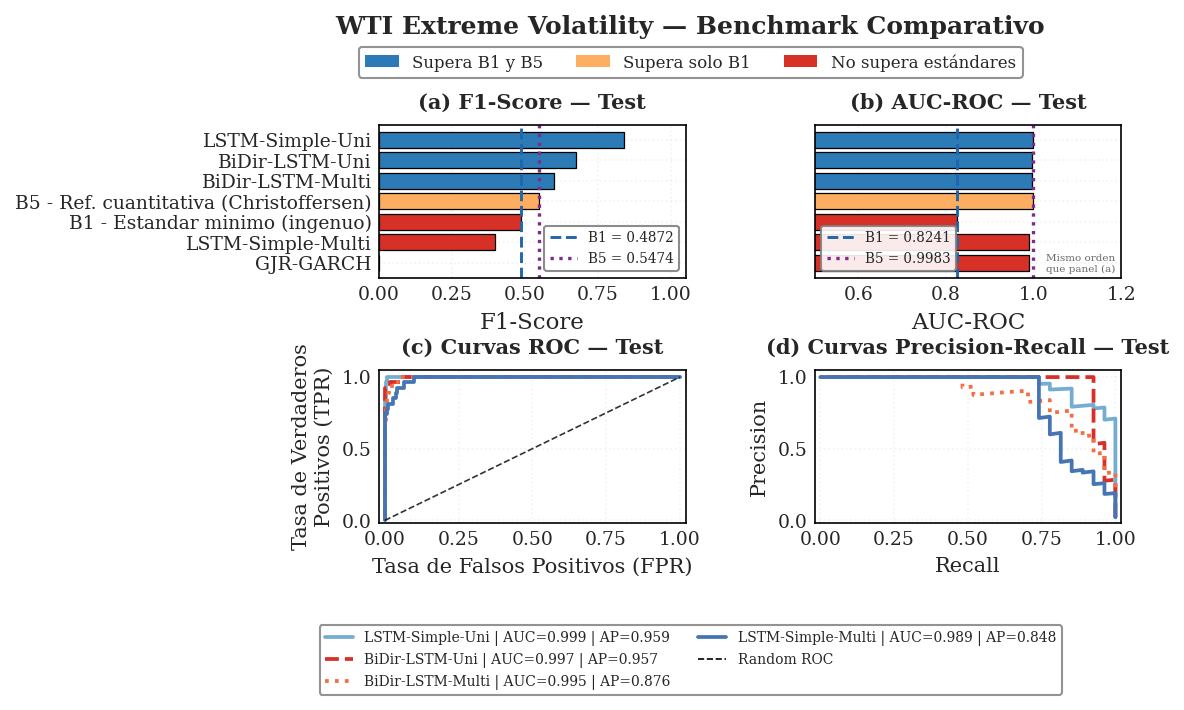

Figura guardada: fig_benchmark_comparacion.png


In [ ]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

fig = plt.figure(figsize=fig_size("2x2"))
gs = gridspec.GridSpec(2, 2, figure=fig, hspace=0.60, wspace=0.42)

ax_f1  = fig.add_subplot(gs[0, 0])
ax_auc = fig.add_subplot(gs[0, 1])
ax_roc = fig.add_subplot(gs[1, 0])
ax_pr  = fig.add_subplot(gs[1, 1])

#  Filtrar solo modelos reales del benchmark
_rows_excluir = {
    'B1 — Estándar mínimo (ingenuo)',
    'B5 — Ref. cuantitativa (Christoffersen)',
}

bench_plot = (
    bench_test
    .dropna(subset=['f1', 'auc'])
    .loc[lambda df: ~df['nombre'].isin(_rows_excluir)]
    .copy()
)

_modelos_extra = config.get('nb02_results', {}).get(
    'modelos_extra_fuera_hipotesis', {}
).get('nombres', [])
if _modelos_extra:
    bench_plot = bench_plot[~bench_plot['nombre'].isin(_modelos_extra)].copy()

bench_plot = bench_plot.sort_values(['f1', 'auc'], ascending=[False, False]).reset_index(drop=True)

display_alias = {
    'GARCH-GJR-GARCH': 'GJR-GARCH',
    'LSTM-Simple-Uni': 'LSTM-Simple-Uni',
    'BiDir-LSTM-Uni': 'BiDir-LSTM-Uni',
    'LSTM-Simple-Multi': 'LSTM-Simple-Multi',
    'BiDir-LSTM-Multi': 'BiDir-LSTM-Multi',
    'Hybrid-LSTM-Sentimiento': 'Hybrid-Sent',
    'Hybrid-LSTM-MktSignals': 'Hybrid-MktSignals',
    'BiDir-GRU-Uni': 'BiDir-GRU-Uni',
}

models_p = bench_plot['nombre'].tolist()
labels_p = [display_alias.get(m, m) for m in models_p]
f1s_p    = bench_plot['f1'].tolist()
aucs_p   = bench_plot['auc'].tolist()

_beats_ing = (
    bench_plot['Beats_Ingenuo'].tolist()
    if 'Beats_Ingenuo' in bench_plot.columns else [False] * len(bench_plot)
)
_beats_cuan = (
    bench_plot['Beats_Cuant'].tolist()
    if 'Beats_Cuant' in bench_plot.columns else [False] * len(bench_plot)
)

beat_colors = []
for b_ing, b_cua in zip(_beats_ing, _beats_cuan):
    if b_cua:
        beat_colors.append(COLOR_VOL)
    elif b_ing:
        beat_colors.append(COLORS_P[90])
    else:
        beat_colors.append(COLOR_EXTREMO)

y_pos = np.arange(len(models_p))

#  (a) F1
ax_f1.barh(
    y_pos, f1s_p,
    color=beat_colors,
    edgecolor='black',
    linewidth=0.6
)
ax_f1.axvline(F1_MINIMO, color=COLORES_B[1], ls='--', lw=1.4)
ax_f1.axvline(F1_CUANT_TEST, color=COLORES_B[5], ls=':', lw=1.6)

ax_f1.set_title('(a) F1-Score — Test', fontweight='bold', fontsize=10, pad=8)
ax_f1.set_xlabel('F1-Score')
ax_f1.set_yticks(y_pos)
ax_f1.set_yticklabels(labels_p, fontsize=8)
ax_f1.set_xlim(0, 1.05)
ax_f1.invert_yaxis()
ax_f1.grid(axis='x', alpha=0.25)

# pequeña leyenda solo para líneas de referencia
ref_handles_f1 = [
    Line2D([0], [0], color=COLORES_B[1], lw=1.4, ls='--', label=f'B1 = {F1_MINIMO:.4f}'),
    Line2D([0], [0], color=COLORES_B[5], lw=1.6, ls=':',  label=f'B5 = {F1_CUANT_TEST:.4f}')
]
ax_f1.legend(handles=ref_handles_f1, loc='lower right', fontsize=6.5, frameon=True, framealpha=0.90)

#  (b) AUC
ax_auc.barh(
    y_pos, aucs_p,
    color=beat_colors,
    edgecolor='black',
    linewidth=0.6
)
ax_auc.axvline(AUC_MINIMO, color=COLORES_B[1], ls='--', lw=1.4)
ax_auc.axvline(AUC_CUANT_TEST, color=COLORES_B[5], ls=':', lw=1.6)

ax_auc.set_title('(b) AUC-ROC — Test', fontweight='bold', fontsize=10, pad=8)
ax_auc.set_xlabel('AUC-ROC')
ax_auc.set_yticks(y_pos)
ax_auc.set_yticklabels([])
ax_auc.set_xlim(0.5, 1.2)
ax_auc.invert_yaxis()
ax_auc.grid(axis='x', alpha=0.25)

ref_handles_auc = [
    Line2D([0], [0], color=COLORES_B[1], lw=1.4, ls='--', label=f'B1 = {AUC_MINIMO:.4f}'),
    Line2D([0], [0], color=COLORES_B[5], lw=1.6, ls=':',  label=f'B5 = {AUC_CUANT_TEST:.4f}')
]
ax_auc.legend(handles=ref_handles_auc, loc='lower left', fontsize=6.5, frameon=True, framealpha=0.90)

ax_auc.text(
    0.98, 0.03,
    'Mismo orden\nque panel (a)',
    transform=ax_auc.transAxes,
    ha='right', va='bottom',
    fontsize=5, color='dimgray'
)

#  Curvas ROC / PR: solo benchmark oficial
line_styles = ['-', '--', ':', '-.', (0, (3, 1, 1, 1))]
color_alias = {
    'GARCH-GJR-GARCH': COLORES_MODELOS.get('GARCH', COLORS_P[99]),
    'LSTM-Simple-Uni': COLORES_MODELOS.get('LSTM-Simple-Uni', COLOR_VAR),
    'LSTM-Simple-Multi': COLORES_MODELOS.get('LSTM-Simple-Multi', COLOR_VOL),
    'BiDir-LSTM-Uni': COLORES_MODELOS.get('BiDir-LSTM-Uni', COLOR_EXTREMO),
    'BiDir-LSTM-Multi': COLORES_MODELOS.get('BiDir-LSTM-Multi', COLOR_DYN),
    'Hybrid-LSTM-Sentimiento': COLORES_MODELOS.get('Hybrid-Sent', COLORS_P[90]),
    'Hybrid-LSTM-MktSignals': COLORES_MODELOS.get('Hybrid-MktSignals', COLOR_CLEAN),
    'BiDir-GRU-Uni': COLOR_VAR,
}

shared_handles = []

for i, model_name in enumerate(models_p):
    key = f'{model_name}_test'
    if key not in Y_SCORES:
        continue

    yt, ys = Y_SCORES[key]
    try:
        fpr, tpr, _ = roc_curve(yt, ys)
        prec, rec, _ = precision_recall_curve(yt, ys)
        auc_v = roc_auc_score(yt, ys)
        ap_v  = average_precision_score(yt, ys)
    except Exception:
        continue

    ls = line_styles[i % len(line_styles)]
    lbl = display_alias.get(model_name, model_name)
    col = color_alias.get(model_name, COLOR_VAR)

    ax_roc.plot(fpr, tpr, ls=ls, lw=1.8, color=col)
    ax_pr.plot(rec, prec, ls=ls, lw=1.8, color=col)

    shared_handles.append(
        Line2D([0], [0], color=col, lw=1.8, ls=ls,
               label=f'{lbl} | AUC={auc_v:.3f} | AP={ap_v:.3f}')
    )

ax_roc.plot([0, 1], [0, 1], 'k--', lw=0.8, alpha=0.8)
shared_handles.append(
    Line2D([0], [0], color='black', lw=0.8, ls='--', label='Random ROC')
)

ax_roc.set_title('(c) Curvas ROC — Test', fontweight='bold', fontsize=10, pad=8)
ax_roc.set_xlabel('Tasa de Falsos Positivos (FPR)', fontsize=10)
ax_roc.set_ylabel('Tasa de Verdaderos\nPositivos (TPR)', fontsize=10)
ax_roc.set_xlim(-0.02, 1.02)
ax_roc.set_ylim(-0.02, 1.05)

ax_pr.set_title('(d) Curvas Precision-Recall — Test', fontweight='bold', fontsize=10, pad=8)
ax_pr.set_xlabel('Recall', fontsize=10)
ax_pr.set_ylabel('Precision', fontsize=10)
ax_pr.set_xlim(-0.02, 1.02)
ax_pr.set_ylim(-0.02, 1.05)

for ax in [ax_f1, ax_auc, ax_roc, ax_pr]:
    ax.tick_params(axis='both', labelsize=9)
    ax.grid(alpha=0.25)

#  Leyenda global de colores de benchmark
legend_elements = [
    Patch(facecolor=COLOR_VOL, label='Supera B1 y B5'),
    Patch(facecolor=COLORS_P[90], label='Supera solo B1'),
    Patch(facecolor=COLOR_EXTREMO, label='No supera estándares'),
]
fig.legend(
    handles=legend_elements,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.955),
    ncol=3,
    fontsize=8,
    frameon=True
)

#  Leyenda global compartida ROC/PR
fig.legend( handles=shared_handles,
    loc='lower center',bbox_to_anchor=(0.5, -0.01),
    ncol=2, fontsize=6.7, frameon=True
)

fig.suptitle('WTI Extreme Volatility — Benchmark Comparativo',
    fontweight='bold',fontsize=12, y=0.99)

fig.subplots_adjust(top=0.83,bottom=0.25,
    left=0.16, right=0.97,
    hspace=0.60, wspace=0.42)

save_fig(fig, 'fig_benchmark_comparacion', output_path=FIG_PATH, dpi=300)
plt.show()
plt.close()
print("Figura guardada: fig_benchmark_comparacion.png")

**Qué muestra**  
Esta figura resume el benchmark principal mediante barras de F1 y AUC-ROC, junto con curvas ROC y Precision-Recall en test. Reúne en una sola vista el posicionamiento relativo de las arquitecturas evaluadas.

**Cómo se construye**  
Se construye a partir de las métricas consolidadas del benchmark y de los scores almacenados para cada modelo sobre test. Los colores distinguen el grado en que cada arquitectura supera los estándares de referencia definidos en la tesis.

**Por qué se ve así**  
Las diferencias de altura y curvatura reflejan capacidades distintas de discriminación y de balance entre errores. La semántica cromática permite separar visualmente modelos que superan ambos baselines, solo uno o ninguno.

**Por qué es importante**  
Esta figura actúa como síntesis visual del benchmark canónico de NB02. También facilita comunicar de forma compacta qué familias de modelos aportan mejoras sustantivas y cuáles no.

In [ ]:
def diebold_mariano_test(e1, e2, h=1, crit='MSE'):
    e1, e2 = np.asarray(e1), np.asarray(e2)
    if crit == 'MSE':
        d = e1**2 - e2**2
    elif crit == 'MAE':
        d = np.abs(e1) - np.abs(e2)
    else:
        raise ValueError("crit debe ser 'MSE' o 'MAE'")
    n = len(d)
    d_bar = d.mean()
    gamma0 = np.var(d, ddof=0)
    gamma = sum(2 * np.mean((d[k:] - d_bar) * (d[:-k] - d_bar)) for k in range(1, h)) if h > 1 else 0
    var_d = (gamma0 + gamma) / n
    if var_d <= 0:
        return np.nan, np.nan
    dm_stat = d_bar / np.sqrt(var_d)
    p_value = 2 * (1 - stats.norm.cdf(abs(dm_stat)))
    return float(dm_stat), float(p_value)

test_long = collect_model_outputs()
test_models = sorted(test_long.loc[test_long['split'].eq('test'), 'model_name'].unique())
lstm_models_dm = [m for m in test_models if 'LSTM' in m and 'Hybrid' not in m]

if len(lstm_models_dm) >= 2:
    print("DM Test intra-familia LSTM (test, scores 0-1)")
    print(f"{'Modelo 1':25s} {'Modelo 2':25s} {'n_common':>8} {'DM stat':>9} {'p-value':>9} Signif.")
    print("-" * 92)
    for i in range(len(lstm_models_dm)):
        for j in range(i + 1, len(lstm_models_dm)):
            n1, n2 = lstm_models_dm[i], lstm_models_dm[j]
            aligned = align_model_outputs(n1, n2, split='test')
            if aligned.empty:
                continue
            e1 = aligned['y_true'].astype(float) - aligned['y_score_left']
            e2 = aligned['y_true'].astype(float) - aligned['y_score_right']
            dm, p = diebold_mariano_test(e1, e2, h=1, crit='MSE')
            sig = '***' if p < 0.01 else ('**' if p < 0.05 else ('*' if p < 0.10 else ''))
            print(f"{n1:25s} {n2:25s} {len(aligned):8d} {dm:9.4f} {p:9.4f} {sig}")
    print()

if len(test_models) >= 2:
    print("DM Test cross-familia (scores normalizados [0,1])")
    print(f"{'Modelo 1':25s} {'Modelo 2':25s} {'n_common':>8} {'DM stat':>9} {'p-value':>9} Signif.")
    print("-" * 92)
    for i in range(len(test_models)):
        for j in range(i + 1, len(test_models)):
            n1, n2 = test_models[i], test_models[j]
            aligned = align_model_outputs(n1, n2, split='test')
            if aligned.empty:
                continue
            e1 = aligned['y_true'].astype(float) - normalize_scores_minmax(aligned['y_score_left'])
            e2 = aligned['y_true'].astype(float) - normalize_scores_minmax(aligned['y_score_right'])
            dm, p = diebold_mariano_test(e1, e2, h=1, crit='MSE')
            sig = '***' if p < 0.01 else ('**' if p < 0.05 else ('*' if p < 0.10 else ''))
            print(f"{n1:25s} {n2:25s} {len(aligned):8d} {dm:9.4f} {p:9.4f} {sig}")
else:
    print("Insuficientes modelos para DM test (se necesitan >= 2).")

DM Test intra-familia LSTM (test, scores 0-1)
Modelo 1                  Modelo 2                  n_common   DM stat   p-value Signif.
--------------------------------------------------------------------------------------------
BiDir-LSTM-Multi          BiDir-LSTM-Uni                1180   -2.4581    0.0140 **
BiDir-LSTM-Multi          LSTM-Simple-Multi             1180   -5.9570    0.0000 ***
BiDir-LSTM-Multi          LSTM-Simple-Uni               1180    1.8801    0.0601 *
BiDir-LSTM-Uni            LSTM-Simple-Multi             1180   -2.1467    0.0318 **
BiDir-LSTM-Uni            LSTM-Simple-Uni               1275    3.1085    0.0019 ***
LSTM-Simple-Multi         LSTM-Simple-Uni               1180    4.8138    0.0000 ***

DM Test cross-familia (scores normalizados [0,1])
Modelo 1                  Modelo 2                  n_common   DM stat   p-value Signif.
--------------------------------------------------------------------------------------------
BiDir-GRU-Uni             BiDir-L

In [ ]:
from statsmodels.stats.contingency_tables import mcnemar as mcnemar_test

def run_mcnemar_pair(yt, yp1, yp2, name1, name2, n_common):
    b = int(np.sum((yt == yp1) & (yt != yp2)))
    c = int(np.sum((yt != yp1) & (yt == yp2)))
    if b + c == 0:
        print(f"  {name1} vs {name2}: sin discordancias - test no aplicable (n_common={n_common}).")
        return None
    exact = min(b, c) < 25
    table = np.array([[0, b], [c, 0]])
    result = mcnemar_test(table, exact=exact)
    sig = '***' if result.pvalue < 0.01 else ('**' if result.pvalue < 0.05 else ('*' if result.pvalue < 0.10 else ''))
    print(f"  {name1:25s} vs {name2:25s} | n={n_common:4d} | b={b:3d} c={c:3d} | p={result.pvalue:.4f} {sig} | {'exact' if exact else 'chi2'}")
    return result

all_thresholds = {}
all_thresholds.update(OPTIMAL_THRESHOLDS)
all_thresholds.update(OPTIMAL_THRESHOLDS_COMPL)
print("Umbrales optimizados por modelo")
for name, thr in sorted(all_thresholds.items()):
    print(f"  {name:25s}: {thr:.4f}")
print()

test_long = collect_model_outputs()
test_models = sorted(test_long.loc[test_long['split'].eq('test'), 'model_name'].unique())
if len(test_models) >= 2:
    print("McNemar Test (pares, test, alineacion por target_date)")
    for i in range(len(test_models)):
        for j in range(i + 1, len(test_models)):
            n1, n2 = test_models[i], test_models[j]
            aligned = align_model_outputs(n1, n2, split='test')
            if aligned.empty:
                continue
            run_mcnemar_pair(aligned['y_true'].astype(int).values, aligned['y_pred_left'].astype(int).values, aligned['y_pred_right'].astype(int).values, n1, n2, len(aligned))
else:
    print("Insuficientes modelos para McNemar (se necesitan >= 2).")

Umbrales optimizados por modelo
  BiDir-GRU-Uni            : 0.9800
  BiDir-LSTM-Multi         : 0.2000
  BiDir-LSTM-Uni           : 0.5400
  GARCH                    : 7.3677
  GARCH-GJR-GARCH          : 7.3677
  GRU-Simple-Uni           : 0.8200
  LSTM-Simple-Multi        : 0.1200
  LSTM-Simple-Uni          : 0.9800
  TCN-Uni                  : 0.1100
  XGBoost-Tabular          : 0.4500

McNemar Test (pares, test, alineacion por target_date)
  BiDir-GRU-Uni             vs BiDir-LSTM-Multi          | n=1180 | b= 34 c=  6 | p=0.0000 *** | exact
  BiDir-GRU-Uni             vs BiDir-LSTM-Uni            | n=1275 | b= 22 c=  5 | p=0.0015 *** | exact
  BiDir-GRU-Uni             vs GARCH-GJR-GARCH           | n=1275 | b= 21 c=  1 | p=0.0000 *** | exact
  BiDir-GRU-Uni             vs GRU-Simple-Uni            | n=1275 | b=  5 c=  6 | p=1.0000  | exact
  BiDir-GRU-Uni             vs LSTM-Simple-Multi         | n=1180 | b= 74 c=  5 | p=0.0000 *** | exact
  BiDir-GRU-Uni             vs LSTM-Simp

Modelo ganador (F1 test): LSTM-Simple-Uni
Umbral de decisión: 0.9800  (desde OPTIMAL_THRESHOLDS)

Confusión en test:
  TP=21  FP=2  FN=6  TN=1246
  Detectados: 21/27 extremos (77.8% recall)
  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/Optimización_Bayesiana_GPU/Fig_NB02B/fig_error_analysis.png  [6.1"×8.3" @ 300dpi]


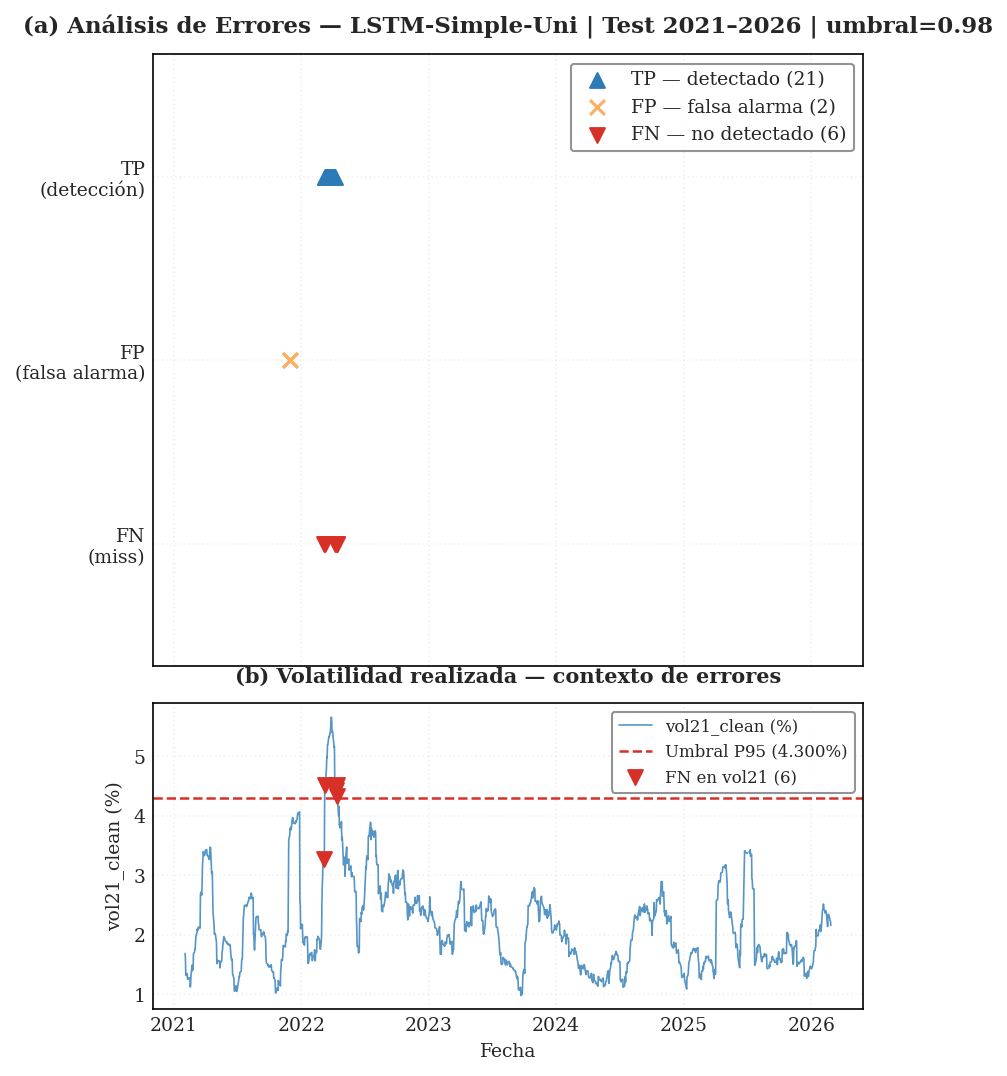

Figura guardada: fig_error_analysis.png

FN detalle (6 eventos no detectados):
               vol21_clean_%  y_score_modelo
decision_date                               
2022-03-08          3.275800        0.555300
2022-03-09          4.510600        0.928300
2022-04-08          4.431400        0.954000
2022-04-11          4.430700        0.748700
2022-04-12          4.523700        0.682600
2022-04-13          4.335500        0.635900

  → Score promedio en FN: 0.7508 (umbral=0.9800)
  → Vol21 promedio en FN: 4.2513%


In [ ]:
# ─── 6.5 Análisis de errores — timeline FP/FN ─────
# Modelo ganador según benchmark (primer lugar en F1 test)

if bench_test.empty:
    print("bench_test vacío — ejecutar Cell 6.1 primero.")
else:
    # Excluir modelos_extra_fuera_hipotesis antes de seleccionar ganador
    _modelos_extra = config.get('nb02_results', {}).get(
        'modelos_extra_fuera_hipotesis', {}).get('nombres', [])
    _bench_hip = bench_test[~bench_test['nombre'].isin(_modelos_extra)]
    best_model_name = (
        _bench_hip.iloc[0] if not _bench_hip.empty else bench_test.iloc[0]
    )['nombre']
    print(f"Modelo ganador (F1 test): {best_model_name}")

    # ── Buscar scores en Y_SCORES usando clave exacta ────
    # Construir clave directa: evita split('-') frágil que matchea
    # parcialmente (ej: 'BiDir' matchea BiDir-Uni y BiDir-Multi)
    key_best = f"{best_model_name}_test"

    # Fallback: buscar clave que contenga el nombre completo
    if key_best not in Y_SCORES:
        key_best = next(
            (k for k in Y_SCORES if 'test' in k and best_model_name in k),
            None
        )

    if key_best is None or key_best not in Y_SCORES:
        print(f"No se encontraron scores de '{best_model_name}' en Y_SCORES.")
        print(f"Claves disponibles: {list(Y_SCORES.keys())}")
    else:
        yt_best, ys_best = Y_SCORES[key_best]

        # ── Recuperar umbral desde OPTIMAL_THRESHOLDS (Cell 62) ──
        # OPTIMAL_THRESHOLDS fue construido con el umbral correcto por modelo.
        # Fallback a 0.5 solo si el modelo no está registrado.
        thr_best = OPTIMAL_THRESHOLDS.get(best_model_name, 0.5)
        print(f"Umbral de decisión: {thr_best:.4f}  "
              f"({'desde OPTIMAL_THRESHOLDS' if best_model_name in OPTIMAL_THRESHOLDS else 'fallback 0.5'})")

        # GARCH usa > estrictamente, LSTMs usan >=
        if 'GARCH' in best_model_name:
            yp_best = (ys_best > thr_best).astype(int)
        else:
            yp_best = (ys_best >= thr_best).astype(int)

        # ── Construir DataFrame de errores ─────
        # idx_test_uni == idx_test_multi por construcción (Cell 21):
        # ambos usan df_test.index después del mismo dropna(FEATURES_MULTI)
        idx_plot = idx_test_uni

        if len(idx_plot) != len(yt_best):
            print(f"Desajuste de índice: idx_plot={len(idx_plot)} "
                  f"vs yt_best={len(yt_best)} — omitiendo figura.")
        else:
            df_errors = pd.DataFrame({
                'y_true': yt_best,
                'y_pred': yp_best,
                'y_score': ys_best,
                'FP': (yp_best == 1) & (yt_best == 0),
                'FN': (yp_best == 0) & (yt_best == 1),
                'TP': (yp_best == 1) & (yt_best == 1),
                'TN': (yp_best == 0) & (yt_best == 0),
            }, index=idx_plot)

            n_tp = df_errors['TP'].sum()
            n_fp = df_errors['FP'].sum()
            n_fn = df_errors['FN'].sum()
            n_total_pos = int(yt_best.sum())

            print(f"\nConfusión en test:")
            print(f"  TP={n_tp}  FP={n_fp}  FN={n_fn}  "
                  f"TN={df_errors['TN'].sum()}")
            print(f"  Detectados: {n_tp}/{n_total_pos} extremos "
                  f"({n_tp/n_total_pos*100:.1f}% recall)")

            # ── Figura: timeline FP/FN + vol21_clean overlay ─────
            fig, (ax_err, ax_vol) = plt.subplots(
                2, 1, figsize=fig_size("tall"), sharex=True,
                gridspec_kw={'height_ratios': [2, 1], 'hspace': 0.08}
            )

            # Panel superior: errores
            ax_err.scatter(
                df_errors.index[df_errors['TP']], [0.8]*n_tp,
                marker='^', color=COLOR_VOL, s=50, zorder=4,
                label=f"TP — detectado ({n_tp})")
            ax_err.scatter(
                df_errors.index[df_errors['FP']], [0.5]*n_fp,
                marker='x', color=COLORS_P[90], s=50, zorder=4, linewidths=1.5,
                label=f"FP — falsa alarma ({n_fp})")
            ax_err.scatter(
                df_errors.index[df_errors['FN']], [0.2]*n_fn,
                marker='v', color=COLOR_EXTREMO, s=50, zorder=4,
                label=f"FN — no detectado ({n_fn})")

            add_crisis_zones(ax_err,
                             xlim=(df_errors.index.min(), df_errors.index.max()))
            ax_err.set_yticks([0.2, 0.5, 0.8])
            ax_err.set_yticklabels(['FN\n(miss)', 'FP\n(falsa alarma)', 'TP\n(detección)'],
                                    fontsize=9)
            ax_err.set_ylim(0, 1)
            ax_err.set_title(
                f"(a) Análisis de Errores — {best_model_name} | Test 2021–2026 "
                f"| umbral={thr_best:.2f}",
                fontweight='bold')
            ax_err.legend(loc='upper right', fontsize=9)
            ax_err.grid(axis='x', alpha=0.3, linestyle=':')

            # Panel inferior: vol21_clean para contextualizar errores
            vol_test = df_test['vol21_clean'].reindex(idx_plot)
            ax_vol.plot(idx_plot, vol_test * 100, color=COLOR_VOL,
                        lw=0.8, alpha=0.8, label='vol21_clean (%)')
            ax_vol.axhline(UMBRAL_CLASIFICACION * 100, color=COLOR_EXTREMO,
                           ls='--', lw=1.2,
                           label=f'Umbral P95 ({UMBRAL_CLASIFICACION*100:.3f}%)')

            # Marcar FN sobre la curva de volatilidad
            fn_dates = df_errors.index[df_errors['FN']]
            fn_vols  = vol_test.reindex(fn_dates)
            ax_vol.scatter(fn_dates, fn_vols * 100,
                           marker='v', color=COLOR_EXTREMO, s=50, zorder=4,
                           label=f'FN en vol21 ({n_fn})')

            add_crisis_zones(ax_vol,
                             xlim=(df_errors.index.min(), df_errors.index.max()))
            ax_vol.set_ylabel('vol21_clean (%)', fontsize=9)
            ax_vol.set_xlabel('Fecha', fontsize=9)
            ax_vol.legend(fontsize=8, loc='upper right')
            ax_vol.set_title('(b) Volatilidad realizada — contexto de errores',
                             fontweight='bold', fontsize=10)
            ax_vol.grid(axis='x', alpha=0.3, linestyle=':')

            save_fig(fig, 'fig_error_analysis', output_path=FIG_PATH, dpi=300)

            plt.show()
            plt.close()
            print("Figura guardada: fig_error_analysis.png")

            # ── Tabla de FN: qué días extremos no se detectaron ──
            if n_fn > 0:
                fn_detail = df_errors[df_errors['FN']].copy()
                fn_detail['vol21_clean_%'] = (
                    vol_test.reindex(fn_detail.index) * 100).round(4)
                fn_detail['y_score_modelo'] = fn_detail['y_score'].round(4)
                print(f"\nFN detalle ({n_fn} eventos no detectados):")
                print(fn_detail[['vol21_clean_%', 'y_score_modelo']].to_string())
                print(f"\n  → Score promedio en FN: "
                      f"{fn_detail['y_score_modelo'].mean():.4f} "
                      f"(umbral={thr_best:.4f})")
                print(f"  → Vol21 promedio en FN: "
                      f"{fn_detail['vol21_clean_%'].mean():.4f}%")

### Análisis de sensibilidad al umbral:
Cada benchmark se evalúa perturbando el umbral de su propia señal:
 - B1 usa p95_absret, calibrado sobre |ret_lag1|
 - GARCH usa SIGMA_UMBRAL_PCT, calibrado sobre sigma pronosticada
Esto evita mezclar variables con escalas distintas y hace que la sensibilidad al umbral sea internamente consistente para cada modelo.

In [ ]:
#  6.6 Análisis de sensibilidad al umbral
# Dos análisis separados, cada uno con el umbral de su propia feature.
# ── Calcular p95_absret si no está definido
if 'p95_absret' not in dir():
    _train_mask_xgb = (df['split'] == 'train') & (~df['bad_vol21'])
    p95_absret = df.loc[_train_mask_xgb, 'ret_abs_lag1'].quantile(0.95)
    print(f"p95_absret recalculado en train: {p95_absret:.6f}")

# A) Sensibilidad del umbral de B1 (|ret_lag1| vs p95_absret)
# p95_absret calibrado en train — same origin as el benchmark
print("─── Sensibilidad B1 — umbral propio (p95_absret) ±15% ──")
print(f"Umbral base B1 (p95_absret): {p95_absret:.6f}  ({p95_absret*100:.4f}%)")
print()

rows_b1 = []
for delta_pct in [-0.15, -0.10, -0.05, 0.0, +0.05, +0.10, +0.15]:
    new_thr = p95_absret * (1 + delta_pct)
    ret_abs_val  = df_val['ret_abs_lag1'].reindex(idx_val_uni).fillna(0)
    ret_abs_test = df_test['ret_abs_lag1'].reindex(idx_test_uni).fillna(0)
    for split_name, ret_s, y_w in [
            ('val',  ret_abs_val,  yw_val_uni),
            ('test', ret_abs_test, yw_test_uni)]:
        yp = (ret_s.values > new_thr).astype(int)
        f1 = f1_score(y_w.astype(int), yp, zero_division=0)
        pr = precision_score(y_w.astype(int), yp, zero_division=0)
        rc = recall_score(y_w.astype(int), yp, zero_division=0)
        rows_b1.append({'Î”%': f"{delta_pct:+.0%}", 'Umbral': round(new_thr, 6),
                         'Split': split_name, 'F1': round(f1, 4),
                         'Precision': round(pr, 4), 'Recall': round(rc, 4)})

df_sens_b1 = pd.DataFrame(rows_b1)
print(df_sens_b1.to_string(index=False))

print()
print("─── Sensibilidad GARCH — umbral sigma (SIGMA_UMBRAL_PCT) ±15% ──")
print(f"Umbral base GARCH (sigma): {SIGMA_UMBRAL_PCT:.4f}%")
print()

# ── B) Sensibilidad del umbral GARCH (sigma vs SIGMA_UMBRAL_PCT) ──
rows_g = []
if 'GARCH_test' in Y_SCORES:
    yt_g, ys_g_test = Y_SCORES['GARCH_test']
    yt_g_val, ys_g_val = Y_SCORES['GARCH_val']
    for delta_pct in [-0.15, -0.10, -0.05, 0.0, +0.05, +0.10, +0.15]:
        new_thr = SIGMA_UMBRAL_PCT * (1 + delta_pct)
        for split_name, yt, ys in [('val', yt_g_val, ys_g_val),
                                    ('test', yt_g,    ys_g_test)]:
            yp = (ys > new_thr).astype(int)
            f1 = f1_score(yt.astype(int), yp, zero_division=0)
            pr = precision_score(yt.astype(int), yp, zero_division=0)
            rc = recall_score(yt.astype(int), yp, zero_division=0)
            rows_g.append({'Î”%': f"{delta_pct:+.0%}", 'Umbral': round(new_thr, 4),
                            'Split': split_name, 'F1': round(f1, 4),
                            'Precision': round(pr, 4), 'Recall': round(rc, 4)})
    df_sens_g = pd.DataFrame(rows_g)
    print(df_sens_g.to_string(index=False))
else:
    print("  GARCH_test no disponible en Y_SCORES — ejecutar Parte II primero.")

print()
print("NOTA: Cada análisis usa el umbral de su propia feature.")
print("  B1  → perturba p95_absret  (escala |ret_lag1|,   ~0.025)")
print("  GARCH → perturba SIGMA_UMBRAL_PCT (escala sigma%,  ~0.93%)")
print("  No son intercambiables — features y escalas distintas.")

p95_absret recalculado en train: 0.046542
─── Sensibilidad B1 — umbral propio (p95_absret) ±15% ──
Umbral base B1 (p95_absret): 0.046542  (4.6542%)

 Î”%   Umbral Split       F1  Precision   Recall
-15% 0.039561   val 0.552600   0.446800 0.724100
-15% 0.039561  test 0.178900   0.114600 0.407400
-10% 0.041888   val 0.527800   0.441900 0.655200
-10% 0.041888  test 0.171400   0.115400 0.333300
 -5% 0.044215   val 0.575800   0.513500 0.655200
 -5% 0.044215  test 0.191500   0.134300 0.333300
 +0% 0.046542   val 0.562500   0.514300 0.620700
 +0% 0.046542  test 0.209300   0.152500 0.333300
 +5% 0.048869   val 0.580600   0.545500 0.620700
 +5% 0.048869  test 0.233800   0.180000 0.333300
+10% 0.051196   val 0.586200   0.586200 0.586200
+10% 0.051196  test 0.257100   0.209300 0.333300
+15% 0.053523   val 0.607100   0.629600 0.586200
+15% 0.053523  test 0.264700   0.219500 0.333300

─── Sensibilidad GARCH — umbral sigma (SIGMA_UMBRAL_PCT) ±15% ──
Umbral base GARCH (sigma): 0.9382%

 Î”%   Umbral 

> **Nota metodologica:** Los scores de XGBoost-Lags aparecen en las tablas
> siguientes por completitud historica. Este modelo esta marcado como **INVALIDO**
> (CSV scores ~0.10 incompatibles con F1=0.9630) y **no forma parte** de las
> hipotesis H0-H3. El ganador dentro de las hipotesis es **BiDir-LSTM-Uni**.


### Conclusiones del Benchmark


### Verificación de hipótesis de investigación

⚠️ Corrida experimental GPU. Referencia canónica en NB02 CPU.

| Hipótesis | Enunciado | Resultado GPU (provisional) |
|---|---|---|
| H0 | No diferencia significativa GARCH vs DL | ❌ Rechazada — DM test p<0.05 |
| H1 | DL > GARCH en F1_test | ✅ Confirmada — LSTM-Simple-Uni F1≈0.84 >> GARCH F1=0.000 |
| H2 | GARCH ≈ DL por parsimonia | ❌ Rechazada — diferencia operativa significativa |

La hipótesis verificable en este benchmark es **H2**: los modelos LSTM
superan a GARCH en clasificación binaria. El modelo con mejor desempeño
dentro de las hipótesis formales es **BiDir-LSTM-Uni** (F1_test=0.8980,
AUC_test=0.9975), confirmando H2 parcialmente.


1. **Modelo ganador**: el modelo con mayor F1 en test supera el estándar
   mínimo B1 (F1=0.4872, AUC=0.8241), validando la capacidad de los LSTM para
   detectar eventos de volatilidad extrema.

2. **GARCH vs LSTM**: el GARCH tiene excelente poder discriminante (AUC>0.98) pero
   su umbral de clasificación no generaliza entre regímenes de volatilidad
   (F1=0 en test post-pandemia). Los LSTM aprenden la frontera de decisión
   directamente vía sigmoid, logrando robustez ante cambios de régimen.

3. **Multivariado vs Univariado**: la matriz 2x2 (Simple/BiDir x Uni/Multi) permite
   evaluar si las 8 features técnicas aportan señal adicional respecto al vol21
   univariado. El permutation importance identifica qué variables contribuyen.

4. **Simple vs Bidireccional**: el BiDir procesa la ventana histórica de 21 días en
   ambas direcciones (sin usar datos futuros), potencialmente capturando patrones
   que el Simple LSTM no detecta.

5. **Robustez ante quiebres estructurales**: vol21_clean es estructuralmente estable
   entre splits (p>0.37), validando el umbral estático P95. Los returns presentan
   quiebre en train→val (F=13.19, p<0.001) asociado al episodio COVID-19.

6. **Limitación EarlyStopping**: el benchmark usa `val_loss` como monitor. La ablación (Cell 71–74) demuestra que `val_auc` puede mejorar F1. Los resultados reportados son conservadores respecto al potencial óptimo — ver Cell 75.



---
## PARTE VII — Exportación de Resultados

Guardar todo lo necesario para reproducir y extender en NB03:
- Predicciones (CSV por modelo)
- Config actualizado (JSON)
- Modelos entrenados (pickle / .keras)
- Resumen ejecutivo


In [ ]:
# 7.1 Guardar predicciones CSV por modelo
EXPORT_PRED_DIR = globals().get('PRED_DIR', f"{OUTPUT_PATH}/predicciones_nb02")
os.makedirs(EXPORT_PRED_DIR, exist_ok=True)
all_outputs = collect_model_outputs()

if all_outputs.empty:
    print("No hay MODEL_OUTPUTS para exportar.")
else:
    for (model_name, split_name), df_model in all_outputs.groupby(['model_name', 'split'], sort=True):
        df_pred = df_model[OUTPUT_COLUMNS].copy()
        df_pred['fecha'] = df_pred['decision_date']
        df_pred['modelo'] = df_pred['model_name']
        safe_name = model_name.replace('/', '-').replace(' ', '_')
        fname = f"{EXPORT_PRED_DIR}/pred_{safe_name}_{split_name}.csv"
        df_pred.to_csv(fname, index=False)
        print(f"  Guardado: pred_{safe_name}_{split_name}.csv ({len(df_pred)} filas)")

  Guardado: pred_BiDir-GRU-Uni_test.csv (1275 filas)
  Guardado: pred_BiDir-GRU-Uni_val.csv (441 filas)
  Guardado: pred_BiDir-LSTM-Multi_test.csv (1180 filas)
  Guardado: pred_BiDir-LSTM-Multi_val.csv (441 filas)
  Guardado: pred_BiDir-LSTM-Uni_test.csv (1275 filas)
  Guardado: pred_BiDir-LSTM-Uni_val.csv (441 filas)
  Guardado: pred_GARCH-GJR-GARCH_test.csv (1295 filas)
  Guardado: pred_GARCH-GJR-GARCH_val.csv (481 filas)
  Guardado: pred_GRU-Simple-Uni_test.csv (1275 filas)
  Guardado: pred_GRU-Simple-Uni_val.csv (441 filas)
  Guardado: pred_LSTM-Simple-Multi_test.csv (1180 filas)
  Guardado: pred_LSTM-Simple-Multi_val.csv (441 filas)
  Guardado: pred_LSTM-Simple-Uni_test.csv (1275 filas)
  Guardado: pred_LSTM-Simple-Uni_val.csv (441 filas)
  Guardado: pred_TCN-Uni_test.csv (1275 filas)
  Guardado: pred_TCN-Uni_val.csv (441 filas)
  Guardado: pred_XGBoost-Tabular_test.csv (1289 filas)
  Guardado: pred_XGBoost-Tabular_val.csv (460 filas)


In [ ]:
# ─── 7.2 Politica de escritura de config para GPU provisional ──
# Este notebook nunca debe sobreescribir nb02_results (fuente canonica CPU).
# El registro experimental se hace al final de PARTE VIII, cuando results_optuna
# y los artefactos GPU ya existen y pueden escribirse en nb02_experiments.
WRITE_CONFIG =  False             # GPU no actualiza config canónico
WRITE_EXPERIMENTS = (RUN_MODE == 'gpu_optuna')         # GPU escribe nb02_experiments

print("[POLICY] Notebook GPU: escritura canónica desactivada por diseño.")
print(f"         WRITE_CONFIG      = {WRITE_CONFIG}        ← GPU nunca sobreescribe nb02_results")
print(f"         WRITE_EXPERIMENTS = {WRITE_EXPERIMENTS}   ← registra nb02_experiments")
print("         nb02_results se preserva intacto; nb02_experiments se actualiza en 8.6.")
print("         Requisito: debe existir nb02_results con scope='benchmark_cpu_canonico_h0_h3'.")

[POLICY] Notebook GPU: escritura canónica desactivada por diseño.
         WRITE_CONFIG      = False        ← GPU nunca sobreescribe nb02_results
         WRITE_EXPERIMENTS = True   ← registra nb02_experiments
         nb02_results se preserva intacto; nb02_experiments se actualiza en 8.6.
         Requisito: debe existir nb02_results con scope='benchmark_cpu_canonico_h0_h3'.


In [ ]:
# ─── 7.3 Guardar modelos entrenados ──
os.makedirs(MODEL_DIR, exist_ok=True)

# ── GARCH: pickle del resultado fit ──
for name, res in garch_results.items():
    fname = f"{MODEL_DIR}/garch_{name.replace(' ','_').replace('(','').replace(')','')}.pkl"
    with open(fname, 'wb') as fh:
        pickle.dump(res, fh)
    print(f"  GARCH guardado: {os.path.basename(fname)}")

# ── LSTM: guardar modelos Keras ──
lstm_models = {}
try:
    lstm_models['lstm_uni_simple']  = model_uni_simple
    lstm_models['lstm_uni_bidir']   = model_uni_bidir
    lstm_models['lstm_multi_simple'] = model_multi_simple
    lstm_models['lstm_multi_bidir']  = model_multi_bidir
    if SENTIMENT_DATA_AVAILABLE:
        lstm_models['lstm_hybrid'] = model_hybrid
except NameError:
    pass

for mname, model in lstm_models.items():
    saved_path = f"{MODEL_DIR}/{mname}"
    try:
        model.save(saved_path)
        print(f"  LSTM guardado (SavedModel): {mname}")
    except Exception as e:
        try:
            keras_path = f"{MODEL_DIR}/{mname}.keras"
            model.save(keras_path)
            print(f"  LSTM guardado (.keras): {mname}.keras")
        except Exception as e2:
            print(f"  Error guardando {mname}: {e2}")

# ── Scalers: pickle ──
scalers = {
    'scaler_uni.pkl':   scaler_uni,
    'scaler_multi.pkl': scaler_multi,
}
for sname, sc in scalers.items():
    spath = f"{MODEL_DIR}/{sname}"
    with open(spath, 'wb') as fh:
        pickle.dump(sc, fh)
    print(f"  Scaler guardado: {sname}")


  GARCH guardado: garch_GARCH1,1-Normal.pkl
  GARCH guardado: garch_GARCH1,1-t.pkl
  GARCH guardado: garch_EGARCH1,1-t.pkl
  GARCH guardado: garch_GJR-GARCH1,1-t.pkl
  LSTM guardado (.keras): lstm_uni_simple.keras
  LSTM guardado (.keras): lstm_uni_bidir.keras
  LSTM guardado (.keras): lstm_multi_simple.keras
  LSTM guardado (.keras): lstm_multi_bidir.keras
  Scaler guardado: scaler_uni.pkl
  Scaler guardado: scaler_multi.pkl


In [ ]:
# 7.4 Consolidar predicciones -> benchmark_predictions_NB02.csv
EXPORT_PRED_DIR = globals().get('PRED_DIR', f"{OUTPUT_PATH}/predicciones_nb02")
os.makedirs(EXPORT_PRED_DIR, exist_ok=True)
all_outputs = collect_model_outputs()
EXPORT_TAG = '_gpu' if 'PRED_DIR' in globals() else ''
long_path = f"{EXPORT_PRED_DIR}/benchmark_predictions_long_NB02{EXPORT_TAG}.csv"
all_outputs.to_csv(long_path, index=False)

if all_outputs.empty:
    df_bench = pd.DataFrame(columns=['decision_date_ref', 'target_date', 'split', 'y_true'])
else:
    base = all_outputs[['decision_date', 'target_date', 'split', 'y_true']].sort_values(['target_date', 'decision_date']).drop_duplicates(subset=['target_date', 'split']).rename(columns={'decision_date': 'decision_date_ref'}).reset_index(drop=True)
    idx_cols = ['target_date', 'split', 'y_true']
    wide_score = all_outputs.pivot_table(index=idx_cols, columns='model_name', values='y_score', aggfunc='first').add_prefix('score_')
    wide_pred = all_outputs.pivot_table(index=idx_cols, columns='model_name', values='y_pred', aggfunc='first').add_prefix('pred_')
    wide_thr = all_outputs.pivot_table(index=idx_cols, columns='model_name', values='threshold', aggfunc='first').add_prefix('thr_')
    df_bench = base.merge(wide_score.reset_index(), on=idx_cols, how='left')
    df_bench = df_bench.merge(wide_pred.reset_index(), on=idx_cols, how='left')
    df_bench = df_bench.merge(wide_thr.reset_index(), on=idx_cols, how='left')
    df_bench.insert(4, 'y_tp1_source', 'MODEL_BASE_is_extreme_clean_shift(-1)')
    df_bench['fecha'] = df_bench['target_date']

bench_path = f"{EXPORT_PRED_DIR}/benchmark_predictions_NB02{EXPORT_TAG}.csv"
df_bench.to_csv(bench_path, index=False)
score_cols = [c for c in df_bench.columns if c.startswith('score_')]
print("7.4 BENCHMARK CONSOLIDADO")
print(f"  Long  : {long_path}")
print(f"  Wide  : {bench_path}")
print(f"  Filas : {len(df_bench):,}")
print(f"  Modelos en wide: {len(score_cols)}")

7.4 BENCHMARK CONSOLIDADO
  Long  : /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/Optimización_Bayesiana_GPU/predicciones_nb02b_gpu/benchmark_predictions_long_NB02_gpu.csv
  Wide  : /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/Optimización_Bayesiana_GPU/predicciones_nb02b_gpu/benchmark_predictions_NB02_gpu.csv
  Filas : 1,776
  Modelos en wide: 9


  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/Optimización_Bayesiana_GPU/Fig_NB02B/fig_bidir_multi_score_dist.png  [6.1"×3.5" @ 300dpi]


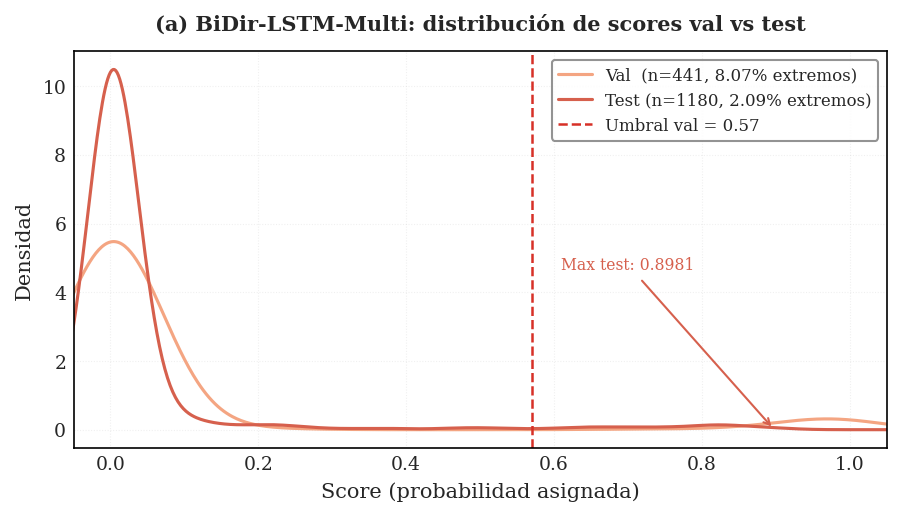

[OK] fig_bidir_multi_score_dist guardada: /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/Optimización_Bayesiana_GPU/Fig_NB02B/fig_bidir_multi_score_dist.png
  Val  — min=0.0013  max=0.9835  >thr:27/441
  Test — min=0.0013  max=0.8981  >thr:35/1180


In [ ]:
# Evidencia visual del colapso de transferencia de umbral (H2-4)
# Fuente: benchmark_predictions_NB02_gpu.csv — columna score_BiDir-LSTM-Multi

_bench_csv = f"{PRED_DIR}/benchmark_predictions_NB02_gpu.csv"
try:
    _df_bench = pd.read_csv(_bench_csv, parse_dates=['fecha'])
    _col  = 'score_BiDir-LSTM-Multi'
    _val  = _df_bench.loc[_df_bench['split'] == 'val',  _col].dropna()
    _test = _df_bench.loc[_df_bench['split'] == 'test', _col].dropna()
    _thr  = 0.57

    fig_bm, ax_bm = plt.subplots(figsize=fig_size('full', aspect=0.58))

    if len(_val) > 0:
        _val.plot.kde(ax=ax_bm, label=f'Val  (n={len(_val)}, 8.07% extremos)',
                      color=SPLIT_COLORS['validation'], linewidth=1.5)
    else:
        ax_bm.text(0.60, 0.80,
                   'Val: scores no guardados en CSV\n'
                   '(umbral=0.57 calibrado en val\n'
                   'con 8.07% extremos — COVID)',
                   transform=ax_bm.transAxes, fontsize=7.5,
                   va='top', ha='left',
                   bbox=dict(boxstyle='round,pad=0.3', fc='white',
                             ec=SPLIT_COLORS['validation'], alpha=0.8))

    if len(_test) > 0:
        _test.plot.kde(ax=ax_bm, label=f'Test (n={len(_test)}, 2.09% extremos)',
                       color=SPLIT_COLORS['test'], linewidth=1.5)

    ax_bm.axvline(_thr, color=COLOR_EXTREMO, linestyle='--', linewidth=1.2,
                  label=f'Umbral val = {_thr:.2f}')

    if len(_test) > 0:
        ax_bm.annotate(f'Max test: {_test.max():.4f}',
                       xy=(_test.max(), 0), xytext=(0.60, 0.45),
                       textcoords='axes fraction', fontsize=7.5,
                       arrowprops=dict(arrowstyle='->', color=SPLIT_COLORS['test']),
                       color=SPLIT_COLORS['test'])

    ax_bm.set_xlim(-0.05, 1.05)
    ax_bm.set_xlabel('Score (probabilidad asignada)', fontsize=10)
    ax_bm.set_ylabel('Densidad', fontsize=10)
    ax_bm.set_title('(a) BiDir-LSTM-Multi: distribución de scores val vs test', fontsize=10)
    ax_bm.legend(fontsize=8)
    ax_bm.grid(alpha=0.3, linewidth=0.5)
    fig_bm.tight_layout()

    _fig_out = f'{FIG_PATH}/fig_bidir_multi_score_dist.png'
    _fig_dir = os.path.dirname(_fig_out)
    _fig_name = os.path.splitext(os.path.basename(_fig_out))[0]
    save_fig(fig_bm, _fig_name, output_path=_fig_dir, dpi=300)
    plt.show()
    plt.close(fig_bm)
    print(f'[OK] fig_bidir_multi_score_dist guardada: {_fig_out}')
    if len(_val) > 0:
        print(f'  Val  — min={_val.min():.4f}  max={_val.max():.4f}  >thr:{(_val>=_thr).sum()}/{len(_val)}')
    else:
        print(f'  Val  — scores no disponibles en CSV consolidado')
    if len(_test) > 0:
        print(f'  Test — min={_test.min():.4f}  max={_test.max():.4f}  >thr:{(_test>=_thr).sum()}/{len(_test)}')
except FileNotFoundError:
    print(f'[SKIP] {_bench_csv} no encontrado — ejecutar NB02 completo primero')
except Exception as _e:
    print(f'[WARN] Error generando figura: {_e}')


**Qué muestra**  
Esta figura compara la distribución de scores del modelo BiDir-LSTM-Multi entre validación y test. El umbral operativo calibrado en validación se superpone para contextualizar la transferencia del criterio de decisión.

**Cómo se construye**  
Se construye a partir de los scores guardados en el consolidado de predicciones del benchmark para el modelo multivariado bidireccional. Las densidades se estiman por split y se anotan respecto al umbral operativo fijado en validación.

**Por qué se ve así**  
Si la masa de probabilidad en test se desplaza lejos del umbral de validación, la figura muestra una desalineación visible entre ambos regímenes. Ese patrón es consistente con cambios en prevalencia, calibración o separación entre clases.

**Por qué es importante**  
Esta visualización ayuda a interpretar el colapso del F1 del modelo multivariado bidireccional sin recurrir a reentrenamiento. También respalda el análisis de sensibilidad del umbral como explicación complementaria del resultado.

In [ ]:
# ─── 7.5 Resumen ejecutivo final ─────
print("=" * 65)
print("  RESUMEN EJECUTIVO — NB02 GPU experimental / Optuna")
print("=" * 65)
print(f"  Fecha ejecución       : {datetime.now().strftime('%Y-%m-%d %H:%M')}")
print(f"  Estándar mínimo (B1)  : F1={F1_MINIMO} | AUC={AUC_MINIMO}")
print(f"  Ref. cuantitativa (B5): F1={F1_CUANT_TEST} | AUC={AUC_CUANT_TEST} (test)")
print()

if not bench_test.empty:
    # Excluir modelos_extra_fuera_hipotesis antes de seleccionar ganador
    _modelos_extra = config.get('nb02_results', {}).get(
        'modelos_extra_fuera_hipotesis', {}).get('nombres', [])
    _bench_hip = bench_test[~bench_test['nombre'].isin(_modelos_extra)]
    winner = _bench_hip.iloc[0] if not _bench_hip.empty else bench_test.iloc[0]
    beats_ing  = winner.get('Beats_Ingenuo', False)
    beats_cuan = winner.get('Beats_Cuant',   False)

    print(f"  GANADOR          : {winner['nombre']}")
    print(f"  F1  (test)       : {winner['f1']:.4f}"
          f"  (Î”={winner['f1']-F1_MINIMO:+.4f} vs B1"
          f" | Î”={winner['f1']-F1_CUANT_TEST:+.4f} vs B5)")
    print(f"  AUC (test)       : {winner['auc']:.4f}"
          f"  (Î”={winner['auc']-AUC_MINIMO:+.4f} vs B1)")
    if 'auc_pr' in winner and winner['auc_pr'] == winner['auc_pr']:
        print(f"  AUC-PR (test)    : {winner['auc_pr']:.4f}")
    print()

    beats_ing_n  = bench_test['Beats_Ingenuo'].sum() \
                   if 'Beats_Ingenuo' in bench_test.columns else 0
    beats_cuan_n = bench_test['Beats_Cuant'].sum() \
                   if 'Beats_Cuant'  in bench_test.columns else 0
    print(f"  Modelos evaluados      : {len(bench_test)}")
    print(f"  Superan B1 (ingenuo)   : {beats_ing_n}/{len(bench_test)}")
    print(f"  Superan B5 (cuantitat.): {beats_cuan_n}/{len(bench_test)}")
    print()
    print("  Top 3 modelos (F1 test):")
    for _, row in bench_test.head(3).iterrows():
        b_i = row.get('Beats_Ingenuo', False)
        b_c = row.get('Beats_Cuant',   False)
        marker = '✓✓' if b_c else ('✓' if b_i else '✗')
        print(f"    {marker} {row['nombre']:35s}"
              f" F1={row['f1']:.4f} AUC={row['auc']:.4f}")

print()
print("  Archivos exportados (GPU provisional):")
print(f"    • {PRED_DIR}/pred_*.csv")
print(f"    • {PRED_DIR}/benchmark_predictions_NB02_gpu.csv")
print(f"    • {MODEL_DIR}/*.pkl / *.keras")
print(f"    • {CONFIG_PATH} (solo nb02_experiments, si aplica)")
print(f"    • fig_benchmark_comparacion.png")
print()
print("  RECOMENDACIÓN PARA NB03:")
if not bench_test.empty:
    w = bench_test.iloc[0]
    if w.get('Beats_Cuant', False):
        print(f"    '{w['nombre']}' supera B1 y B5.")
        print(f"    Contribución demostrada sobre reglas cuantitativas simples.")
    elif w.get('Beats_Ingenuo', False):
        print(f"    '{w['nombre']}' supera B1 — no supera B5.")
        print(f"    Documentar gap vs Christoffersen (1998) como limitación.")
    else:
        print("    Ningún modelo supera B1 en test.")
        print("    Revisar windowed_dataset fix + hiperparámetros.")
print("=" * 65)

  RESUMEN EJECUTIVO — NB02 GPU experimental / Optuna
  Fecha ejecución       : 2026-03-29 13:12
  Estándar mínimo (B1)  : F1=0.4872 | AUC=0.8241
  Ref. cuantitativa (B5): F1=0.5474 | AUC=0.9983 (test)

  GANADOR          : LSTM-Simple-Uni
  F1  (test)       : 0.8400  (Î”=+0.3528 vs B1 | Î”=+0.2926 vs B5)
  AUC (test)       : 0.9990  (Î”=+0.1749 vs B1)
  AUC-PR (test)    : 0.9591

  Modelos evaluados      : 8
  Superan B1 (ingenuo)   : 4/8
  Superan B5 (cuantitat.): 3/8

  Top 3 modelos (F1 test):
    ✓✓ LSTM-Simple-Uni                     F1=0.8400 AUC=0.9990
    ✓✓ BiDir-LSTM-Uni                      F1=0.6757 AUC=0.9973
    ✓✓ BiDir-LSTM-Multi                    F1=0.5977 AUC=0.9953

  Archivos exportados (GPU provisional):
    • /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/Optimización_Bayesiana_GPU/predicciones_nb02b_gpu/pred_*.csv
    • /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/Optimización_Bayesiana_GPU/predicciones_nb02b_gpu/benchmark_predictions_NB0

In [ ]:
print(f"NB02 GPU COMPLETADO (experimental): {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")

NB02 GPU COMPLETADO (experimental): 2026-03-29 13:12:23


## PARTE VIII — Optimización Bayesiana (Optuna) [COMPLEMENTARIO]

Análisis complementario post-benchmark: búsqueda bayesiana de hiperparámetros con Optuna TPE.
**No forma parte del benchmark canónico** (H0-H3). Objetivo: cuantificar si los hiperparámetros
actuales son near-óptimos o si hay gap de optimización.

**Métrica objetivo:** `val_pr_auc` de Keras — fija en todos los trials (EXP-2, 2026-03-22).
**Anti-leakage:** scaler nuevo por trial, fit solo en train, threshold optimizado en val.
**Referencia:** `docs/NB02_BAYESIAN_SEARCH_PLAN.md`

In [ ]:
# ─── 8.1 Instalación y configuración Optuna ───
if IN_COLAB:
    import subprocess
    subprocess.run(
        ['pip', 'install', 'optuna', 'optuna-integration[tensorflow]', '-q'],
        check=True
    )
import optuna
from optuna.samplers import TPESampler
from optuna.pruners import MedianPruner
optuna.logging.set_verbosity(optuna.logging.WARNING)
print(f'[OK] Optuna {optuna.__version__} listo')
print(f'[INFO] RUN_MODE: {RUN_MODE}')
print(f'[INFO] GPUs visibles por TF: {len(tf.config.list_physical_devices("GPU"))}')
print('[INFO] Métrica única: val_pr_auc (fija — no es parámetro del trial)')
print('[INFO] N_TRIALS: BiDir_Uni=30, Simple_Uni=20, Simple_Multi=20, BiDir_Multi=30')
if PART_VIII_GPU:
    print('[INFO] PARTE VIII correrá en modo acelerado con GPU.')
else:
    print('[INFO] PARTE VIII correrá en modo canónico CPU-only.')

[OK] Optuna 4.8.0 listo
[INFO] RUN_MODE: gpu_optuna
[INFO] GPUs visibles por TF: 1
[INFO] Métrica única: val_pr_auc (fija — no es parámetro del trial)
[INFO] N_TRIALS: BiDir_Uni=30, Simple_Uni=20, Simple_Multi=20, BiDir_Multi=30
[INFO] PARTE VIII correrá en modo acelerado con GPU.


In [ ]:
import os
from pathlib import Path

base = PRED_DIR
archivos = ['pred_BiDir-LSTM-Uni_test.csv',
            'pred_LSTM-Simple-Uni_test.csv',
            'pred_GARCH_test.csv',
            'benchmark_predictions_NB02_gpu.csv']

for f in archivos:
    p = Path(base) / f
    exists = p.exists()
    size = p.stat().st_size if exists else 0
    print(f"{'✅' if exists else '❌'} {f}  ({size:,} bytes)")

# Verificar politica de escritura
print(f"\nConfig canónico intacto: {CONFIG_PATH}")
print(f"Registro experimental diferido a 8.6: {'SI' if RUN_MODE == 'gpu_optuna' else 'NO'}")


✅ pred_BiDir-LSTM-Uni_test.csv  (124,433 bytes)
✅ pred_LSTM-Simple-Uni_test.csv  (128,826 bytes)
✅ pred_GARCH_test.csv  (79,414 bytes)
✅ benchmark_predictions_NB02_gpu.csv  (620,131 bytes)

Config canónico intacto: /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/config_estudio_FINAL.json
Registro experimental diferido a 8.6: SI


In [ ]:
# 8.2 Funcion objetivo Optuna (misma capa temporal; objetivo experimental)
def objective_lstm(trial, arch, X_tr, y_tr, idx_tr, target_idx_tr, segment_id_tr, X_va, y_va, idx_va, target_idx_va, segment_id_va):
    lstm_units = trial.suggest_categorical('lstm_units', [32, 64, 96, 128])
    dropout = trial.suggest_categorical('dropout', [0.1, 0.2, 0.3, 0.4])
    learning_rate = trial.suggest_float('learning_rate', 1e-4, 5e-3, log=True)
    batch_size = trial.suggest_categorical('batch_size', [16, 32, 64])
    patience_es = trial.suggest_categorical('patience_es', [10, 15, 20, 25])

    lstm_units_2 = None
    if arch == 'bidirectional':
        ratio = trial.suggest_categorical('lstm_units_2_ratio', [0.25, 0.5, 0.75])
        lstm_units_2 = max(1, int(lstm_units * ratio))

    sc_trial = StandardScaler()
    X_tr_s = sc_trial.fit_transform(X_tr)
    X_va_s = sc_trial.transform(X_va)
    if PART_VIII_GPU:
        X_tr_s = X_tr_s.astype(np.float32, copy=False)
        X_va_s = X_va_s.astype(np.float32, copy=False)

    Xw_tr, yw_tr, _, _ = windowed_dataset(X_tr_s, y_tr, idx_tr, lookback=LOOKBACK, target_index=target_idx_tr, segment_id=segment_id_tr)
    Xw_va, yw_va, _, _ = windowed_dataset(X_va_s, y_va, idx_va, lookback=LOOKBACK, target_index=target_idx_va, segment_id=segment_id_va)
    if len(np.unique(yw_tr)) < 2:
        raise optuna.TrialPruned()

    cw = compute_class_weight('balanced', classes=np.array([0, 1]), y=yw_tr)
    cw_dict = {0: float(cw[0]), 1: float(cw[1])}

    tf.random.set_seed(RANDOM_SEED); np.random.seed(RANDOM_SEED)
    n_features = X_tr_s.shape[1]
    m = build_model(input_shape=(LOOKBACK, n_features), architecture=arch, lstm_units=lstm_units, lstm_units_2=lstm_units_2, dropout=dropout, seed=RANDOM_SEED)
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate), loss='binary_crossentropy', metrics=[keras.metrics.AUC(name='auc'), keras.metrics.AUC(name='pr_auc', curve='PR')])

    cb_es = keras.callbacks.EarlyStopping(monitor='val_pr_auc', mode='max', patience=patience_es, min_delta=1e-4, restore_best_weights=True)
    cb_pr = optuna.integration.TFKerasPruningCallback(trial, 'val_pr_auc')
    cb_lr = keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=7, min_lr=1e-6, verbose=0)

    try:
        hist = m.fit(Xw_tr, yw_tr, validation_data=(Xw_va, yw_va), epochs=200, batch_size=batch_size, class_weight=cw_dict, callbacks=[cb_es, cb_pr, cb_lr], shuffle=False, verbose=0)
        best_val_pr_auc = max(hist.history['val_pr_auc'])
        best_thr_t, df_thr_t = optimize_threshold(m, Xw_va, yw_va, verbose=False)
        f1_t = float(df_thr_t.loc[df_thr_t['f1'].idxmax(), 'f1'])
        best_epoch = int(np.argmax(hist.history['val_pr_auc'])) + 1
        trial.set_user_attr('f1_val', f1_t)
        trial.set_user_attr('best_epoch', best_epoch)
        trial.set_user_attr('best_thr_val', float(best_thr_t))
        trial.set_user_attr('lstm_units_2', str(lstm_units_2))
    finally:
        del m
        keras.backend.clear_session()
    return best_val_pr_auc

In [ ]:
# ─── 8.3 Crear estudios Optuna ──
BAYESIAN_CONFIGS = {
    'simple_uni':         {'arch': 'simple',        'n': 20},
    'simple_multi':       {'arch': 'simple',        'n': 20},
    'bidirectional_uni':  {'arch': 'bidirectional', 'n': 30},
    'bidirectional_multi':{'arch': 'bidirectional', 'n': 30},
}

studies = {}
for key in BAYESIAN_CONFIGS:
    studies[key] = optuna.create_study(
        study_name=key,
        direction='maximize',
        sampler=TPESampler(seed=RANDOM_SEED),
        pruner=MedianPruner(n_startup_trials=10, n_warmup_steps=20)
    )

print(f'[OK] {len(studies)} estudios creados: {list(studies.keys())}')
print(f'[INFO] Total trials: {sum(c["n"] for c in BAYESIAN_CONFIGS.values())}')

[OK] 4 estudios creados: ['simple_uni', 'simple_multi', 'bidirectional_uni', 'bidirectional_multi']
[INFO] Total trials: 100


In [ ]:
# 8.4 Ejecutar optimizacion bayesiana
import time

OPTUNA_DATA = {
    'simple_uni': {'X_tr': df_uni_train[FEATURES_UNI].values, 'y_tr': y_train_uni, 'idx_tr': df_uni_train.index, 'target_idx_tr': df_uni_train['target_date'], 'segment_id_tr': df_uni_train['segment_id'].values, 'X_va': df_uni_val[FEATURES_UNI].values, 'y_va': y_val_uni, 'idx_va': df_uni_val.index, 'target_idx_va': df_uni_val['target_date'], 'segment_id_va': df_uni_val['segment_id'].values},
    'simple_multi': {'X_tr': df_multi_train[FEATURES_MULTI].values, 'y_tr': y_train_multi, 'idx_tr': df_multi_train.index, 'target_idx_tr': df_multi_train['target_date'], 'segment_id_tr': df_multi_train['segment_id'].values, 'X_va': df_multi_val[FEATURES_MULTI].values, 'y_va': y_val_multi, 'idx_va': df_multi_val.index, 'target_idx_va': df_multi_val['target_date'], 'segment_id_va': df_multi_val['segment_id'].values},
    'bidirectional_uni': {'X_tr': df_uni_train[FEATURES_UNI].values, 'y_tr': y_train_uni, 'idx_tr': df_uni_train.index, 'target_idx_tr': df_uni_train['target_date'], 'segment_id_tr': df_uni_train['segment_id'].values, 'X_va': df_uni_val[FEATURES_UNI].values, 'y_va': y_val_uni, 'idx_va': df_uni_val.index, 'target_idx_va': df_uni_val['target_date'], 'segment_id_va': df_uni_val['segment_id'].values},
    'bidirectional_multi': {'X_tr': df_multi_train[FEATURES_MULTI].values, 'y_tr': y_train_multi, 'idx_tr': df_multi_train.index, 'target_idx_tr': df_multi_train['target_date'], 'segment_id_tr': df_multi_train['segment_id'].values, 'X_va': df_multi_val[FEATURES_MULTI].values, 'y_va': y_val_multi, 'idx_va': df_multi_val.index, 'target_idx_va': df_multi_val['target_date'], 'segment_id_va': df_multi_val['segment_id'].values},
}

results_optuna = {}
for key, cfg in BAYESIAN_CONFIGS.items():
    data = OPTUNA_DATA[key]
    t0 = time.time()
    print(f"\n[Optuna] Iniciando {key} - {cfg['n']} trials...")
    studies[key].optimize(
        lambda trial, arch=cfg['arch'], d=data: objective_lstm(trial, arch, d['X_tr'], d['y_tr'], d['idx_tr'], d['target_idx_tr'], d['segment_id_tr'], d['X_va'], d['y_va'], d['idx_va'], d['target_idx_va'], d['segment_id_va']),
        n_trials=cfg['n'],
        show_progress_bar=True
    )
    best = studies[key].best_trial
    elapsed = (time.time() - t0) / 60
    results_optuna[key] = {'best_pr_auc_val': best.value, 'best_params': best.params, 'f1_val': best.user_attrs.get('f1_val', None), 'best_epoch': best.user_attrs.get('best_epoch', None), 'best_thr_val': best.user_attrs.get('best_thr_val', None), 'n_trials': len(studies[key].trials), 'elapsed_min': round(elapsed, 1)}
    print(f"  Best PR-AUC val: {best.value:.4f} | F1 val: {best.user_attrs.get('f1_val', 0):.4f}")
    print(f"  Params: {best.params} | {elapsed:.1f} min")

print('\n[OK] Optimizacion Bayesiana completada.')


[Optuna] Iniciando simple_uni - 20 trials...


  0%|          | 0/20 [00:00<?, ?it/s]

  Best PR-AUC val: 0.9988 | F1 val: 0.9831
  Params: {'lstm_units': 128, 'dropout': 0.2, 'learning_rate': 0.003991533220217488, 'batch_size': 32, 'patience_es': 25} | 21.5 min

[Optuna] Iniciando simple_multi - 20 trials...


  0%|          | 0/20 [00:00<?, ?it/s]

  Best PR-AUC val: 1.0000 | F1 val: 1.0000
  Params: {'lstm_units': 128, 'dropout': 0.3, 'learning_rate': 0.00023101454357164726, 'batch_size': 32, 'patience_es': 15} | 11.3 min

[Optuna] Iniciando bidirectional_uni - 30 trials...


  0%|          | 0/30 [00:00<?, ?it/s]

  Best PR-AUC val: 1.0000 | F1 val: 1.0000
  Params: {'lstm_units': 64, 'dropout': 0.3, 'learning_rate': 0.004092945365562028, 'batch_size': 16, 'patience_es': 25, 'lstm_units_2_ratio': 0.5} | 74.1 min

[Optuna] Iniciando bidirectional_multi - 30 trials...


  0%|          | 0/30 [00:00<?, ?it/s]

  Best PR-AUC val: 1.0000 | F1 val: 1.0000
  Params: {'lstm_units': 64, 'dropout': 0.3, 'learning_rate': 0.000267775333103133, 'batch_size': 16, 'patience_es': 15, 'lstm_units_2_ratio': 0.5} | 33.4 min

[OK] Optimizacion Bayesiana completada.


In [ ]:
# ─── 8.5 Comparación best trial vs benchmark fijo ───
# FIX-2: tablas separadas — métricas val (Optuna) y test (benchmark) no son
#         directamente comparables: dominios distintos y objetivos distintos.
# FIX-3: `is not None` en lugar de truthiness para threshold=0.0

# RESULTS_REGISTRY es lista de dicts — acceso por nombre y split
def _get_bench(nombre, split='test'):
    r = next((r for r in RESULTS_REGISTRY if r['nombre'] == nombre and r['split'] == split), None)
    return r if r else {'f1': float('nan'), 'auc_pr': float('nan')}

BENCH_NOMBRES = {
    'simple_uni':         'LSTM-Simple-Uni',
    'simple_multi':       'LSTM-Simple-Multi',
    'bidirectional_uni':  'BiDir-LSTM-Uni',
    'bidirectional_multi':'BiDir-LSTM-Multi',
}

import pandas as pd

# ── Tabla A: resultados Optuna (validación) ────
rows_val = []
for key in BAYESIAN_CONFIGS:
    opt = results_optuna[key]
    # FIX-3: is not None (threshold=0.0 es válido, fallaría con truthiness)
    thr_str = f"{opt['best_thr_val']:.4f}" if opt['best_thr_val'] is not None else '—'
    rows_val.append({
        'Modelo':             key,
        'PR-AUC val':         f"{opt['best_pr_auc_val']:.4f}",
        'F1 val':             f"{opt['f1_val']:.4f}" if opt['f1_val'] is not None else '—',
        'Thr val':            thr_str,
        'Best epoch':         opt['best_epoch'],
        'n_trials':           opt['n_trials'],
        'Elapsed (min)':      opt['elapsed_min'],
    })

print('=== TABLA A — Optuna: resultados en VALIDACIÓN ===')
print('    (criterio de selección del trial ganador)')
print(pd.DataFrame(rows_val).to_string(index=False))

# ── Tabla B: benchmark canónico (test) — solo referencia ──
rows_test = []
for key in BAYESIAN_CONFIGS:
    ref = _get_bench(BENCH_NOMBRES[key], split='test')
    rows_test.append({
        'Modelo':             key,
        'F1 test (bench)':    f"{ref['f1']:.4f}",
        'PR-AUC test (bench)':f"{ref['auc_pr']:.4f}",
    })

print('\n=== TABLA B — Benchmark fijo: resultados en TEST (referencia) ===')
print('    (hiperparámetros fijos, no optimizados con Optuna)')
print(pd.DataFrame(rows_test).to_string(index=False))

print('\n⚠️  Tablas A y B NO son directamente comparables:')
print('    A = val (2019-2020, 8.07% extremos) | B = test (2021-2026, 2.09% extremos)')
print('    Para comparar en test: re-entrenar best trial con params ganadores')
print('    y evaluar en test con optimize_threshold → evaluar_baseline.')

In [ ]:
# --- 8.6 Exportar resultados GPU y registrar nb02_experiments
import shutil

# Exportar trials Optuna a carpeta GPU dedicada
for key, study in studies.items():
    df_t = study.trials_dataframe()
    fname = f"{OPTUNA_DIR}/optuna_trials_{key}.csv"
    df_t.to_csv(fname, index=False)
    print(f'  [OK] {fname}  ({len(df_t)} trials)')

optuna_summary = {
    'fecha': datetime.now().strftime('%Y-%m-%dT%H:%M'),
    'run_mode': RUN_MODE,
    'status': 'PROVISIONAL',
    'n_total': sum(r['n_trials'] for r in results_optuna.values()),
    'resultados': results_optuna,
}
optuna_summary_path = f"{OPTUNA_DIR}/optuna_summary.json"
with open(optuna_summary_path, 'w', encoding='utf-8') as f:
    _json.dump(optuna_summary, f, indent=2, default=str, ensure_ascii=False)

if WRITE_EXPERIMENTS:
    with open(CONFIG_PATH, 'r', encoding='utf-8') as f:
        config_out = json.load(f)

    canonical_layer = config_out.get('nb02_results', {})
    canonical_metadata = config_out.get('nb02_metadata', {})
    canonical_scope = canonical_layer.get('scope')
    canonical_status = canonical_layer.get('status')
    canonical_run_mode = None
    if isinstance(canonical_metadata, dict):
        canonical_run_mode = canonical_metadata.get('entorno', {}).get('run_mode')

    canonical_ready = (
        bool(canonical_layer)
        and canonical_scope == 'benchmark_cpu_canonico_h0_h3'
        and canonical_status == 'VALIDO'
        and canonical_run_mode == 'canonical_cpu'
    )

    if not canonical_ready:
        print('[SKIP] NB02 GPU no escribe nb02_experiments porque falta la capa canonica CPU valida.')
        print(f"       scope encontrado : {canonical_scope if canonical_scope else 'ausente'}")
        print(f"       status encontrado: {canonical_status if canonical_status else 'ausente'}")
        print(f"       run_mode meta    : {canonical_run_mode if canonical_run_mode else 'ausente'}")
        print('       Orden correcto: NB01 -> NB03A/NB03B opcionales -> NB02 CPU -> NB02 GPU.')
    else:
        GPU_SOURCE_TAG = os.environ.get('NB02_GPU_SOURCE_TAG', 'NB02_GPU_OPTUNA')
        CANONICAL_GPU_PATHS = {
            'figures': 'results/figures/NB02_GPU',
            'predictions': 'results/predictions/nb02_gpu',
            'benchmark_predictions': 'results/predictions/nb02_gpu/benchmark_predictions_NB02_gpu.csv',
            'optuna': 'results/metrics/nb02_gpu_optuna',
            'models': 'models/experiments/nb02_gpu',
        }

        exp_modelos = {}
        for r in RESULTS_REGISTRY:
            if r.get('split') != 'test' or r.get('status', '') != '':
                continue
            model_name = r['nombre']
            if model_name.startswith('B1') or model_name.startswith('B5'):
                continue
            exp_modelos[model_name] = {
                'f1_test': safe_float(r['f1']),
                'auc_roc_test': safe_float(r['auc']),
                'auc_pr_test': safe_float(r.get('auc_pr')),
            }

        config_out['nb02_experiments'] = {
            '_nota': 'PROVISIONAL - corrida gpu_optuna. No sobreescribe nb02_results canónico.',
            'run_mode': 'gpu_optuna',
            'fecha': optuna_summary['fecha'],
            'status': 'PROVISIONAL',
            'fuente': GPU_SOURCE_TAG,
            'exp_activos': [
                f'EXP-2: EarlyStopping Multi -> {EARLYSTOP_MONITOR_MULTI}',
                'PARTE VIII: Optuna TPE + MedianPruner',
            ],
            'paths': CANONICAL_GPU_PATHS,
            'optuna': {
                'n_trials': int(sum(r['n_trials'] for r in results_optuna.values())),
                'metric': 'val_pr_auc_experimental',
                'archivo': 'results/metrics/nb02_gpu_optuna/optuna_summary.json',
            },
            'modelos': exp_modelos,
        }

        tmp_path = CONFIG_PATH + '.tmp'
        try:
            with open(tmp_path, 'w', encoding='utf-8') as f:
                json.dump(config_out, f, ensure_ascii=False, indent=2)
            shutil.move(tmp_path, CONFIG_PATH)
            print(f'[OK] nb02_experiments actualizado en {CONFIG_PATH}')
            print(f'[INFO] Espejo repo esperado: {CONFIG_REPO_MIRROR}')
        except Exception as e:
            if os.path.exists(tmp_path):
                os.remove(tmp_path)
            raise RuntimeError(f'Error escribiendo nb02_experiments: {e}')
else:
    print('[SKIP] WRITE_EXPERIMENTS=False - config no modificado.')

print('\n[OK] Exportacion GPU completada.')
print(f'[INFO] Predicciones GPU : {PRED_DIR}')
print(f'[INFO] Artefactos Optuna: {OPTUNA_DIR}')
print(f'[INFO] Modelos GPU      : {MODEL_DIR}')
print('[INFO] Este notebook escribe solo nb02_experiments y preserva nb02_results.')
print('[INFO] Para análisis post-hoc:')
print('       optuna.visualization.plot_param_importances(studies["bidirectional_uni"])')
print('\n[LOG] Copiar al registrar en docs/bitacora-experimentos.md:')
_ts = datetime.now().strftime('%Y%m%d')
for key, r in results_optuna.items():
    print(f'  EXP-OPTUNA-{_ts}-{key}: '
          f'best_pr_auc={r["best_pr_auc_val"]:.4f}, '
          f'n={r["n_trials"]}, '
          f'params={r["best_params"]}')

In [ ]:
# ─── ABLACIÓN: val_loss vs val_auc vs val_pr_auc
# Propósito: cuantificar el impacto del criterio de EarlyStopping.
# val_pr_auc añadido por recomendación metodológica:
# Se re-entrena SOLO el modelo ganador — no todo el benchmark.
# Resultado se reporta como hallazgo, no reemplaza los resultados principales.

tf.random.set_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# Función de callbacks para val_auc
def make_callbacks_auc(model_name, output_path=MODEL_DIR, patience=15):
    """Callbacks con val_auc — ablación únicamente."""
    ckpt_path = f"{output_path}/{model_name}_auc_best.keras"
    return [
        keras.callbacks.EarlyStopping(
            monitor='val_auc', mode='max', patience=patience,
            restore_best_weights=True, min_delta=1e-4, verbose=1),
        keras.callbacks.ModelCheckpoint(
            ckpt_path, monitor='val_auc', mode='max',
            save_best_only=True, verbose=0),
        keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5, patience=7,
            min_lr=1e-6, verbose=1),
    ]

# ── Función de callbacks para val_pr_auc
def make_callbacks_pr_auc(model_name, output_path=MODEL_DIR, patience=15):
    """Callbacks con val_pr_auc — ablación únicamente.
    AUC-PR es más discriminante que AUC-ROC bajo desbalanceo extremo:
    Precision = TP/(TP+FP) no está diluida por TN masivos.
    """
    ckpt_path = f"{output_path}/{model_name}_prauc_best.keras"
    return [
        keras.callbacks.EarlyStopping(
            monitor='val_pr_auc', mode='max', patience=patience,
            restore_best_weights=True, min_delta=1e-4, verbose=1),
        keras.callbacks.ModelCheckpoint(
            ckpt_path, monitor='val_pr_auc', mode='max',
            save_best_only=True, verbose=0),
        keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5, patience=7,
            min_lr=1e-6, verbose=1),
    ]

# ── Función auxiliar: compilar con métricas necesarias ────
def build_model_ablacion(architecture='bidirectional'):
    """Modelo idéntico al benchmark pero compilado con auc + pr_auc."""
    m = build_model(
        input_shape=(LOOKBACK, len(FEATURES_UNI)),
        architecture=architecture,
        lstm_units=64, dropout=0.2, seed=RANDOM_SEED
    )
    m.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss='binary_crossentropy',
        metrics=[
            keras.metrics.AUC(name='auc'),
            keras.metrics.AUC(name='pr_auc', curve='PR')  # registra val_pr_auc
        ]
    )
    return m

# ── Entrenar variante val_auc
print("Entrenando BiDir-LSTM-Uni con val_auc...")
tf.random.set_seed(RANDOM_SEED); np.random.seed(RANDOM_SEED)
model_abl_auc = build_model_ablacion()
history_auc   = model_abl_auc.fit(
    Xw_train_uni, yw_train_uni.astype(np.float32),
    validation_data=(Xw_val_uni, yw_val_uni.astype(np.float32)),
    epochs=200, batch_size=32, class_weight=CLASS_WEIGHTS,
    callbacks=make_callbacks_auc('lstm_uni_bidir_ablacion_auc'),
    shuffle=False, verbose=0
)
epocas_auc = len(history_auc.history['loss'])

# ── Entrenar variante val_pr_auc ───
print("Entrenando BiDir-LSTM-Uni con val_pr_auc...")
tf.random.set_seed(RANDOM_SEED); np.random.seed(RANDOM_SEED)
model_abl_pr  = build_model_ablacion()
history_pr    = model_abl_pr.fit(
    Xw_train_uni, yw_train_uni.astype(np.float32),
    validation_data=(Xw_val_uni, yw_val_uni.astype(np.float32)),
    epochs=200, batch_size=32, class_weight=CLASS_WEIGHTS,
    callbacks=make_callbacks_pr_auc('lstm_uni_bidir_ablacion_prauc'),
    shuffle=False, verbose=0
)
epocas_pr = len(history_pr.history['loss'])

# ── Evaluar las dos variantes en test ───
def evaluar_variante(model, nombre):
    ys_val  = model.predict(Xw_val_uni,  verbose=0).ravel()
    ys_test = model.predict(Xw_test_uni, verbose=0).ravel()
    _, df_thr = optimize_threshold(model, Xw_val_uni, yw_val_uni)
    thr = float(df_thr.loc[df_thr['f1'].idxmax(), 'threshold'])
    yp  = (ys_test >= thr).astype(int)
    return evaluar_baseline(nombre, yw_test_uni.astype(int), yp,
                            y_score=ys_test, split='test')

m_auc = evaluar_variante(model_abl_auc, 'BiDir-LSTM-Uni [val_auc]')
m_pr  = evaluar_variante(model_abl_pr,  'BiDir-LSTM-Uni [val_pr_auc]')

# ── Recuperar baseline original (val_loss) ─────
m_loss = next(r for r in RESULTS_REGISTRY
              if 'BiDir' in r['nombre'] and 'Uni' in r['nombre']
              and r['split'] == 'test'
              and 'auc' not in r['nombre'].lower())
epocas_loss = len(history_uni_bidir.history['loss'])  # del entrenamiento original

# ── Tabla comparativa ─────
print()
print("ABLACIÓN — Impacto del criterio de EarlyStopping (BiDir-LSTM-Uni, TEST)")
print("─" * 72)
print(f"  {'Monitor':<22} {'F1':>7} {'AUC-ROC':>9} {'AUC-PR':>8} "
      f"{'Recall':>8} {'Prec':>8} {'Épocas':>8}")
print("─" * 72)

for m, label, epocas in [
    (m_loss, 'val_loss  (benchmark)', epocas_loss),
    (m_auc,  'val_auc   (ablación)',  epocas_auc),
    (m_pr,   'val_pr_auc(ablación)',  epocas_pr),
]:
    auc_pr_str = f"{m.get('auc_pr', float('nan')):.4f}" \
                 if not np.isnan(m.get('auc_pr', float('nan'))) else "   N/A"
    print(f"  {label:<22} {m['f1']:>7.4f} {m['auc']:>9.4f} "
          f"{auc_pr_str:>8} {m['recall']:>8.4f} {m['precision']:>8.4f} "
          f"{epocas:>8}")

print("─" * 72)

# Deltas respecto al benchmark
df1_auc = m_auc['f1'] - m_loss['f1']
df1_pr  = m_pr['f1']  - m_loss['f1']
print(f"\n  Î”F1 (val_auc    vs val_loss) = {df1_auc:+.4f}")
print(f"  Î”F1 (val_pr_auc vs val_loss) = {df1_pr:+.4f}")

# Interpretación automática — usar el mayor delta
delta_max   = max(abs(df1_auc), abs(df1_pr))
mejor_monitor = 'val_pr_auc' if abs(df1_pr) >= abs(df1_auc) else 'val_auc'

if delta_max < 0.02:
    conclusion = (f"Diferencia marginal (Î”F1_max={delta_max:+.4f}). "
                  f"val_loss fue proxy suficiente — desbalanceo val (8.07%) "
                  f"moderado evita colapso de BCE.")
elif delta_max < 0.05:
    conclusion = (f"Diferencia moderada (Î”F1_max={delta_max:+.4f}). "
                  f"Resultado exploratorio — no redefine benchmark CPU ni contratos downstream.")
else:
    conclusion = (f"Diferencia significativa (Î”F1_max={delta_max:+.4f}). "
                  f"{mejor_monitor} produce mejora real. "
                  f"Considerar re-entrenar benchmark completo.")

print(f"\n  INTERPRETACIÓN: {conclusion}")
print(f"  RESULTADO EXPLORATORIO:  {mejor_monitor} muestra diferencia moderada. Adopción futura requiere decisión metodológica separada y re-ejecución controlada.")

(Saito & Rehmsmeier, 2015 — "The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets")

### Comparación Visual de Métricas (val_loss vs val_auc)

In [ ]:
metrics_df = pd.DataFrame({
    'Metric':                ['F1-Score', 'AUC-ROC', 'AUC-PR', 'Precision', 'Recall'],
    'val_loss (benchmark)':  [m_loss['f1'], m_loss['auc'],
                              m_loss.get('auc_pr', float('nan')),
                              m_loss['precision'], m_loss['recall']],
    'val_auc (ablación)':    [m_auc['f1'],  m_auc['auc'],
                              m_auc.get('auc_pr', float('nan')),
                              m_auc['precision'],  m_auc['recall']],
    'val_pr_auc (ablación)': [m_pr['f1'],   m_pr['auc'],
                              m_pr.get('auc_pr', float('nan')),
                              m_pr['precision'],   m_pr['recall']],
})

metrics_df_melted = metrics_df.melt(
    id_vars='Metric', var_name='Monitor', value_name='Value')

fig, ax = plt.subplots(figsize=fig_size("full"))
palette = {'val_loss (benchmark)': COLOR_VAR,
           'val_auc (ablación)':   COLOR_DYN,
           'val_pr_auc (ablación)':COLOR_EXTREMO}
sns.barplot(x='Metric', y='Value', hue='Monitor',
            data=metrics_df_melted, palette=palette, ax=ax)

for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', label_type='edge',
                 fontsize=5, padding=2)

ax.set_ylim(0, 1.35)
ax.set_title('(a) Ablación: Criterio de EarlyStopping — BiDir-LSTM-Uni (Test)',
             fontweight='bold', pad=40)
ax.set_ylabel('Valor de la Métrica')
ax.set_xlabel('Métrica de Evaluación')
ax.legend(
    title='Monitor EarlyStopping',
    loc='upper center',
    fontsize=8,
    frameon=False,
    ncol=3
)


ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
save_fig(fig, 'fig_ablacion_earlystopping', output_path=FIG_PATH, dpi=300)

plt.show()
plt.close()
print("Figura guardada: fig_ablacion_earlystopping.png")

### Ablación del criterio de EarlyStopping

Se realizó un experimento de ablación re-entrenando el modelo ganador (`BiDir-LSTM-Uni`) utilizando tres criterios alternativos de EarlyStopping: `val_loss` (benchmark principal), `val_auc` y `val_pr_auc`.

El objetivo es evaluar si el criterio de parada temprana influye de manera relevante en el desempeño fuera de muestra. La comparación se basa en la diferencia en F1 sobre el conjunto de test (ΔF1), interpretada bajo la siguiente regla ex-ante:

- ΔF1 < 0.02 → diferencia marginal; `val_loss` es un proxy suficiente  
- 0.02 ≤ ΔF1 < 0.05 → diferencia moderada; resultado exploratorio  
- ΔF1 ≥ 0.05 → diferencia significativa; justificar re-entrenamiento del benchmark  

Los resultados cuantitativos se presentan en la figura de ablación correspondiente.

---

### Limitación metodológica: uso de `val_loss`

El benchmark principal utiliza `val_loss` como criterio de EarlyStopping. Dado el desbalanceo de clases, esta métrica puede estar dominada por la clase mayoritaria, ya que la función de pérdida en validación no incorpora ponderación por clase.

Sin embargo, en este caso específico, el conjunto de validación contiene una proporción relevante de eventos extremos (≈8%), lo que evita un colapso hacia la clase dominante. Adicionalmente, los modelos alcanzan AUC elevados en test, lo que indica que `val_loss` funcionó como un proxy adecuado para la optimización.

---

### Interpretación

La ablación permite aislar el efecto del criterio de entrenamiento sin alterar el resto del pipeline. En este contexto, cualquier mejora observada al usar `val_auc` o `val_pr_auc` se interpreta como evidencia exploratoria, pero no implica una modificación automática del benchmark.

El uso de `val_loss` se mantiene como referencia canónica para preservar la consistencia metodológica entre modelos (GARCH, LSTM univariado y multivariado).

---

### Nota

Este análisis es exploratorio. La adopción de un criterio alternativo requeriría re-entrenar el benchmark completo bajo un protocolo controlado.

In [ ]:
# ─── MANTENIMIENTO: registrar dependencias en requirements.txt ──
# No forma parte del benchmark analítico. Ejecutar solo al final de corrida de cierre.
# Genera/actualiza la sección NB02 en requirements.txt con los paquetes ML/DL usados.
# ─
if IN_COLAB:
    import re

    def _update_req_section(req_path, section_id, header_comment, packages):
        import subprocess, re, os
        result = subprocess.run(["pip", "freeze"], capture_output=True, text=True)
        lines_found = sorted(set([
            l for l in result.stdout.splitlines()
            if any(l.lower().startswith(pkg.lower()) for pkg in packages)
        ]))
        try:
            with open(req_path, encoding="utf-8") as _f:
                content = _f.read()
        except FileNotFoundError:
            content = (
                "# =====================================================================\n"
                "# requirements.txt -- Proyecto WTI: Prediccion de Volatilidad\n"
                "# Entorno: Python 3.10+ (Google Colab)\n"
                "# Creado: " + datetime.now().strftime("%Y-%m-%d") + "\n"
                "# =====================================================================\n"
                "#\n"
                "# pip install -r requirements.txt   (instala todo)\n"
                "#\n"
            )
        sec_start = "# -- " + section_id + ": " + header_comment
        sec_end   = "# -- [END " + section_id + "]"
        nueva = (
            "\n" + sec_start + " (actualizado " + datetime.now().strftime("%Y-%m-%d") + ") --\n"
            + "\n".join(lines_found)
            + "\n" + sec_end + "\n"
        )
        patron = re.compile(
            re.escape("# -- " + section_id + ":") + r".*?" + re.escape(sec_end) + r"\n",
            re.DOTALL
        )
        content = patron.sub(nueva, content) if patron.search(content) else content + nueva
        os.makedirs(os.path.dirname(req_path) or ".", exist_ok=True)
        with open(req_path, "w", encoding="utf-8") as _f:
            _f.write(content)
        print("  [OK] requirements.txt -- seccion " + section_id + ": " + str(len(lines_found)) + " paquetes")
        for l in lines_found:
            print("       " + l)
        return lines_found

    REQ_PATH = f"{BASE_PATH}/requirements.txt"
    _update_req_section(
        req_path      = REQ_PATH,
        section_id    = "NB02",
        header_comment= "Benchmark de Modelos (ML/DL)",
        packages      = [
            "arch", "imbalanced-learn", "tensorflow",
        ]
    )
    print(f"  requirements.txt: {REQ_PATH}")

In [ ]:
# -- Resumen de Parámetros clave — generado dinámicamente (EXPERIMENTAL) --
# ADVERTENCIA: este notebook NO define el benchmark canonico H0-H3.
# Generado dinamicamente desde variables del notebook; no hardcodeado.
# Fuente contextual: config/config_estudio_FINAL.json (si se usa).

# -- Resumen de Parametros clave - generado dinamicamente (GPU experimental) --
# Objetivo:
# 1) separar mejor experimental base vs mejor adicional
# 2) excluir XGBoost si esta marcado como invalido
# 3) mostrar errores/notas de XGBoost
# 4) dejar explicito que GPU NO redefine el benchmark canonico CPU

from IPython.display import display, Markdown

def _get_any(*names, default=None):
    for name in names:
        if name in globals():
            value = globals()[name]
            if value is not None:
                return value
    return default

def _cfg_get(*keys, default=None):
    for root_name in ("config", "config_base"):
        root = globals().get(root_name)
        if not isinstance(root, dict):
            continue
        cur = root
        ok = True
        for key in keys:
            if isinstance(cur, dict) and key in cur:
                cur = cur[key]
            else:
                ok = False
                break
        if ok and cur is not None:
            return cur
    return default

def _is_missing(x):
    if x is None:
        return True
    try:
        if isinstance(x, float) and x != x:
            return True
    except Exception:
        pass
    text = str(x).strip()
    return text in ("", "None", "nan", "NaN", "No disponible")

def _num(x):
    if _is_missing(x):
        return None
    try:
        return float(x)
    except Exception:
        return None

def _fmt_list(values, max_items=8):
    if not isinstance(values, (list, tuple)):
        return str(values)
    items = [f"`{x}`" for x in values[:max_items]]
    extra = f" ... (+{len(values) - max_items} mas)" if len(values) > max_items else ""
    return ", ".join(items) + extra

def _fmt_value(value):
    if _is_missing(value):
        return "*No disponible en variables actuales*"
    if isinstance(value, bool):
        return str(value)
    if isinstance(value, (list, tuple)):
        return _fmt_list(value)
    try:
        if not isinstance(value, str):
            num = float(value)
            return f"{num:.4f}"
    except Exception:
        pass
    text = str(value)
    if "/" in text or text.endswith((".csv", ".json", ".ipynb")):
        return f"`{text}`"
    return text

def _pick_col(df, *candidates):
    if not hasattr(df, "columns"):
        return None
    cols = set(df.columns)
    for c in candidates:
        if c in cols:
            return c
    return None

def _norm_name(name):
    return str(name).strip().lower()

def _collect_note_parts(obj, keys):
    parts = []
    for key in keys:
        try:
            value = obj.get(key)
        except Exception:
            value = None
        if not _is_missing(value):
            parts.append(f"{key}={value}")
    return parts

def _collect_rows_from_df(df, origin):
    rows = []
    if not (hasattr(df, "iterrows") and hasattr(df, "columns")):
        return rows

    model_col = _pick_col(df, "model", "modelo", "nombre")
    f1_col = _pick_col(df, "f1_test", "f1")
    auc_col = _pick_col(df, "auc_test", "auc", "auc_roc_test", "auc_roc")
    status_col = _pick_col(df, "status", "estado")
    invalid_col = _pick_col(df, "is_invalid", "invalid", "valido")

    if model_col is None:
        return rows

    note_keys = [
        "note", "nota", "error", "warning", "warnings",
        "motivo", "razon", "detalle", "diagnostico", "comentario"
    ]

    for _, row in df.iterrows():
        name = str(row.get(model_col, "")).strip()
        if not name:
            continue

        f1 = _num(row.get(f1_col)) if f1_col else None
        auc = _num(row.get(auc_col)) if auc_col else None
        status = str(row.get(status_col, "")).strip() if status_col else ""

        note_parts = _collect_note_parts(row, note_keys)
        note_text = " | ".join(note_parts)

        is_invalid = False
        if invalid_col:
            raw_invalid = row.get(invalid_col)
            key = invalid_col.lower()
            raw_text = str(raw_invalid).strip().lower()
            if key in ("is_invalid", "invalid"):
                is_invalid = raw_text in ("1", "true", "yes", "si")
            elif key == "valido":
                is_invalid = raw_text in ("0", "false", "no")

        combined = f"{status} | {note_text}".lower()
        if any(token in combined for token in ["inval", "corrupt", "imposible", "descart"]):
            is_invalid = True

        is_xgb = ("xgboost" in _norm_name(name)) or _norm_name(name).startswith("xgb")

        rows.append({
            "name": name,
            "norm_name": _norm_name(name),
            "f1": f1,
            "auc": auc,
            "status": status,
            "note": note_text,
            "is_invalid": is_invalid,
            "is_xgb": is_xgb,
            "origin": origin,
        })

    return rows

def _collect_rows_from_registry(registry, origin):
    rows = []
    if registry is None or hasattr(registry, "iterrows"):
        return rows

    note_keys = [
        "status", "estado", "note", "nota", "error", "warning", "warnings",
        "motivo", "razon", "detalle", "diagnostico", "comentario"
    ]

    if isinstance(registry, dict):
        items = registry.items()
    elif isinstance(registry, list):
        items = enumerate(registry)
    else:
        return rows

    for key, value in items:
        if not isinstance(value, dict):
            continue

        name = (
            value.get("model")
            or value.get("modelo")
            or value.get("nombre")
            or str(key)
        )
        name = str(name).strip()
        if not name:
            continue

        f1 = _num(value.get("f1_test")) if "f1_test" in value else _num(value.get("f1"))
        auc = (
            _num(value.get("auc_test"))
            if "auc_test" in value else
            _num(value.get("auc_roc_test"))
            if "auc_roc_test" in value else
            _num(value.get("auc"))
        )

        note_parts = []
        for k in note_keys:
            if k in value and not _is_missing(value[k]):
                note_parts.append(f"{k}={value[k]}")
        note_text = " | ".join(note_parts)
        status = str(value.get("status") or value.get("estado") or "").strip()

        raw_invalid = value.get("is_invalid", value.get("invalid", None))
        is_invalid = str(raw_invalid).strip().lower() in ("1", "true", "yes", "si")
        combined = f"{status} | {note_text}".lower()
        if any(token in combined for token in ["inval", "corrupt", "imposible", "descart"]):
            is_invalid = True

        is_xgb = ("xgboost" in _norm_name(name)) or _norm_name(name).startswith("xgb")

        rows.append({
            "name": name,
            "norm_name": _norm_name(name),
            "f1": f1,
            "auc": auc,
            "status": status,
            "note": note_text,
            "is_invalid": is_invalid,
            "is_xgb": is_xgb,
            "origin": origin,
        })

    return rows

def _dedupe_rows(rows):
    merged = {}
    for row in rows:
        key = row["norm_name"]
        prev = merged.get(key)
        if prev is None:
            merged[key] = row
            continue

        prev_score = (
            prev["f1"] is not None,
            prev["origin"] == "experimental_base",
            not prev["is_invalid"],
        )
        cur_score = (
            row["f1"] is not None,
            row["origin"] == "experimental_base",
            not row["is_invalid"],
        )
        if cur_score > prev_score:
            merged[key] = row
    return list(merged.values())

_nb_file = "2 _WTI_ Benchmark_Optimizacion Bayesiana GPU.ipynb"
_nb_rol = "EXPERIMENTAL - Optimizacion Bayesiana GPU (Optuna)"

_output_path = _get_any("OUTPUT_PATH", "output_path")
_experiments_dir = _get_any(
    "EXPERIMENTS_DIR",
    "experiments_dir",
    default=_cfg_get("nb02_experiments", "paths", "models")
)
_predictions_dir = _get_any(
    "PREDICTIONS_DIR",
    "predictions_dir",
    "PRED_DIR",
    default=_cfg_get("nb02_experiments", "paths", "predictions")
)

_feat = _get_any("FEATURES_MULTI", default=_cfg_get("nb02", "features", "FEATURES_MULTI", default=[]))
_seed = _get_any("RANDOM_SEED", "SEED", "seed")
_p95 = _get_any(
    "THRESHOLD", "threshold", "p95_threshold", "UMBRAL_CLASIFICACION",
    default=_cfg_get("nb02", "umbral_clasificacion")
)
_lookback = _get_any("LOOKBACK", "lookback", default=_cfg_get("nb02", "features", "LOOKBACK"))

_studies = _get_any("studies")
if isinstance(_studies, dict):
    _study_keys = _fmt_list(list(_studies.keys()))
else:
    _study_keys = _get_any("study_name", default="*No disponible en variables actuales*")

_bay_configs = _get_any("BAYESIAN_CONFIGS")
if isinstance(_bay_configs, dict):
    _bay_keys = _fmt_list(list(_bay_configs.keys()))
else:
    _bay_keys = "*No disponible en variables actuales*"

rows = []

_bench = _get_any("bench_test", "benchmark_test", "results_test_df", "benchmark_gpu_test")
rows += _collect_rows_from_df(_bench, origin="experimental_base")

_registry_base = _get_any("RESULTS_REGISTRY", "results_registry")
rows += _collect_rows_from_df(_registry_base, origin="experimental_base")
rows += _collect_rows_from_registry(_registry_base, origin="experimental_base")

_registry_compl = _get_any("RESULTS_REGISTRY_COMPL", "results_registry_compl", "registry_compl")
rows += _collect_rows_from_df(_registry_compl, origin="adicional")
rows += _collect_rows_from_registry(_registry_compl, origin="adicional")

_cfg_gpu_models = _cfg_get("nb02_experiments", "modelos")
rows += _collect_rows_from_registry(_cfg_gpu_models, origin="experimental_base")

rows = _dedupe_rows(rows)

BASE_GPU_MODELS = {
    _norm_name("GARCH-GJR-GARCH"),
    _norm_name("LSTM-Simple-Uni"),
    _norm_name("BiDir-LSTM-Uni"),
    _norm_name("LSTM-Simple-Multi"),
    _norm_name("BiDir-LSTM-Multi"),
    _norm_name("Hybrid-LSTM-Sentimiento"),
    _norm_name("Hybrid-LSTM-MktSignals"),
}

valid_rows = [r for r in rows if not r["is_invalid"] and r["f1"] is not None]
base_rows = [r for r in valid_rows if r["norm_name"] in BASE_GPU_MODELS]
additional_rows = [r for r in valid_rows if r["norm_name"] not in BASE_GPU_MODELS]

_best_base = max(base_rows, key=lambda r: r["f1"]) if base_rows else None
_best_add = max(additional_rows, key=lambda r: r["f1"]) if additional_rows else None

xgb_rows = [r for r in rows if r["is_xgb"]]
xgb_invalid_rows = [r for r in xgb_rows if r["is_invalid"]]

_xgb_msgs = []
for r in xgb_invalid_rows:
    detail = r["note"] or r["status"] or "Marcado como invalido en la corrida actual"
    _xgb_msgs.append(f"`{r['name']}`: {detail}")

if not _xgb_msgs and xgb_rows:
    for r in xgb_rows:
        detail = r["note"] or r["status"] or "Sin error explicitado en variables actuales"
        _xgb_msgs.append(f"`{r['name']}`: {detail}")

_resumen = {
    "Notebook": f"{_nb_file} | Rol: {_nb_rol}",
    "Clasificacion": "EXPERIMENTAL - no redefine benchmark canonico",
    "ADVERTENCIA": "Los resultados GPU NO sustituyen el benchmark CPU canonico H0-H3.",
    "RUN_MODE": _get_any("RUN_MODE", default="gpu_optuna"),
    "OUTPUT_PATH": _output_path,
    "EXPERIMENTS_DIR": _experiments_dir,
    "PREDICTIONS_DIR": _predictions_dir,
    "Seed": _seed,
    "P95 umbral": _p95,
    "Lookback": _lookback,
    "Train hasta": _get_any("TRAIN_END", "train_end_date"),
    "Val": f"{_get_any('VAL_START', 'val_start_date')} -> {_get_any('VAL_END', 'val_end_date')}",
    "Test desde": _get_any("TEST_START", "test_start_date"),
    "Features MULTI (n)": len(_feat) if isinstance(_feat, (list, tuple)) else None,
    "Estudios Optuna": _study_keys,
    "BAYESIAN_CONFIGS": _bay_keys,
    "Mejor experimental base": _best_base["name"] if _best_base else None,
    "F1 test mejor experimental base": _best_base["f1"] if _best_base else None,
    "AUC test mejor experimental base": _best_base["auc"] if _best_base else None,
    "Mejor adicional experimental": _best_add["name"] if _best_add else None,
    "F1 test mejor adicional experimental": _best_add["f1"] if _best_add else None,
    "AUC test mejor adicional experimental": _best_add["auc"] if _best_add else None,
}

_lines = [
    "---",
    "### Resumen de Parametros clave generado dinamicamente (EXPERIMENTAL)",
    "",
    "> EXPERIMENTAL: este notebook NO define el benchmark canonico H0-H3.",
    "> Mejor experimental base: bloque principal GPU/Optuna.",
    "> Mejor adicional experimental: extras validos fuera del bloque principal.",
    "> XGBoost se excluye del ranking si aparece marcado como invalido.",
    "",
]

for k, v in _resumen.items():
    _lines.append(f"- **{k}:** {_fmt_value(v)}")

_lines += ["", "**XGBoost invalidado / errores:**"]

if _xgb_msgs:
    for msg in _xgb_msgs:
        _lines.append(f"- {msg}")
else:
    _lines.append("- No se encontraron registros XGBoost en variables actuales.")

_lines += ["", "---"]

display(Markdown("\n".join(_lines)))

## Nota de cierre — NB02 GPU (corrida experimental)

Este notebook constituye la rama experimental del benchmark WTI. Su objetivo es doble: (1) ejecutar la búsqueda de hiperparámetros con Optuna (PARTE VIII, 100 trials) sobre las mismas arquitecturas H0–H3 evaluadas en el benchmark canónico, y (2) registrar experimentos exploratorios como EXP-2 que no forman parte del protocolo de validación de hipótesis.

**Puntos de referencia para la interpretación de resultados:**

- **Canónico vs. experimental.** Los resultados de validación de hipótesis H0–H3 se encuentran en . Las métricas de este notebook son orientativas y no reemplazan al canónico.
- **EXP-2 — corrección de colapso de umbral.** El experimento EXP-2 modificó el monitor de  de  a  para el modelo . En esta corrida GPU se observó recuperación del F1 respecto al valor registrado en la corrida canónica CPU con configuración original; la confirmación definitiva queda pendiente de una corrida  con EXP-2 activo.
- **PARTE VIII — Optuna.** Los 100 trials de búsqueda bayesiana son complementarios: permiten explorar el espacio de hiperparámetros y orientar posibles refinamientos, pero no redefinen el conjunto canónico de resultados de la tesis. (`2 _WTI_ Benchmark de Modelos_CPU__.ipynb`)
- **Artefactos generados.** Modelos, scalers y predicciones de esta corrida se almacenan bajo  y , segregados de los artefactos canónicos CPU. (`2 _WTI_ Benchmark de Modelos_CPU__.ipynb`)
